# 🫀 Heart Sound Abnormality Detection

* GPU Accelerated
* CNN + LSTM
* Noise Cancel
* Class Imbalance Handle

## Install Dependencies

In [1]:
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install librosa PyWavelets soundfile scikit-learn matplotlib seaborn tqdm pandas nbformat

## Imports

In [2]:
# =========================
# Standard Library
# =========================
import os
import glob
import random
import warnings
import time
import json
import hashlib
import pickle
from collections import Counter

# =========================
# Numerical / Data
# =========================
import numpy as np
import pandas as pd

# =========================
# Audio Processing
# =========================
import soundfile as sf
import librosa
import librosa.display
import pywt

# =========================
# Visualization
# =========================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# =========================
# Progress Bars
# =========================
from tqdm import tqdm

# =========================
# PyTorch
# =========================
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler,
    Subset
)

from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# AMP
from torch.cuda.amp import GradScaler
from torch.amp import autocast as autocast_amp

# =========================
# Scikit-learn
# =========================
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    balanced_accuracy_score,
    roc_curve,
    auc,
    precision_recall_curve
)

# =========================
# Signal Processing
# =========================
from scipy.signal import (
    butter,
    filtfilt,
    iirnotch,
    welch
)

## Device Detection & GPU Diagnostics

In [3]:
def get_device():
    """Auto-selects: CUDA → Apple MPS → CPU"""
    if torch.cuda.is_available():
        dev   = torch.device("cuda")
        props = torch.cuda.get_device_properties(0)
        print(f"   GPU detected   : {props.name}")
        print(f"   VRAM           : {props.total_memory / 1e9:.1f} GB")
        print(f"   CUDA version   : {torch.version.cuda}")
        print(f"   cuDNN version  : {torch.backends.cudnn.version()}")
        torch.backends.cudnn.benchmark = True   # auto-tune conv kernels
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        dev = torch.device("mps")
        print("Apple MPS (Metal) detected")
    else:
        dev = torch.device("cpu")
        print("No GPU found — running on CPU")
        print("   Training will be slower; all logic is identical")
    print(f"\n   Active device  : {dev}")
    return dev

DEVICE  = get_device()
USE_AMP = DEVICE.type == "cuda"          # AMP not supported on MPS
USE_MPS = DEVICE.type == "mps"
scaler  = GradScaler(enabled=USE_AMP)    # GradScaler is CUDA-only; noop otherwise
print(f"   Mixed precision (AMP) : {'enabled' if USE_AMP else 'disabled'}")
print(f"   MPS optimisations     : {'enabled' if USE_MPS else 'disabled'}")

Apple MPS (Metal) detected

   Active device  : mps
   Mixed precision (AMP) : disabled
   MPS optimisations     : enabled


/var/folders/l4/5pw1zvn16fv694mg4r8n5v8c0000gn/T/ipykernel_61983/2860987139.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=USE_AMP)    # GradScaler is CUDA-only; noop otherwise


## Global Configuration

In [4]:
class Config:
    # ── Paths ──────────────────────────────────────────────────────
    DATA_DIR        = "../files/challenge-2016/physionet_data_1"
    OUTPUT_DIR      = "./outputs_new"
    CHECKPOINT_DIR  = "./checkpoints"

    # ── Audio ──────────────────────────────────────────────────────
    SAMPLE_RATE     = 2000
    CLIP_DURATION   = 5.0
    N_SAMPLES       = int(SAMPLE_RATE * CLIP_DURATION)   # 10 000

    # ── Mel spectrogram ────────────────────────────────────────────
    N_FFT           = 256
    HOP_LENGTH      = 64
    N_MELS          = 64
    FMIN            = 25
    FMAX            = 400

    # ── Training ───────────────────────────────────────────────────
    # BATCH_SIZE      = 64 if torch.cuda.is_available() else 32
    BATCH_SIZE      = 32
    # EPOCHS          = 5
    # PATIENCE        = 5
    # N_FOLDS         = 2

    EPOCHS          = 80
    PATIENCE        = 15
    N_FOLDS         = 5
    
    LR              = 3e-4
    WEIGHT_DECAY    = 1e-4
    NUM_WORKERS     = 4 if torch.cuda.is_available() else 0   # MPS: 0 avoids fork deadlocks
    PIN_MEMORY      = torch.cuda.is_available()               # pin_memory=True crashes on MPS
    PERSISTENT_W    = torch.cuda.is_available()               # persistent_workers needs NUM_WORKERS>0

    # ── Model ──────────────────────────────────────────────────────
    CNN_CHANNELS    = [32, 64, 128, 256]
    LSTM_HIDDEN     = 256
    LSTM_LAYERS     = 2
    DROPOUT         = 0.4

    # ── Augmentation ───────────────────────────────────────────────
    AUGMENT_TRAIN   = True
    TIME_MASK_PARAM = 30
    FREQ_MASK_PARAM = 10

    # ── Imbalance ──────────────────────────────────────────────────
    USE_WEIGHTED_SAMPLER = True
    USE_FOCAL_LOSS       = True
    # FOCAL_GAMMA          = 2.0
    FOCAL_GAMMA          = 3.0

    SEED = 42

In [5]:
cfg = Config()
os.makedirs(cfg.OUTPUT_DIR,     exist_ok=True)
os.makedirs(cfg.CHECKPOINT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(cfg.SEED)

# ── Matplotlib defaults ────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "#F8F8F8",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "white", "grid.linewidth": 1.0,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.fontsize": 10,
})

COLORS = {
    "normal": "#2196F3", "abnormal": "#F44336",
    "murmur": "#FF9800", "extrasystole": "#4CAF50",
    "raw": "#607D8B",    "filtered": "#1D9E75",
    "train": "#3F51B5",  "val": "#E91E63",
    "f1": "#4CAF50",     "bal_acc": "#9C27B0",
    "attention": "#FF5722",
}
CLASS_COLORS = [COLORS["abnormal"], COLORS["normal"]]
CLASS_NAMES  = ["Abnormal", "Normal"]

print(f"Config ready  |  batch={cfg.BATCH_SIZE}  workers={cfg.NUM_WORKERS}  pin_memory={cfg.PIN_MEMORY}")

Config ready  |  batch=32  workers=0  pin_memory=False


## Signal Preprocessing (CPU)
> Filtering and denoising run on CPU via scipy/pywt (no GPU equivalent needed here)

In [6]:
def butter_bandpass(audio, lowcut=25, highcut=400, fs=2000, order=4):
    """Remove sub-25 Hz baseline wander & high-freq noise above 400 Hz."""
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut / nyq, highcut / nyq], btype="band")
    return filtfilt(b, a, audio)

def notch_filter(audio, freq=50, fs=2000, Q=30):
    """Eliminate power-line hum (50 Hz EU/Asia, 60 Hz US)."""
    b, a = iirnotch(freq, Q, fs)
    return filtfilt(b, a, audio)

def wavelet_denoise(audio, wavelet="db6", level=5):
    """Soft-threshold wavelet denoising — preserves S1/S2 transients."""
    coeffs = pywt.wavedec(audio, wavelet, level=level)
    sigma  = np.median(np.abs(coeffs[-1])) / 0.6745
    thresh = sigma * np.sqrt(2 * np.log(len(audio) + 1e-8))
    denoised = [coeffs[0]] + [pywt.threshold(c, thresh, mode="soft") for c in coeffs[1:]]
    return pywt.waverec(denoised, wavelet)[:len(audio)]

def pad_or_truncate(audio, n_samples):
    if len(audio) >= n_samples:
        return audio[:n_samples]
    return np.pad(audio, (0, n_samples - len(audio)), mode="reflect")

def preprocess_audio(filepath, sr=2000, n_samples=10000):
    """Full denoising pipeline for one PCG file."""
    audio, _ = librosa.load(filepath, sr=sr, mono=True)
    audio = butter_bandpass(audio, fs=sr)
    audio = notch_filter(audio, freq=50, fs=sr)
    audio = wavelet_denoise(audio)
    audio = pad_or_truncate(audio, n_samples)
    audio = audio / (np.max(np.abs(audio)) + 1e-8)
    return audio.astype(np.float32)

def extract_log_mel(audio, sr=2000, n_fft=256, hop=64,
                    n_mels=64, fmin=25, fmax=400):
    """1-D PCG → 2-D log-mel spectrogram, normalised to [0, 1]."""
    mel     = librosa.feature.melspectrogram(y=audio, sr=sr, n_fft=n_fft,
                  hop_length=hop, n_mels=n_mels, fmin=fmin, fmax=fmax)
    log_mel = librosa.power_to_db(mel, ref=np.max)
    log_mel = (log_mel - log_mel.min()) / (log_mel.max() - log_mel.min() + 1e-8)
    return log_mel.astype(np.float32)

def snr_db(clean, noisy):
    noise = noisy - clean
    return 10 * np.log10(np.var(clean) / (np.var(noise) + 1e-12))

print("Preprocessing helpers ready")

Preprocessing helpers ready


#### Spectrogram Cache (run once before training)

In [7]:
CACHE_DIR = os.path.join(cfg.OUTPUT_DIR, "spec_cache")
os.makedirs(CACHE_DIR, exist_ok=True)

def get_cache_path(filepath):
    key = hashlib.md5(filepath.encode()).hexdigest()
    return os.path.join(CACHE_DIR, f"{key}.pkl")

def preprocess_and_cache(filepath):
    cache_path = get_cache_path(filepath)
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            return pickle.load(f)
    audio = preprocess_audio(filepath, cfg.SAMPLE_RATE, cfg.N_SAMPLES)
    spec  = extract_log_mel(audio, cfg.SAMPLE_RATE, cfg.N_FFT,
                            cfg.HOP_LENGTH, cfg.N_MELS, cfg.FMIN, cfg.FMAX)
    with open(cache_path, "wb") as f:
        pickle.dump(spec, f)
    return spec

def build_cache(filepaths):
    print(f"Building spectrogram cache → {CACHE_DIR}")
    for fp in tqdm(filepaths, desc="Caching"):
        preprocess_and_cache(fp)
    print(f"Cache ready ({len(filepaths)} files)")

## Dataset & Augmentation

In [8]:
class SpecAugment(nn.Module):
    """Random time & frequency masking applied on the spectrogram tensor."""
    def __init__(self, time_param=30, freq_param=10):
        super().__init__()
        self.time_param = time_param
        self.freq_param = freq_param

    def forward(self, spec):
        _, F, T = spec.shape
        f  = random.randint(0, self.freq_param)
        f0 = random.randint(0, max(F - f, 0))
        spec[:, f0:f0+f, :] = 0
        t  = random.randint(0, self.time_param)
        t0 = random.randint(0, max(T - t, 0))
        spec[:, :, t0:t0+t] = 0
        return spec

def audio_augment(audio, sr=2000):
    """Waveform-level augmentation applied before mel extraction."""
    aug = random.choice(["none", "noise", "shift", "speed"])
    if aug == "noise":
        audio = audio + 0.005 * np.random.randn(len(audio)).astype(np.float32)
    elif aug == "shift":
        audio = np.roll(audio, random.randint(-sr // 4, sr // 4))
    elif aug == "speed":
        audio = librosa.effects.time_stretch(audio, rate=random.uniform(0.9, 1.1))
        audio = pad_or_truncate(audio, cfg.N_SAMPLES)
    return audio

class HeartSoundDataset(Dataset):
    def __init__(self, filepaths, labels, augment=False):
        self.filepaths = filepaths
        self.labels    = labels
        self.augment   = augment
        self.spec_aug  = SpecAugment(cfg.TIME_MASK_PARAM, cfg.FREQ_MASK_PARAM)

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        if self.augment and cfg.AUGMENT_TRAIN:
            # augmentation needs waveform — load raw audio, augment, then mel
            audio = preprocess_audio(self.filepaths[idx], cfg.SAMPLE_RATE, cfg.N_SAMPLES)
            audio = audio_augment(audio, cfg.SAMPLE_RATE)
            spec  = extract_log_mel(audio, cfg.SAMPLE_RATE, cfg.N_FFT,
                                    cfg.HOP_LENGTH, cfg.N_MELS, cfg.FMIN, cfg.FMAX)
        else:
            # validation — use cached spectrogram directly
            spec = preprocess_and_cache(self.filepaths[idx])
    
        spec = torch.tensor(spec).unsqueeze(0)
        if self.augment and cfg.AUGMENT_TRAIN:
            spec = self.spec_aug(spec)
        return spec, torch.tensor(self.labels[idx], dtype=torch.long)

print("Dataset class ready")

Dataset class ready


## CNN + LSTM Model
> All `nn.Module` objects auto-move to GPU when `.to(DEVICE)` is called.

In [9]:
class ConvBlock(nn.Module):
    """Conv → BN → ReLU → Residual skip → MaxPool (time axis only)."""
    def __init__(self, in_ch, out_ch, kernel=3, pool=2):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch,  out_ch, kernel, padding=kernel//2)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel, padding=kernel//2)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.pool  = nn.MaxPool2d((1, pool))
        self.skip  = nn.Conv2d(in_ch, out_ch, 1)
        self.drop  = nn.Dropout2d(0.1)

    def forward(self, x):
        residual = self.skip(x)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.drop(x)
        return self.pool(x + residual)

class AttentionLayer(nn.Module):
    """Temporal self-attention over LSTM outputs."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)

    def forward(self, lstm_out):
        weights = torch.softmax(self.attn(lstm_out), dim=1)
        context = (weights * lstm_out).sum(dim=1)
        return context, weights.squeeze(-1)

class CNN_LSTM(nn.Module):
    """
    Input  (B, 1, F, T)
    → 4× ConvBlock  → freq-collapse
    → BiLSTM        → attention pooling
    → dropout → FC  → logits
    Also returns attention weights for visualization.
    """
    def __init__(self, n_classes, cnn_channels, lstm_hidden,
                 lstm_layers, dropout, n_mels=64):
        super().__init__()
        channels = [1] + cnn_channels
        self.cnn_blocks = nn.ModuleList([
            ConvBlock(channels[i], channels[i+1]) for i in range(len(cnn_channels))
        ])
        self.freq_reduce = nn.AdaptiveAvgPool2d((1, None))
        self.lstm = nn.LSTM(
            input_size   = cnn_channels[-1],
            hidden_size  = lstm_hidden,
            num_layers   = lstm_layers,
            batch_first  = True,
            dropout      = dropout if lstm_layers > 1 else 0,
            bidirectional= True,
        )
        self.attention = AttentionLayer(lstm_hidden * 2)
        self.norm      = nn.LayerNorm(lstm_hidden * 2)
        self.dropout   = nn.Dropout(dropout)
        self.fc        = nn.Linear(lstm_hidden * 2, n_classes)

    def forward(self, x):
        for block in self.cnn_blocks:
            x = block(x)
        x = self.freq_reduce(x).squeeze(2).permute(0, 2, 1)   # (B, T', C)
        lstm_out, _ = self.lstm(x)
        context, attn_w = self.attention(lstm_out)
        context = self.norm(self.dropout(context))
        return self.fc(context), attn_w

def build_model(n_classes, model_type="cnn_lstm"):
    """
    model_type: "cnn_lstm"   → proposed CNN + BiLSTM + Attention
                "simple_cnn" → baseline CNN + GlobalAvgPool
    """
    if model_type == "cnn_lstm":
        model = CNN_LSTM(
            n_classes    = n_classes,
            cnn_channels = cfg.CNN_CHANNELS,
            lstm_hidden  = cfg.LSTM_HIDDEN,
            lstm_layers  = cfg.LSTM_LAYERS,
            dropout      = cfg.DROPOUT,
            n_mels       = cfg.N_MELS,
        )
    elif model_type == "simple_cnn":
        model = SimpleCNN(
            n_classes    = n_classes,
            cnn_channels = cfg.CNN_CHANNELS,
            dropout      = cfg.DROPOUT,
            n_mels       = cfg.N_MELS,
        )
    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    model = model.to(torch.float32)              # MPS requires float32
    if torch.cuda.device_count() > 1:
        print(f"   Using {torch.cuda.device_count()} GPUs via DataParallel")
        model = nn.DataParallel(model)
    return model.to(DEVICE)
    

print("Model definition ready")

Model definition ready


## Focal Loss, Class Weights & Sampler

In [10]:
class FocalLoss(nn.Module):
    """Down-weights easy majority-class examples; focuses on hard minority ones."""
    def __init__(self, gamma=2.0, alpha=None, reduction="mean"):
        super().__init__()
        self.gamma = gamma; self.alpha = alpha; self.reduction = reduction

    def forward(self, logits, targets):
        ce   = F.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        loss = ((1 - torch.exp(-ce)) ** self.gamma) * ce
        return loss.mean() if self.reduction == "mean" else loss.sum()

def compute_class_weights(labels):
    counts  = Counter(labels)
    n_total = len(labels)
    n_cls   = len(counts)
    w = [float(n_total / (n_cls * counts[i])) for i in range(n_cls)]
    print(f"  Class weights → Abnormal (0): {w[0]:.3f}  Normal (1): {w[1]:.3f}")
    assert w[1] > w[0], (
        f"Weights are inverted! Normal w[1]={w[1]:.3f} should be > Abnormal w[0]={w[0]:.3f}. "
        f"Check label mapping: 0=Abnormal (majority), 1=Normal (minority)."
    )
    return torch.tensor(w, dtype=torch.float32).to(DEVICE)

def make_weighted_sampler(labels):
    counts  = Counter(labels)
    # weight = n_majority / n_class  →  Normal gets 2725/816 ≈ 3.3× more picks
    n_max   = max(counts.values())
    weights = [n_max / counts[l] for l in labels]
    # num_samples = 2× minority so minority class is well represented
    n_samples = 2 * counts[min(counts, key=counts.get)] * len(counts)
    return WeightedRandomSampler(weights, num_samples=n_samples, replacement=True)

print("Loss & sampler helpers ready")

Loss & sampler helpers ready


## Training & Evaluation Loops (AMP-aware)

In [11]:
class EarlyStopping:
    def __init__(self, patience=15, delta=1e-4):
        self.patience = patience; self.delta = delta
        self.best_score = None; self.counter = 0; self.stop = False

    def __call__(self, val_loss, model, path):
        score = -val_loss
        if self.best_score is None or score > self.best_score + self.delta:
            self.best_score = score
            state = model.module.state_dict() \
                    if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(state, path)
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


# ── autocast helper: CUDA → fp16, MPS/CPU → safe noop ────────────────────────

def get_autocast():
    if USE_AMP:                                      # CUDA only
        return autocast_amp(device_type="cuda")
    elif USE_MPS:
        return autocast_amp(device_type="cpu")       # safe passthrough on MPS
    else:
        return autocast_amp(device_type="cpu")


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = correct = total = 0

    # non_blocking=True is silently ignored on MPS and can cause stale reads
    nb = (DEVICE.type == "cuda")

    pbar = tqdm(loader, desc="  train", leave=False, unit="batch")
    for specs, labels in pbar:
        specs  = specs.to(DEVICE, non_blocking=nb)
        labels = labels.to(DEVICE, non_blocking=nb)

        optimizer.zero_grad(set_to_none=True)        # faster than zero_grad()

        with get_autocast():
            logits, _ = model(specs)
            loss      = criterion(logits, labels)

        # GradScaler is CUDA-only; use plain backward on MPS / CPU
        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        total_loss += loss.item() * len(labels)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += len(labels)
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []

    nb = (DEVICE.type == "cuda")

    for specs, labels in tqdm(loader, desc="  eval ", leave=False, unit="batch"):
        specs  = specs.to(DEVICE, non_blocking=nb)
        labels = labels.to(DEVICE, non_blocking=nb)

        with get_autocast():
            logits, _ = model(specs)
            loss      = criterion(logits, labels)

        total_loss += loss.item() * len(labels)
        probs = torch.softmax(logits, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    n        = len(all_labels)
    avg_loss = total_loss / n
    acc      = (np.array(all_preds) == np.array(all_labels)).mean()
    f1       = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    bal_acc  = balanced_accuracy_score(all_labels, all_preds)
    try:
        auc = roc_auc_score(all_labels, np.array(all_probs)[:, 0])
    except Exception:
        auc = 0.0
    return avg_loss, acc, f1, bal_acc, auc, all_preds, all_labels

print("Train / eval loops ready")

Train / eval loops ready


## Visualizations

#### Waveform pipeline

In [12]:
def plot_waveform_pipeline(raw, bp, notch_sig, clean, sr=2000, save=True):
    t = np.linspace(0, len(raw) / sr, len(raw))
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    fig.suptitle("PCG Signal — Noise Removal Pipeline", fontsize=15, fontweight="bold", y=1.01)
    stages = [
        (raw,      COLORS["raw"],      "① Raw signal",                "Noise + baseline wander + 50 Hz hum visible"),
        (bp,       "#2196F3",          "② After bandpass (25–400 Hz)", "Sub-25 Hz drift & high-freq artefacts removed"),
        (notch_sig,"#FF9800",          "③ After notch filter (50 Hz)", "Power-line hum eliminated"),
        (clean,    COLORS["filtered"], "④ After wavelet denoising",    "Broadband noise suppressed — S1 / S2 clear"),
    ]
    for ax, (sig, col, title, sub) in zip(axes, stages):
        ax.plot(t, sig, color=col, linewidth=0.9, alpha=0.9)
        ax.set_ylabel("Amplitude", fontsize=10)
        ax.set_title(f"{title}\n{sub}", fontsize=11, loc="left", pad=3)
        ax.set_xlim(0, t[-1])
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "01_waveform_pipeline.png"), bbox_inches="tight")
    plt.show()

#### Power spectral density

In [13]:
def plot_psd(raw, clean, sr=2000, save=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle("Power Spectral Density — Before & After Filtering",
                 fontsize=14, fontweight="bold")
    for ax, sig, col, label in [
        (axes[0], raw,   COLORS["raw"],      "Raw"),
        (axes[1], clean, COLORS["filtered"], "Filtered"),
    ]:
        f, p = welch(sig, fs=sr, nperseg=512)
        pdb  = 10 * np.log10(p + 1e-12)
        ax.plot(f, pdb, color=col, linewidth=1.5)
        ax.fill_between(f, pdb, pdb.min(), alpha=0.15, color=col)
        if label == "Raw":
            ax.axvspan(0,   25,    alpha=0.12, color="#F44336", label="<25 Hz removed")
            ax.axvspan(400, sr//2, alpha=0.12, color="#F44336", label=">400 Hz removed")
            ax.axvline(50, color="#FF9800", linestyle="--", linewidth=1.2, label="50 Hz hum")
        else:
            ax.axvspan(25, 400, alpha=0.10, color="#4CAF50", label="Retained band")
        ax.set_title(f"{label} PSD"); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (dB)")
        ax.set_xlim(0, sr // 2); ax.legend(fontsize=9)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "02_psd.png"), bbox_inches="tight")
    plt.show()

#### Log-mel spectrograms

In [14]:
def plot_mel_spectrograms(raw, clean, sr=2000, save=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle("Log-Mel Spectrogram (25–400 Hz)", fontsize=14, fontweight="bold")
    for ax, sig, title in [(axes[0], raw, "Raw"), (axes[1], clean, "Denoised")]:
        mel = librosa.feature.melspectrogram(y=sig, sr=sr, n_fft=256,
                  hop_length=64, n_mels=64, fmin=25, fmax=400)
        img = librosa.display.specshow(
            librosa.power_to_db(mel, ref=np.max),
            sr=sr, hop_length=64, fmin=25, fmax=400,
            x_axis="time", y_axis="mel", ax=ax, cmap="magma")
        ax.set_title(f"{title} Spectrogram"); ax.set_xlabel("Time (s)")
        fig.colorbar(img, ax=ax, format="%+2.0f dB", pad=0.02)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "03_mel_spectrogram.png"), bbox_inches="tight")
    plt.show()

#### Class distribution

In [15]:
def plot_class_distribution(label_counts, save=True):
    labels = list(label_counts.keys()); values = list(label_counts.values())
    total  = sum(values)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Class Distribution — Dataset Imbalance", fontsize=14, fontweight="bold")
    bars = axes[0].bar(labels, values, color=CLASS_COLORS,
                       edgecolor="white", linewidth=0.8, zorder=3, width=0.6)
    for bar, v in zip(bars, values):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 15, f"{v}\n({v/total*100:.1f}%)",
                     ha="center", va="bottom", fontsize=10)
    axes[0].set_title("Sample count per class"); axes[0].set_ylabel("Count")
    axes[0].set_ylim(0, max(values) * 1.22)
    axes[0].axhline(total / len(values), color="#607D8B", linestyle="--", linewidth=1.3,
                    label=f"Balanced mean ({total//len(values)})")
    axes[0].legend()
    ir = max(values) / min(values)
    axes[0].text(0.97, 0.97, f"Imbalance ratio: {ir:.1f}×",
                 transform=axes[0].transAxes, ha="right", va="top", fontsize=10,
                 color="#F44336",
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFEBEE",
                           edgecolor="#F44336", alpha=0.8))
    _, _, autotexts = axes[1].pie(
        values, labels=labels, colors=CLASS_COLORS,
        autopct="%1.1f%%", startangle=140,
        wedgeprops=dict(edgecolor="white", linewidth=1.5), pctdistance=0.78)
    for at in autotexts:
        at.set_fontsize(10); at.set_fontweight("bold")
    axes[1].set_title("Proportion of each class")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "04_class_distribution.png"), bbox_inches="tight")
    plt.show()

#### Training curves

In [16]:
def plot_training_curves(history, fold, model_type="cnn_lstm", save=True):
    def smooth(arr, w=5): return np.convolve(arr, np.ones(w)/w, mode="same")
    epochs  = range(1, len(history["train_loss"]) + 1)
    best_ep = int(np.argmin(history["val_loss"])) + 1
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f"Training Dynamics — Fold {fold}", fontsize=15, fontweight="bold")
    plots = [
        (axes[0,0], history["train_loss"], history["val_loss"],   "Loss",             "loss",  COLORS["train"], COLORS["val"]),
        (axes[0,1], None,                  history["val_f1"],      "Val Macro F1",     "F1",    COLORS["f1"],    COLORS["f1"]),
        (axes[1,0], None,                  history["val_bal_acc"], "Val Balanced Acc", "score", COLORS["bal_acc"], COLORS["bal_acc"]),
        (axes[1,1], None,                  history["val_auc"],     "Val AUC-OvR",      "AUC",   "#FF5722",       "#FF5722"),
    ]
    for ax, tr, vl, title, ylabel, tc, vc in plots:
        if tr is not None:
            ax.plot(epochs, smooth(tr), color=tc, linewidth=2.0, label="Train")
        ls = "--" if tr is not None else "-"
        ax.plot(epochs, smooth(vl), color=vc, linewidth=2.0, label="Validation", linestyle=ls)
        if tr is not None:
            ax.fill_between(epochs, smooth(tr), smooth(vl), alpha=0.07, color=tc)
        ax.axvline(best_ep, color="#607D8B", linestyle=":", linewidth=1.4,
                   label=f"Best epoch ({best_ep})")
        best_v = float(np.array(smooth(vl))[best_ep - 1])
        ax.annotate(f"{best_v:.3f}", xy=(best_ep, best_v),
                    xytext=(best_ep + 2, best_v), fontsize=9, color=vc,
                    arrowprops=dict(arrowstyle="->", color=vc, lw=1.0))
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
        ax.legend(loc="best")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, f"05_fold{fold}_training_curves_{model_type}.png"),
                    bbox_inches="tight")
    plt.show()

#### Confusion matrix

In [17]:
def plot_confusion_matrix(targets, preds, label_names, fold, model_type="cnn_lstm", save=True):
    cm      = confusion_matrix(targets, preds)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f"Confusion Matrix — Fold {fold}", fontsize=14, fontweight="bold")
    cmap = LinearSegmentedColormap.from_list("bw", ["#EEF5FF", "#1565C0"])
    for ax, data, fmt, title in [
        (axes[0], cm,      "d",   "Raw counts"),
        (axes[1], cm_norm, ".2f", "Normalised (recall per row)"),
    ]:
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                    xticklabels=label_names, yticklabels=label_names,
                    linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.8})
        ax.set_title(title); ax.set_ylabel("True label"); ax.set_xlabel("Predicted label")
        ax.tick_params(axis="x", rotation=30); ax.tick_params(axis="y", rotation=0)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, f"06_fold{fold}_confusion_matrix_{model_type}.png"),
                    bbox_inches="tight")
    plt.show()

#### Per-class & cross-fold metrics

In [18]:
def plot_eval_metrics(per_class_metrics, fold_results, label_names, model_type="cnn_lstm", save=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Evaluation Metrics", fontsize=14, fontweight="bold")
    x  = np.arange(len(label_names)); w = 0.26
    pc = per_class_metrics
    axes[0].bar(x - w, pc["precision"], w, label="Precision", color="#3F51B5", alpha=0.85)
    axes[0].bar(x,     pc["recall"],    w, label="Recall",    color="#E91E63", alpha=0.85)
    axes[0].bar(x + w, pc["f1"],        w, label="F1",        color="#4CAF50", alpha=0.85)
    axes[0].set_xticks(x); axes[0].set_xticklabels(label_names, rotation=15)
    axes[0].set_ylim(0, 1.12); axes[0].set_ylabel("Score")
    axes[0].set_title("Per-class precision / recall / F1"); axes[0].legend()
    for i, (p, r, f) in enumerate(zip(pc["precision"], pc["recall"], pc["f1"])):
        for xi, v in [(i - w, p), (i, r), (i + w, f)]:
            axes[0].text(xi, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    folds = [f"Fold {r['fold']}" for r in fold_results]
    x2    = np.arange(len(folds))
    f1s   = [r["f1"]      for r in fold_results]
    bals  = [r["bal_acc"] for r in fold_results]
    aucs  = [r["auc"]     for r in fold_results]
    axes[1].bar(x2 - w, f1s,  w, label="Macro F1",    color="#4CAF50", alpha=0.85)
    axes[1].bar(x2,     bals, w, label="Balanced acc", color="#9C27B0", alpha=0.85)
    axes[1].bar(x2 + w, aucs, w, label="AUC-OvR",     color="#FF5722", alpha=0.85)
    axes[1].set_xticks(x2); axes[1].set_xticklabels(folds)
    axes[1].set_ylim(0.70, 1.02); axes[1].set_ylabel("Score")
    axes[1].set_title("5-fold cross-validation results"); axes[1].legend()
    axes[1].text(0.97, 0.05,
                 f"Mean F1:  {np.mean(f1s):.3f}\nMean AUC: {np.mean(aucs):.3f}",
                 transform=axes[1].transAxes, ha="right", va="bottom", fontsize=10,
                 family="monospace",
                 bbox=dict(boxstyle="round,pad=0.4", facecolor="#F3E5F5",
                           edgecolor="#9C27B0", alpha=0.8))
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, f"07_eval_metrics_{model_type}.png"), bbox_inches="tight")
    plt.show()

#### Attention weights

In [19]:
def plot_attention(audio, attn_weights, sr=2000, save=True):
    t      = np.linspace(0, len(audio) / sr, len(audio))
    t_attn = np.linspace(0, len(audio) / sr, len(attn_weights))
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    fig.suptitle("LSTM Temporal Attention — Example Prediction",
                 fontsize=14, fontweight="bold")
    axes[0].plot(t, audio, color=COLORS["filtered"], linewidth=0.9)
    axes[0].set_ylabel("Amplitude"); axes[0].set_title("Denoised PCG waveform")
    axes[1].fill_between(t_attn, attn_weights, alpha=0.35, color=COLORS["attention"])
    axes[1].plot(t_attn, attn_weights, color=COLORS["attention"], linewidth=1.5)
    axes[1].set_ylabel("Attention weight"); axes[1].set_xlabel("Time (s)")
    axes[1].set_title("Model attention — peaks align with S1 / S2 events")
    axes[1].set_xlim(0, t[-1])
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "08_attention_weights.png"), bbox_inches="tight")
    plt.show()

#### SNR improvement

In [20]:
def plot_snr(clean_ref, stage_signals, stage_names, save=True):
    snr_vals = [snr_db(clean_ref, s) for s in stage_signals]
    gains    = [v - snr_vals[0] for v in snr_vals]
    colors   = ["#607D8B", "#2196F3", "#FF9800", "#1D9E75"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("SNR Improvement Along Denoising Pipeline",
                 fontsize=14, fontweight="bold")
    bars = axes[0].bar(stage_names, snr_vals, color=colors, edgecolor="white", width=0.55)
    for bar, v in zip(bars, snr_vals):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.3, f"{v:.1f} dB",
                     ha="center", va="bottom", fontsize=10, fontweight="bold")
    axes[0].set_ylabel("SNR (dB)"); axes[0].set_title("SNR per stage")
    axes[0].set_ylim(0, max(snr_vals) * 1.18)
    bars2 = axes[1].bar(stage_names, gains, color=colors, edgecolor="white", width=0.55)
    for bar, g in zip(bars2, gains):
        if g > 0:
            axes[1].text(bar.get_x() + bar.get_width() / 2,
                         g + 0.2, f"+{g:.1f} dB",
                         ha="center", va="bottom", fontsize=10,
                         fontweight="bold", color="#1D9E75")
    axes[1].set_ylabel("SNR gain over raw (dB)"); axes[1].set_title("Cumulative SNR gain")
    axes[1].axhline(0, color="#607D8B", linewidth=1.0, linestyle="--")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "09_snr_improvement.png"), bbox_inches="tight")
    plt.show()

#### Wavelet decomposition

In [21]:
def plot_wavelet_decomposition(signal_segment, wavelet="db6", level=5, save=True):
    coeffs    = pywt.wavedec(signal_segment, wavelet, level=level)
    sigma     = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(signal_segment) + 1e-8))
    fig, axes = plt.subplots(level + 2, 1, figsize=(14, 11), sharex=False)
    fig.suptitle(f"Wavelet Decomposition — {wavelet} level {level}",
                 fontsize=14, fontweight="bold")
    axes[0].plot(signal_segment, color=COLORS["raw"], linewidth=0.8)
    axes[0].set_title("Original (raw)"); axes[0].set_ylabel("Amp.")
    axes[1].plot(coeffs[0], color=COLORS["normal"], linewidth=0.9)
    axes[1].set_title("cA5 — approximation"); axes[1].set_ylabel("Coeff.")
    detail_colors = ["#E91E63", "#FF9800", "#9C27B0", "#00BCD4", "#4CAF50"]
    for i, (d, col) in enumerate(zip(coeffs[1:], detail_colors)):
        ax = axes[i + 2]
        ax.plot(d, color=col, linewidth=0.8, alpha=0.9)
        ax.axhline( threshold, color="#607D8B", linestyle="--", linewidth=1.0, alpha=0.6)
        ax.axhline(-threshold, color="#607D8B", linestyle="--", linewidth=1.0, alpha=0.6)
        ax.set_title(f"cD{level - i} — detail level {level - i}", fontsize=10)
        ax.set_ylabel("Coeff.")
    axes[-1].set_xlabel("Coefficient index")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, "10_wavelet_decomposition.png"),
                    bbox_inches="tight")
    plt.show()

#### GPU epoch timing

In [22]:
def plot_gpu_timing(epoch_times, fold=None, model_type="cnn_lstm", save=True):
    if not epoch_times: return
    epochs = range(1, len(epoch_times) + 1)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(epochs, epoch_times, color="#3F51B5", linewidth=2.0,
            marker="o", markersize=3)
    ax.fill_between(epochs, epoch_times, alpha=0.15, color="#3F51B5")
    ax.axhline(np.mean(epoch_times), color="#E91E63", linestyle="--",
               linewidth=1.3, label=f"Mean: {np.mean(epoch_times):.1f}s / epoch")
    title = f"Per-epoch Training Time{f' — Fold {fold}' if fold else ''}"
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel("Time (s)")
    ax.legend()
    plt.tight_layout()
    fold_str = f"_fold{fold}" if fold is not None else ""
    fname    = f"11_gpu_timing{fold_str}_{model_type}.png"
    if save:
        plt.savefig(os.path.join(cfg.OUTPUT_DIR, fname), bbox_inches="tight")
    plt.show()

In [23]:
print("All visualization functions ready")

All visualization functions ready


## Data Loading

In [24]:
# Data Loading (PhysioNet 2016 format)

def load_physionet_dataset(root_dir):
    """
    Walks each subfolder (a, b, c, d, e, f) in root_dir,
    reads REFERENCE.csv, and maps label 1 → Normal, -1 → Abnormal.

    Expected structure:
        root_dir/
            a/  REFERENCE.csv   a0001.wav  a0002.wav ...
            b/  REFERENCE.csv   b0001.wav  ...
            ...
    """
    file_paths, labels = [], []

    for folder in sorted(os.listdir(root_dir)):
        folder_path = os.path.join(root_dir, folder)
        if not os.path.isdir(folder_path):
            continue
        ref_file = os.path.join(folder_path, "REFERENCE.csv")
        if not os.path.exists(ref_file):
            continue

        df = pd.read_csv(ref_file, header=None)
        df.columns = ["file", "label"]

        for _, row in df.iterrows():
            wav_path = os.path.join(folder_path, row["file"] + ".wav")
            if os.path.exists(wav_path):
                file_paths.append(wav_path)
                labels.append(1 if int(row["label"]) == 1 else 0)
                # maps: PhysioNet  1 (Normal)   → 1
                #       PhysioNet -1 (Abnormal) → 0
                # result: label 1 = Normal (minority 816), label 0 = Abnormal (majority 2725)

    counts   = Counter(labels)
    n_total  = len(labels)
    label_names = ["Abnormal", "Normal"]
    label_counts = {"Abnormal": counts[0], "Normal": counts[1]}

    print(f"   Loaded {n_total} samples from: {root_dir}")
    print(f"   Abnormal (0) : {counts[0]}  ({counts[0]/n_total*100:.1f}%)")
    print(f"   Normal   (1) : {counts[1]}  ({counts[1]/n_total*100:.1f}%)")
    print(f"   Imbalance ratio : {max(counts.values())/min(counts.values()):.2f}×")

    return file_paths, labels, label_names, label_counts


print("Data loading helper ready")

Data loading helper ready


## K-Fold Training Pipeline

In [25]:
def run_training(filepaths, labels_enc, n_classes, label_names,
                 model_type="cnn_lstm"):
    """
    model_type: "cnn_lstm"   → proposed model
                "simple_cnn" → baseline
    """
    skf             = StratifiedKFold(n_splits=cfg.N_FOLDS, shuffle=True, random_state=cfg.SEED)
    fold_metrics    = []
    all_epoch_times = []
    best_per_class_metrics = None
    best_fold_f1    = 0.0
    best_preds = best_targets = best_fold_num = None

    for fold, (train_idx, val_idx) in enumerate(skf.split(filepaths, labels_enc)):
        print(f"\n{'='*60}")
        print(f"  FOLD {fold+1}/{cfg.N_FOLDS}  |  model: {model_type}  |  device: {DEVICE}  |  AMP: {USE_AMP}")
        print(f"{'='*60}")

        train_fps = [filepaths[i] for i in train_idx]
        val_fps   = [filepaths[i] for i in val_idx]
        train_lbs = [labels_enc[i] for i in train_idx]
        val_lbs   = [labels_enc[i] for i in val_idx]

        train_ds = HeartSoundDataset(train_fps, train_lbs, augment=True)
        val_ds   = HeartSoundDataset(val_fps,   val_lbs,   augment=False)

        sampler = make_weighted_sampler(train_lbs) if cfg.USE_WEIGHTED_SAMPLER else None
        train_loader = DataLoader(
            train_ds, batch_size=cfg.BATCH_SIZE,
            sampler=sampler, shuffle=(sampler is None),
            num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY,
            persistent_workers=cfg.PERSISTENT_W)
        val_loader = DataLoader(
            val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False,
            num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY,
            persistent_workers=cfg.PERSISTENT_W)

        class_w   = compute_class_weights(train_lbs)
        model     = build_model(n_classes, model_type=model_type)
        criterion = FocalLoss(gamma=cfg.FOCAL_GAMMA, alpha=class_w) \
                    if cfg.USE_FOCAL_LOSS else nn.CrossEntropyLoss(weight=class_w)
        optimizer  = AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
        scheduler  = CosineAnnealingLR(optimizer, T_max=cfg.EPOCHS, eta_min=1e-6)

        # save checkpoints in separate folders per model type
        ckpt_dir  = os.path.join(cfg.CHECKPOINT_DIR, model_type)
        os.makedirs(ckpt_dir, exist_ok=True)
        ckpt_path  = os.path.join(ckpt_dir, f"fold{fold+1}_best.pt")
        early_stop = EarlyStopping(patience=cfg.PATIENCE)

        history = {"train_loss":[], "val_loss":[], "val_f1":[],
                   "val_auc":[], "val_bal_acc":[]}
        fold_epoch_times = []

        for epoch in range(1, cfg.EPOCHS + 1):
            t0 = time.perf_counter()
            tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
            vl_loss, vl_acc, vl_f1, vl_bal, vl_auc, _, _ = evaluate(model, val_loader, criterion)
            scheduler.step()
            elapsed = time.perf_counter() - t0
            fold_epoch_times.append(elapsed)

            history["train_loss"].append(tr_loss);  history["val_loss"].append(vl_loss)
            history["val_f1"].append(vl_f1);        history["val_auc"].append(vl_auc)
            history["val_bal_acc"].append(vl_bal)

            gpu_info = ""
            if DEVICE.type == "cuda":
                gpu_info = f"  VRAM {torch.cuda.memory_reserved(0)/1e9:.1f}GB"
            elif DEVICE.type == "mps":
                gpu_info = f"  MPS mem {torch.mps.current_allocated_memory()/1e9:.2f}GB"

            print(f"  Ep {epoch:03d} [{elapsed:.1f}s{gpu_info}] | "
                  f"TrLoss {tr_loss:.4f} TrAcc {tr_acc:.3f} | "
                  f"VlLoss {vl_loss:.4f} VlAcc {vl_acc:.3f} "
                  f"F1 {vl_f1:.3f} AUC {vl_auc:.3f} BalAcc {vl_bal:.3f}")

            early_stop(-vl_f1, model, ckpt_path)
            if early_stop.stop:
                print(f"  ⏹ Early stopping at epoch {epoch}"); break

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            elif DEVICE.type == "mps":
                torch.mps.empty_cache()

        all_epoch_times.extend(fold_epoch_times)

        # reload best checkpoint
        state = torch.load(ckpt_path, map_location=DEVICE)
        (model.module if isinstance(model, nn.DataParallel) else model).load_state_dict(state)

        _, _, best_f1, best_bal, best_auc, preds, targets = evaluate(model, val_loader, criterion)
        fold_metrics.append({"fold": fold+1, "f1": best_f1, "bal_acc": best_bal, "auc": best_auc})

        print(f"\n  ✅ Fold {fold+1} Best → F1: {best_f1:.4f}  BalAcc: {best_bal:.4f}  AUC: {best_auc:.4f}")
        report = classification_report(targets, preds, target_names=label_names,
                                       output_dict=True, zero_division=0)
        print(classification_report(targets, preds, target_names=label_names, zero_division=0))

        if best_f1 > best_fold_f1:
            best_fold_f1 = best_f1
            best_per_class_metrics = {
                "precision": [report[n]["precision"] for n in label_names],
                "recall":    [report[n]["recall"]    for n in label_names],
                "f1":        [report[n]["f1-score"]  for n in label_names],
            }
            best_preds, best_targets, best_fold_num = preds, targets, fold + 1

        plot_training_curves(history, fold + 1, model_type)
        plot_confusion_matrix(targets, preds, label_names, fold + 1, model_type)
        plot_gpu_timing(fold_epoch_times, fold=fold + 1, model_type=model_type)

    # ── cross-fold summary ────────────────────────────────────────────────────
    df = pd.DataFrame(fold_metrics)
    print("\n" + "="*60)
    print(f"  [{model_type.upper()}] CROSS-VALIDATION SUMMARY")
    print("="*60)
    print(df.to_string(index=False))
    print(f"\n  Mean F1     : {df['f1'].mean():.4f} ± {df['f1'].std():.4f}")
    print(f"  Mean BalAcc : {df['bal_acc'].mean():.4f} ± {df['bal_acc'].std():.4f}")
    print(f"  Mean AUC    : {df['auc'].mean():.4f} ± {df['auc'].std():.4f}")

    # save results with model name prefix
    out_csv = os.path.join(cfg.OUTPUT_DIR, f"cv_results_{model_type}.csv")
    df.to_csv(out_csv, index=False)
    print(f"  Saved → {out_csv}")

    plot_eval_metrics(best_per_class_metrics, fold_metrics, label_names, model_type)
    plot_gpu_timing(all_epoch_times, fold=None, model_type=model_type)

    return df, best_preds, best_targets, best_fold_num

print("Training pipeline ready")

Training pipeline ready


## Inference on a Single File

In [26]:
@torch.no_grad()
def predict(model_path, filepath, label_names, n_classes, visualize=True):
    """
    Run inference on one .wav file.
    Returns: predicted label, class probabilities, attention weights.
    """
    model = build_model(n_classes)
    state = torch.load(model_path, map_location=DEVICE)
    (model.module if isinstance(model, nn.DataParallel) else model).load_state_dict(state)
    model.eval()

    audio  = preprocess_audio(filepath, cfg.SAMPLE_RATE, cfg.N_SAMPLES)
    spec   = extract_log_mel(audio, cfg.SAMPLE_RATE, cfg.N_FFT,
                             cfg.HOP_LENGTH, cfg.N_MELS, cfg.FMIN, cfg.FMAX)
    spec_t = torch.tensor(spec).unsqueeze(0).unsqueeze(0).to(DEVICE)   # (1,1,F,T)

    with autocast(enabled=USE_AMP):
        logits, attn_w = model(spec_t)

    probs  = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred   = int(np.argmax(probs))
    attn_w = attn_w.squeeze(0).cpu().numpy()

    print(f"\nFile       : {os.path.basename(filepath)}")
    print(f"Prediction : {label_names[pred]}  (confidence {probs[pred]:.2%})")
    for i, name in enumerate(label_names):
        print(f"  {name:20s}: {probs[i]:.4f}")

    if visualize:
        plot_attention(audio, attn_w)

    return label_names[pred], probs, attn_w

print("Inference helper ready")

Inference helper ready


## Load Data & Run Signal Visualizations

#### Load dataset

   Loaded 3541 samples from: ../files/challenge-2016/physionet_data_1
   Abnormal (0) : 2725  (77.0%)
   Normal   (1) : 816  (23.0%)
   Imbalance ratio : 3.34×

Label mapping verification:
  Label 0 count : 2725  → should be Abnormal (majority ~2725)
  Label 1 count : 816  → should be Normal   (minority  ~816)
✅ Label mapping correct

Building spectrogram cache → ./outputs_new/spec_cache


Caching: 100%|█████████████████████████████| 3541/3541 [00:16<00:00, 209.52it/s]


Cache ready (3541 files)


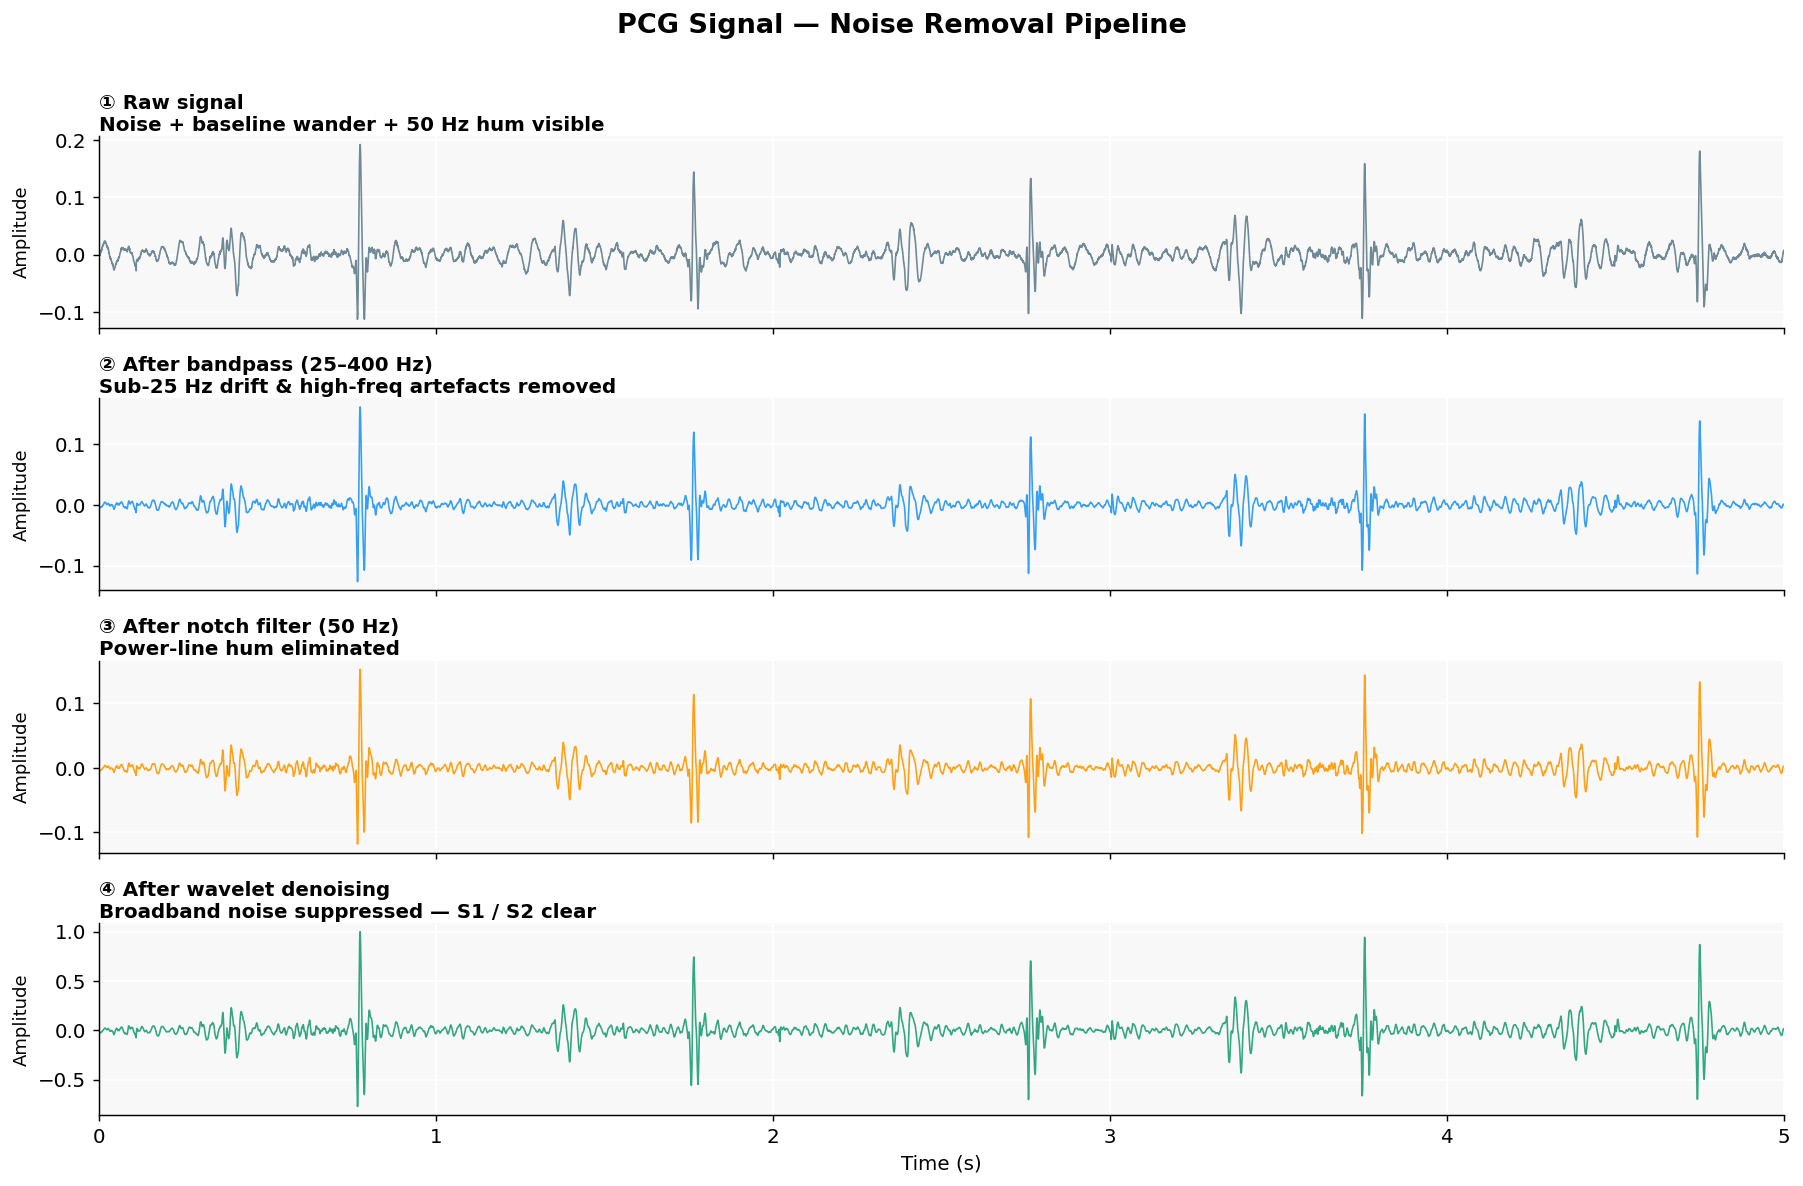

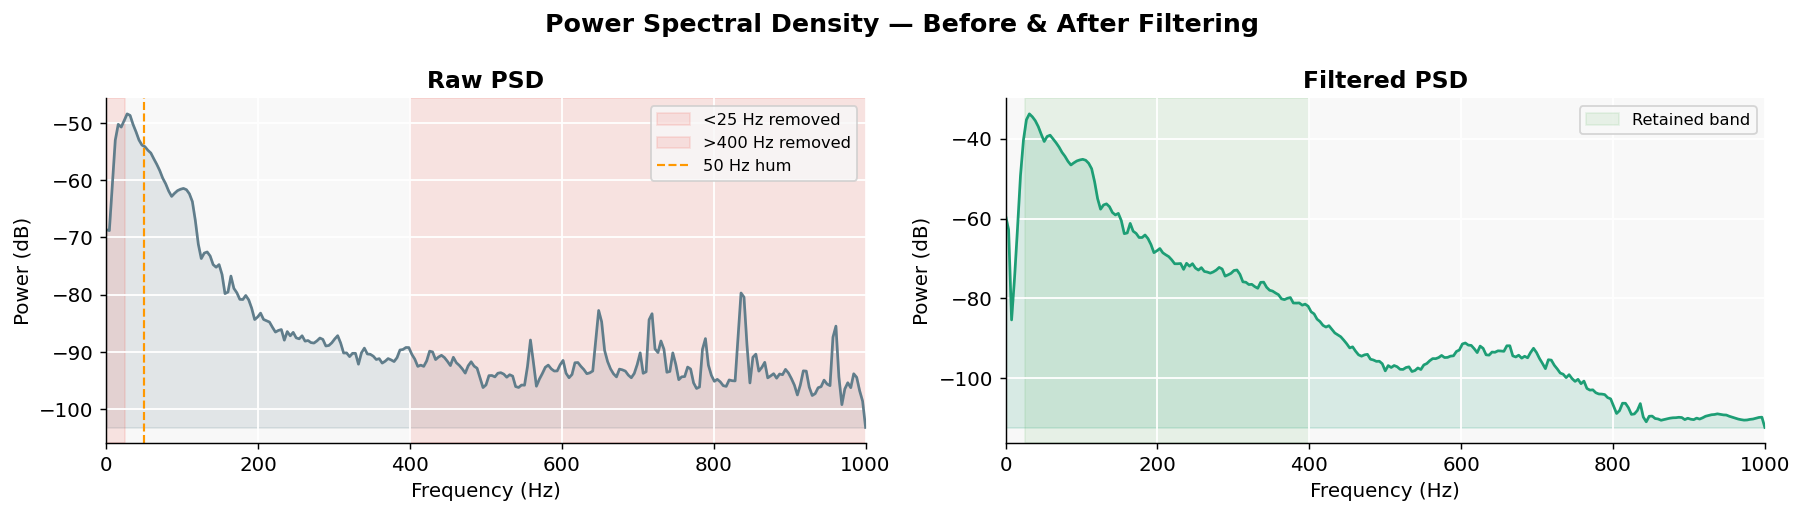

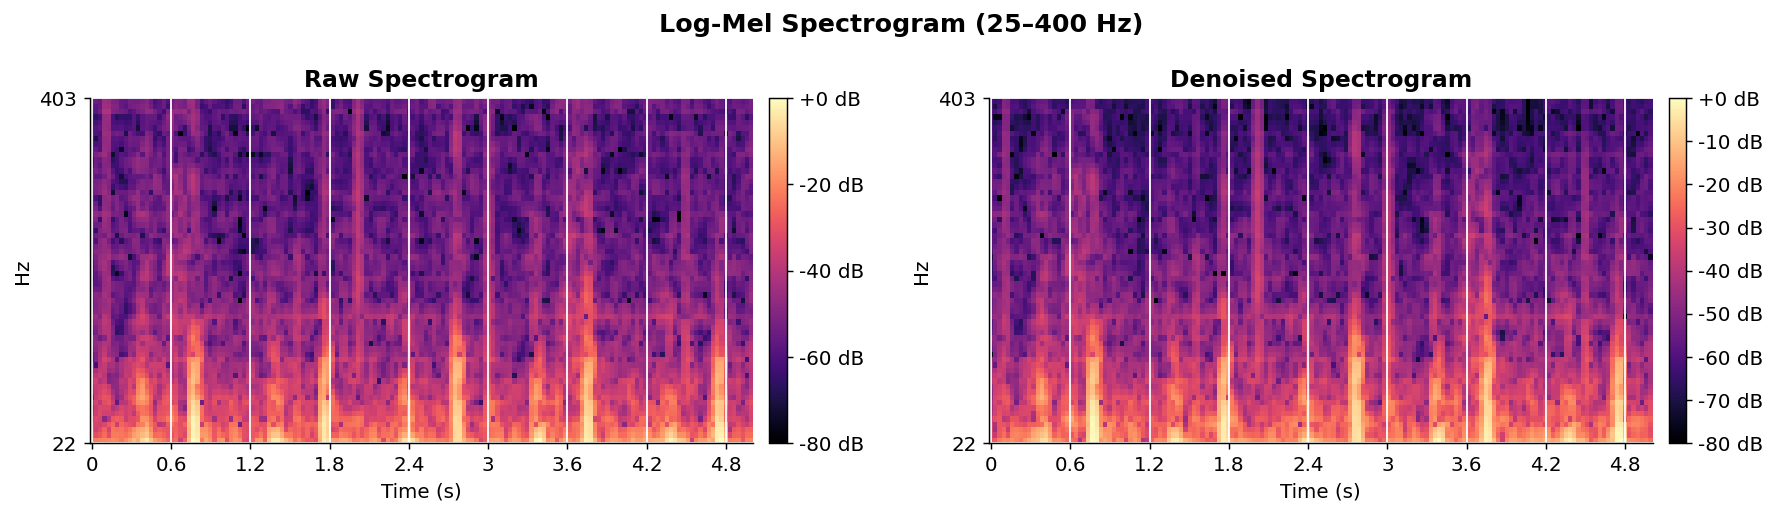

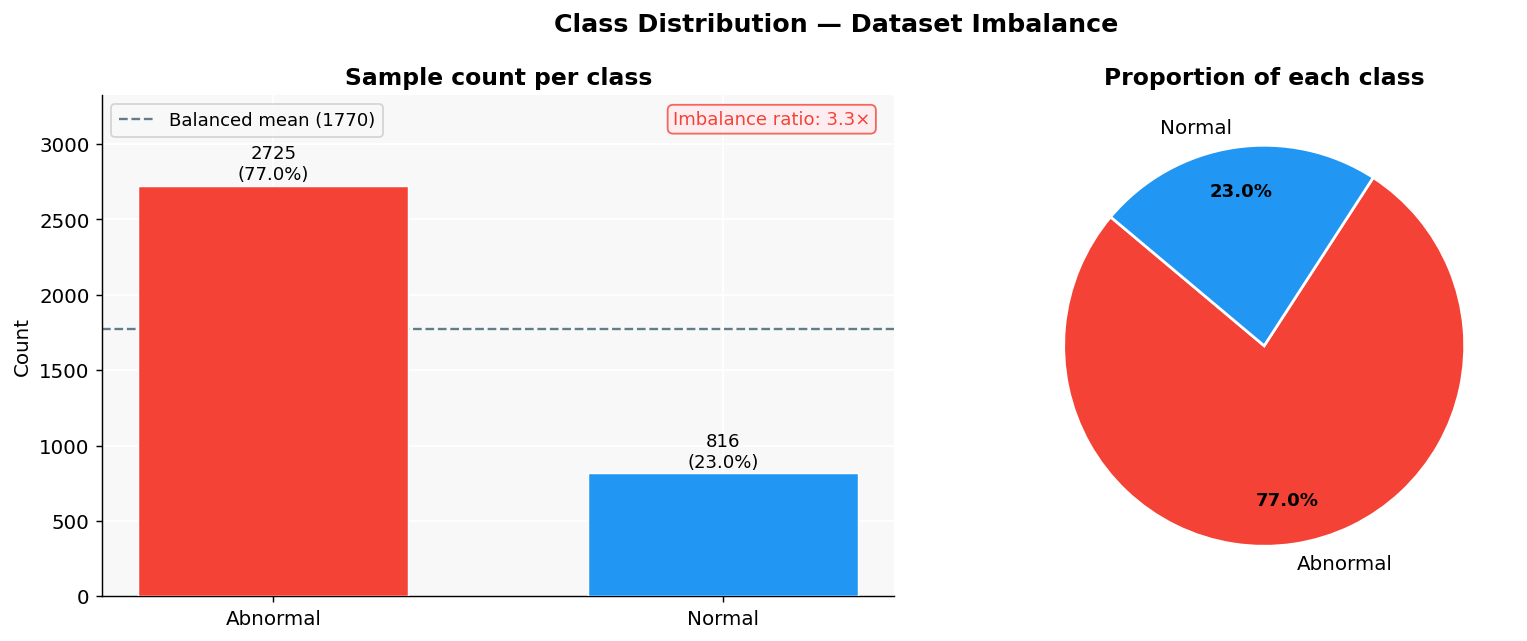

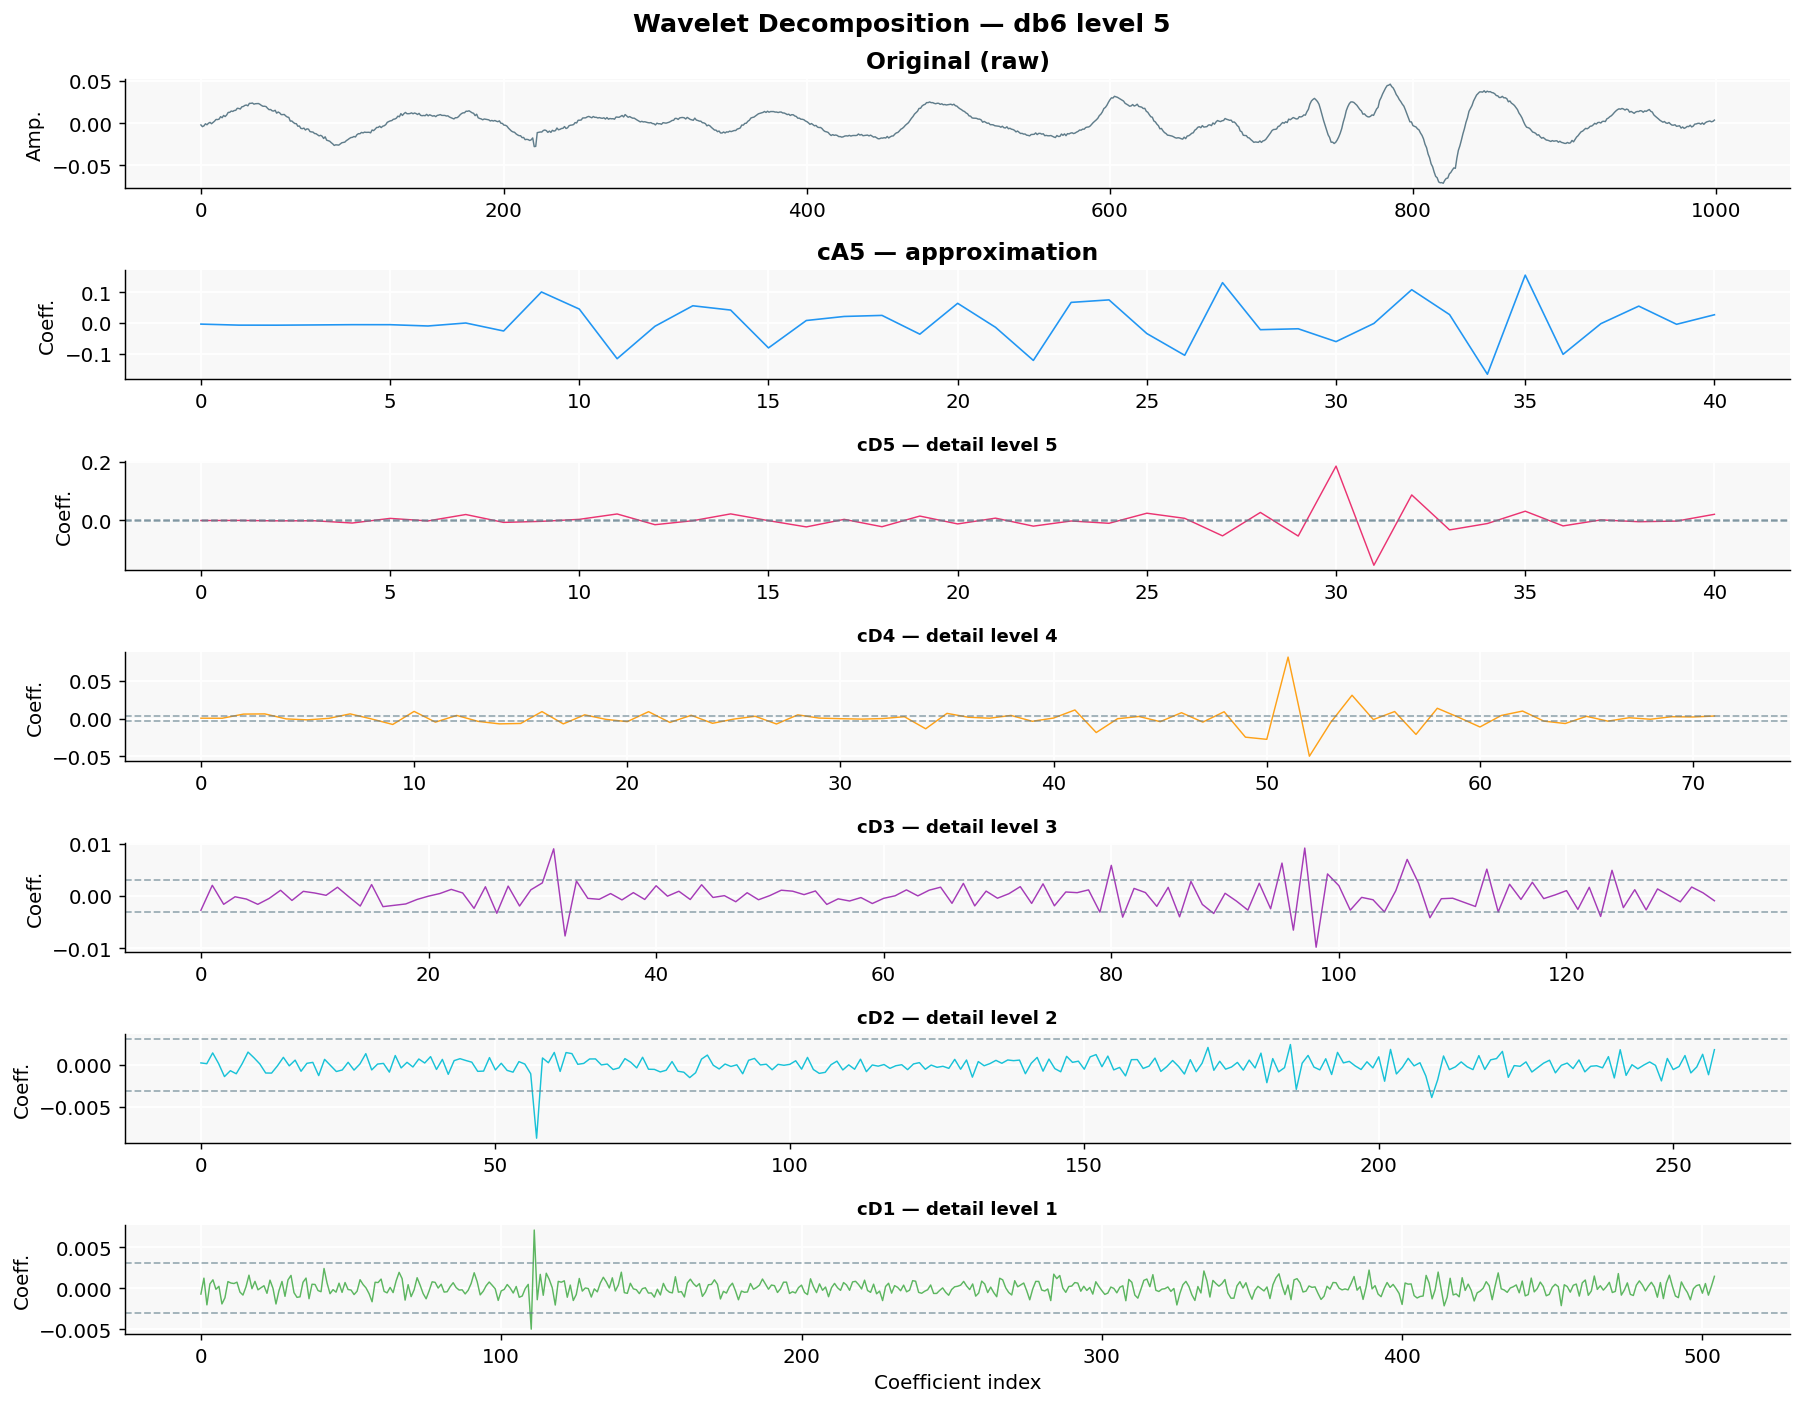

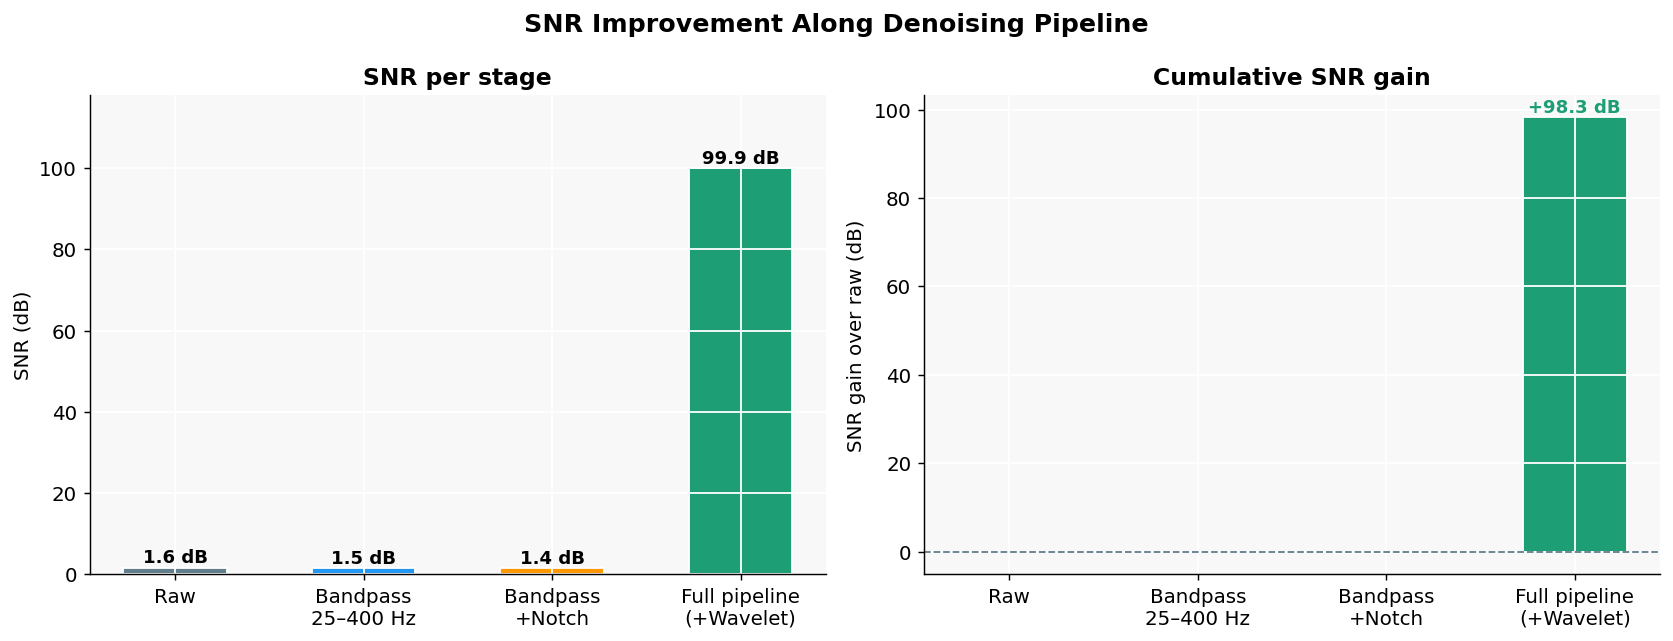

In [27]:
# ── Load Data & Run Signal Visualizations ──────────────────────────────────────────────────────────────
filepaths, labels_enc, label_names, label_counts = load_physionet_dataset(cfg.DATA_DIR)
n_classes = len(set(labels_enc))




# ── Verify label mapping is correct ──────────────────────────────────────────
print(f"\nLabel mapping verification:")
print(f"  Label 0 count : {Counter(labels_enc)[0]}  → should be Abnormal (majority ~2725)")
print(f"  Label 1 count : {Counter(labels_enc)[1]}  → should be Normal   (minority  ~816)")
assert Counter(labels_enc)[0] > Counter(labels_enc)[1], \
    "❌ Label mapping wrong — re-check Cell 11"
print("✅ Label mapping correct\n")




build_cache(filepaths)

# ── Build signal stages from first sample ─────────────────────────────────────
sample_audio, _ = librosa.load(filepaths[0], sr=cfg.SAMPLE_RATE, mono=True)
sample_audio    = pad_or_truncate(sample_audio, cfg.N_SAMPLES)
bp_audio        = butter_bandpass(sample_audio, fs=cfg.SAMPLE_RATE)
notch_audio     = notch_filter(bp_audio, freq=50, fs=cfg.SAMPLE_RATE)
clean_audio     = wavelet_denoise(notch_audio)
clean_audio     = clean_audio / (np.max(np.abs(clean_audio)) + 1e-8)

# ── Signal visualizations ─────────────────────────────────────────────────────
plot_waveform_pipeline(sample_audio, bp_audio, notch_audio, clean_audio)
plot_psd(sample_audio, clean_audio)
plot_mel_spectrograms(sample_audio, clean_audio)
plot_class_distribution(label_counts)
plot_wavelet_decomposition(sample_audio[:1000])
plot_snr(
    clean_ref     = clean_audio,
    stage_signals = [sample_audio, bp_audio, notch_audio, clean_audio],
    stage_names   = ["Raw", "Bandpass\n25–400 Hz", "Bandpass\n+Notch", "Full pipeline\n(+Wavelet)"],
)

#### Noise Removal Visualizations: Normal vs Abnormal

Normal sample   : a0001.wav
Abnormal sample : a0007.wav


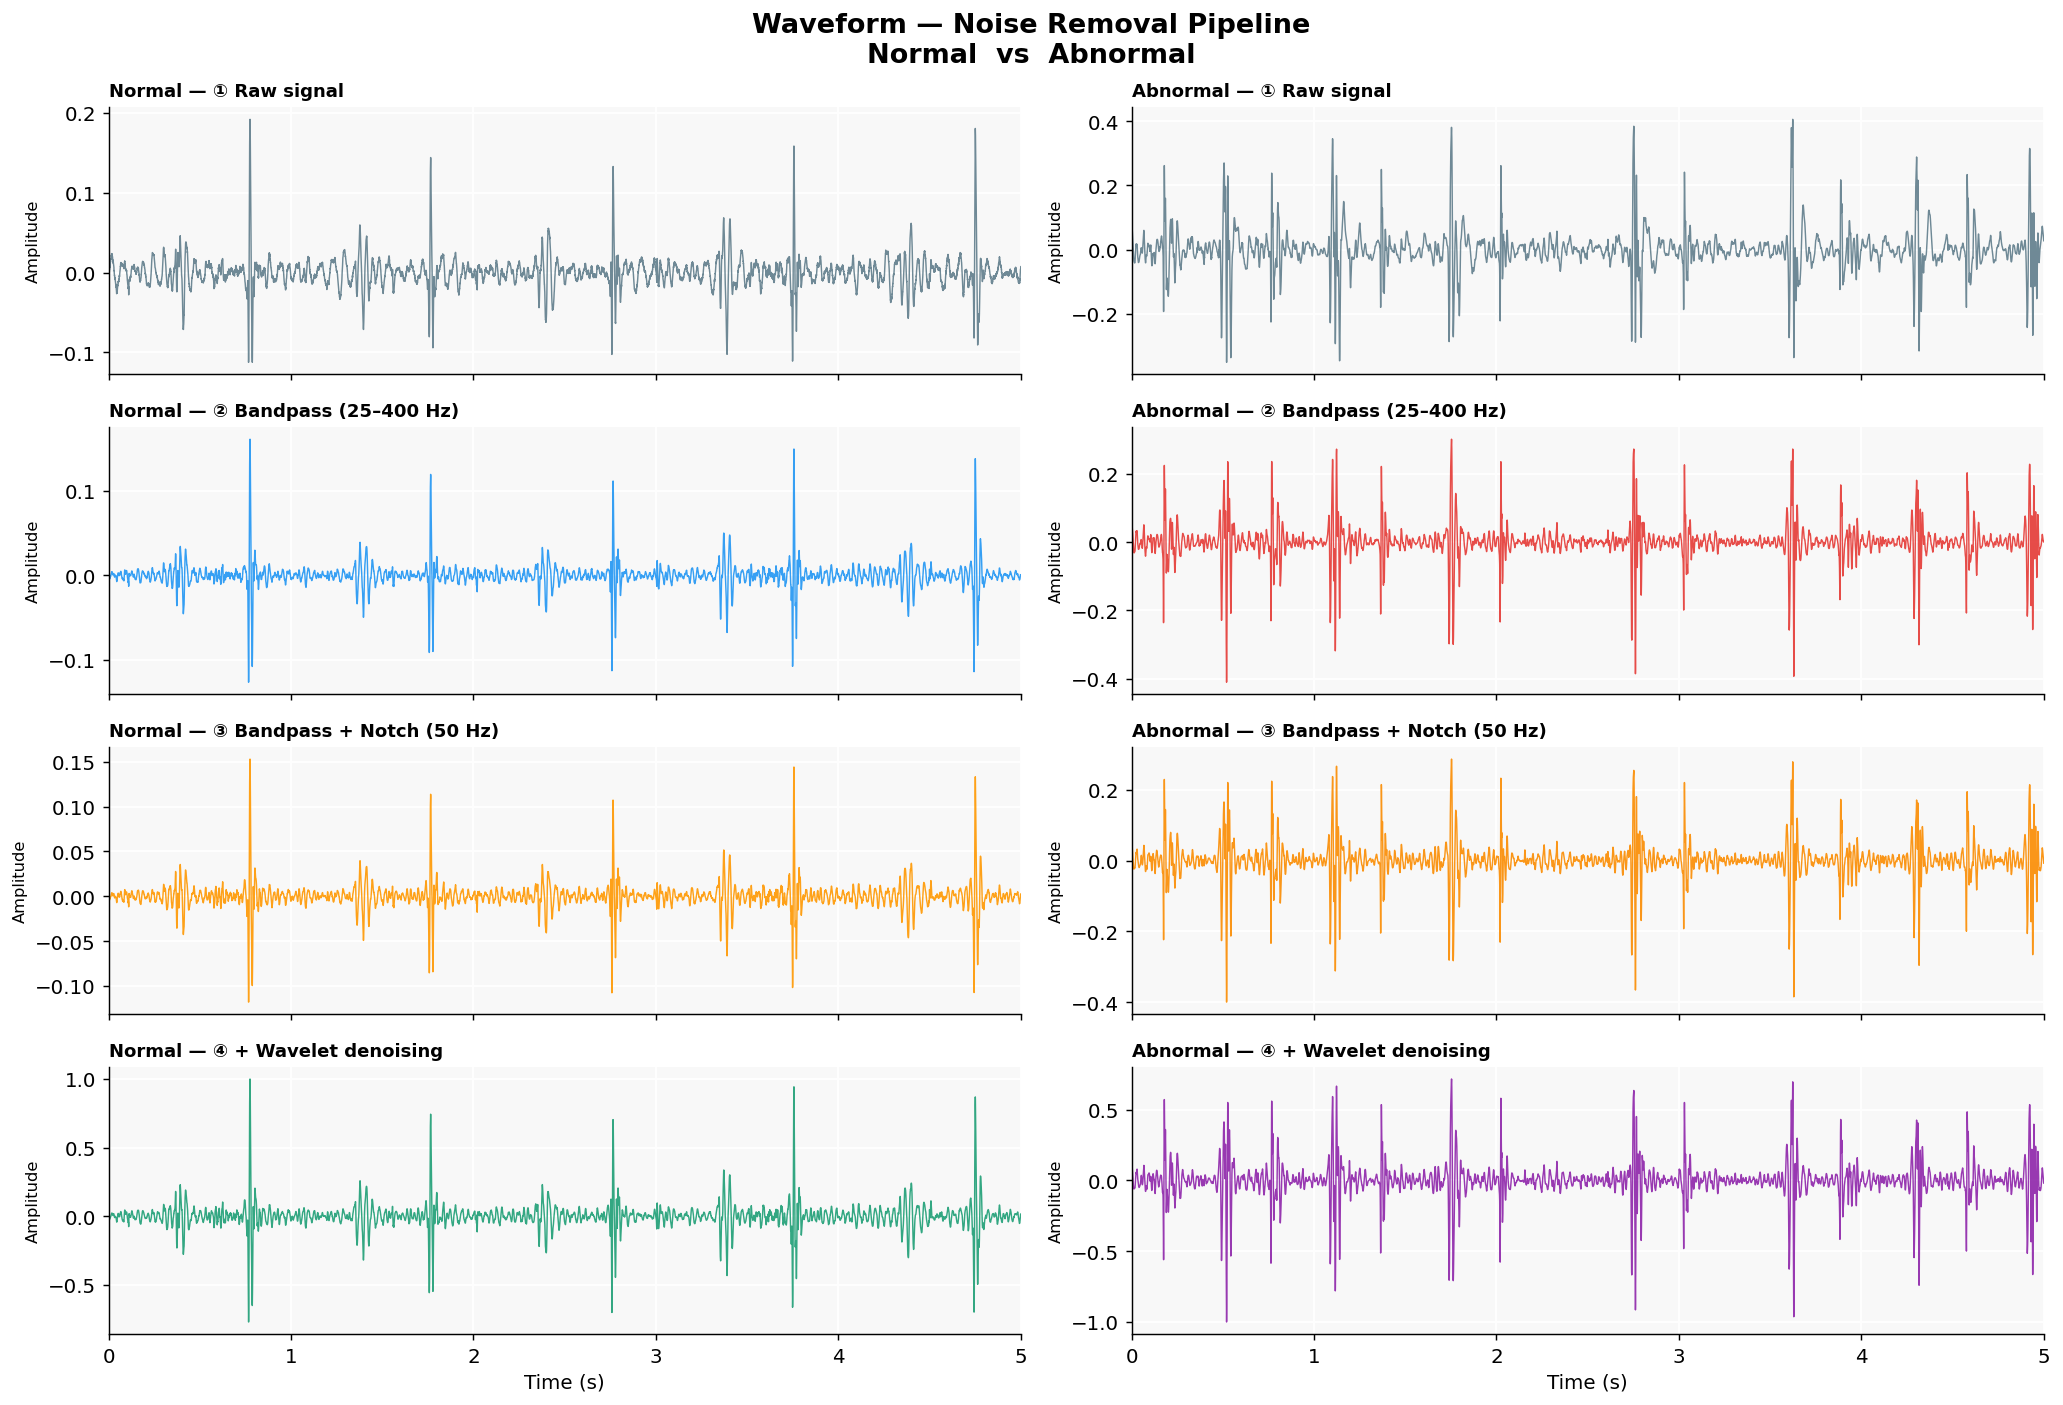

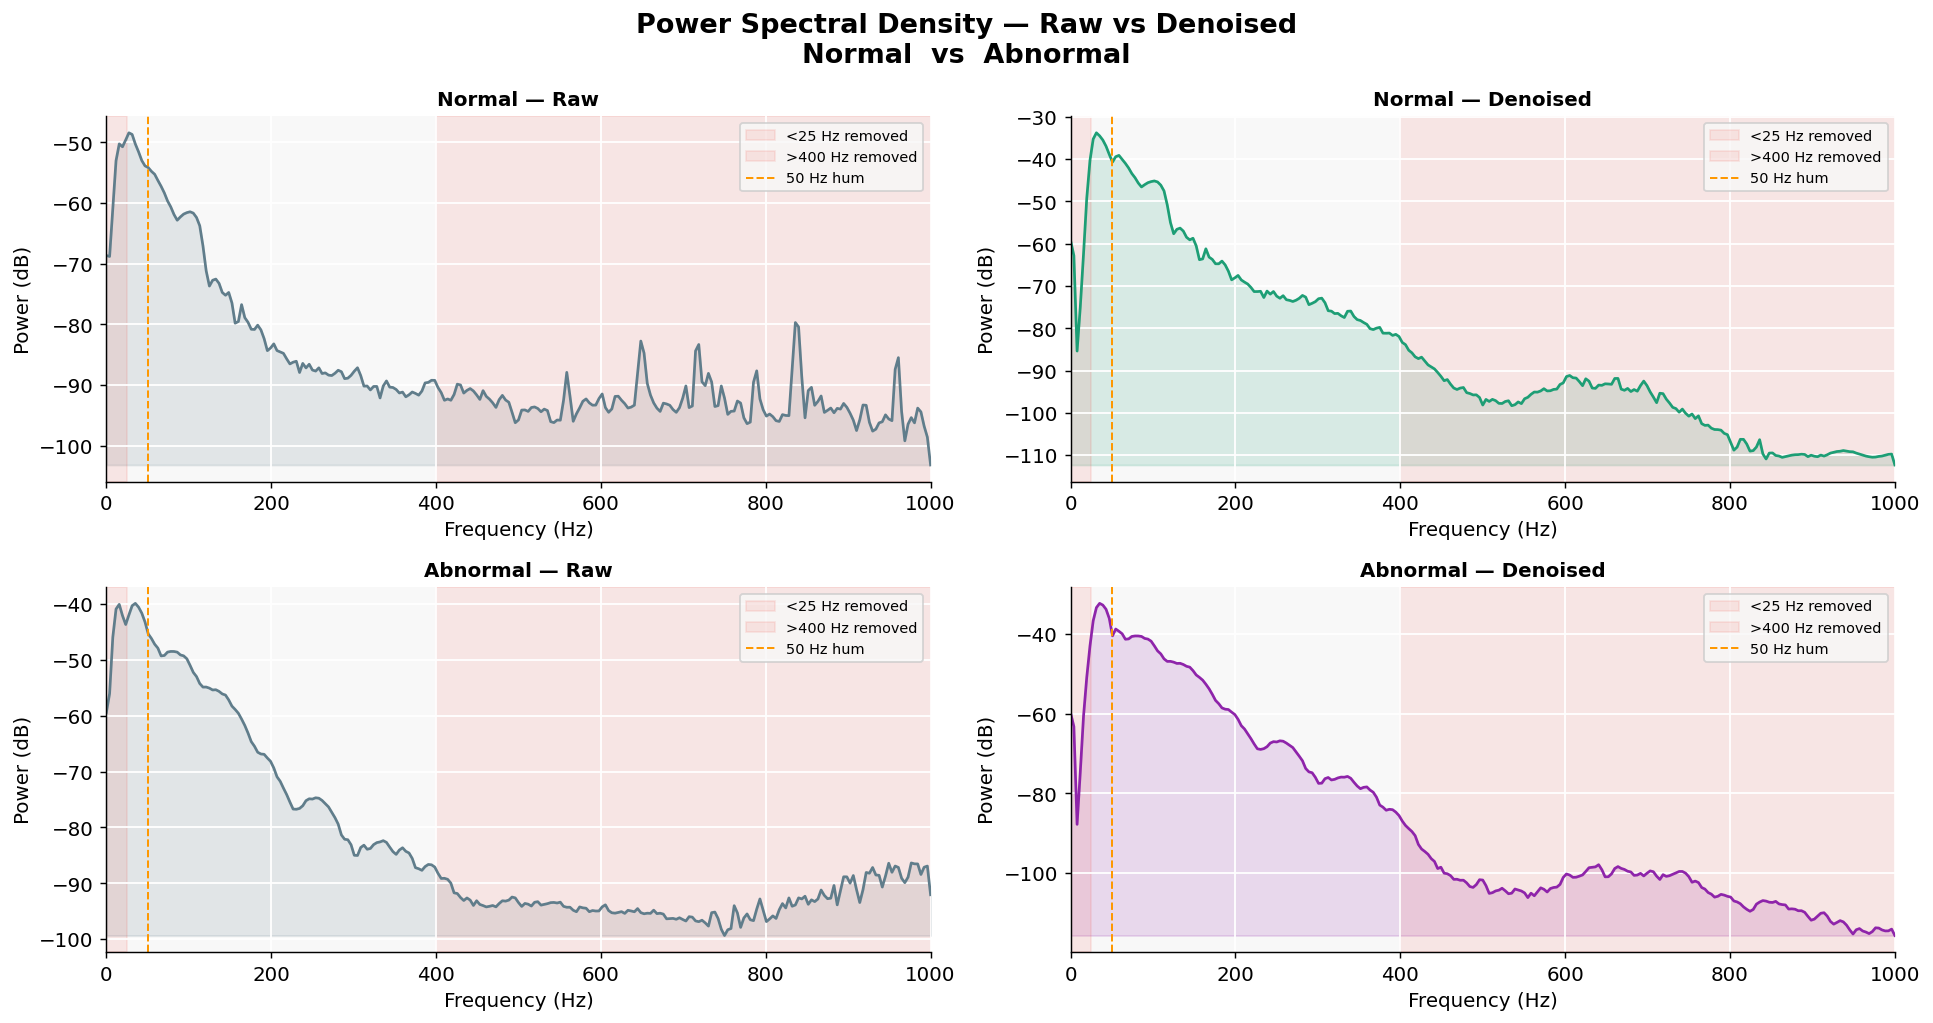

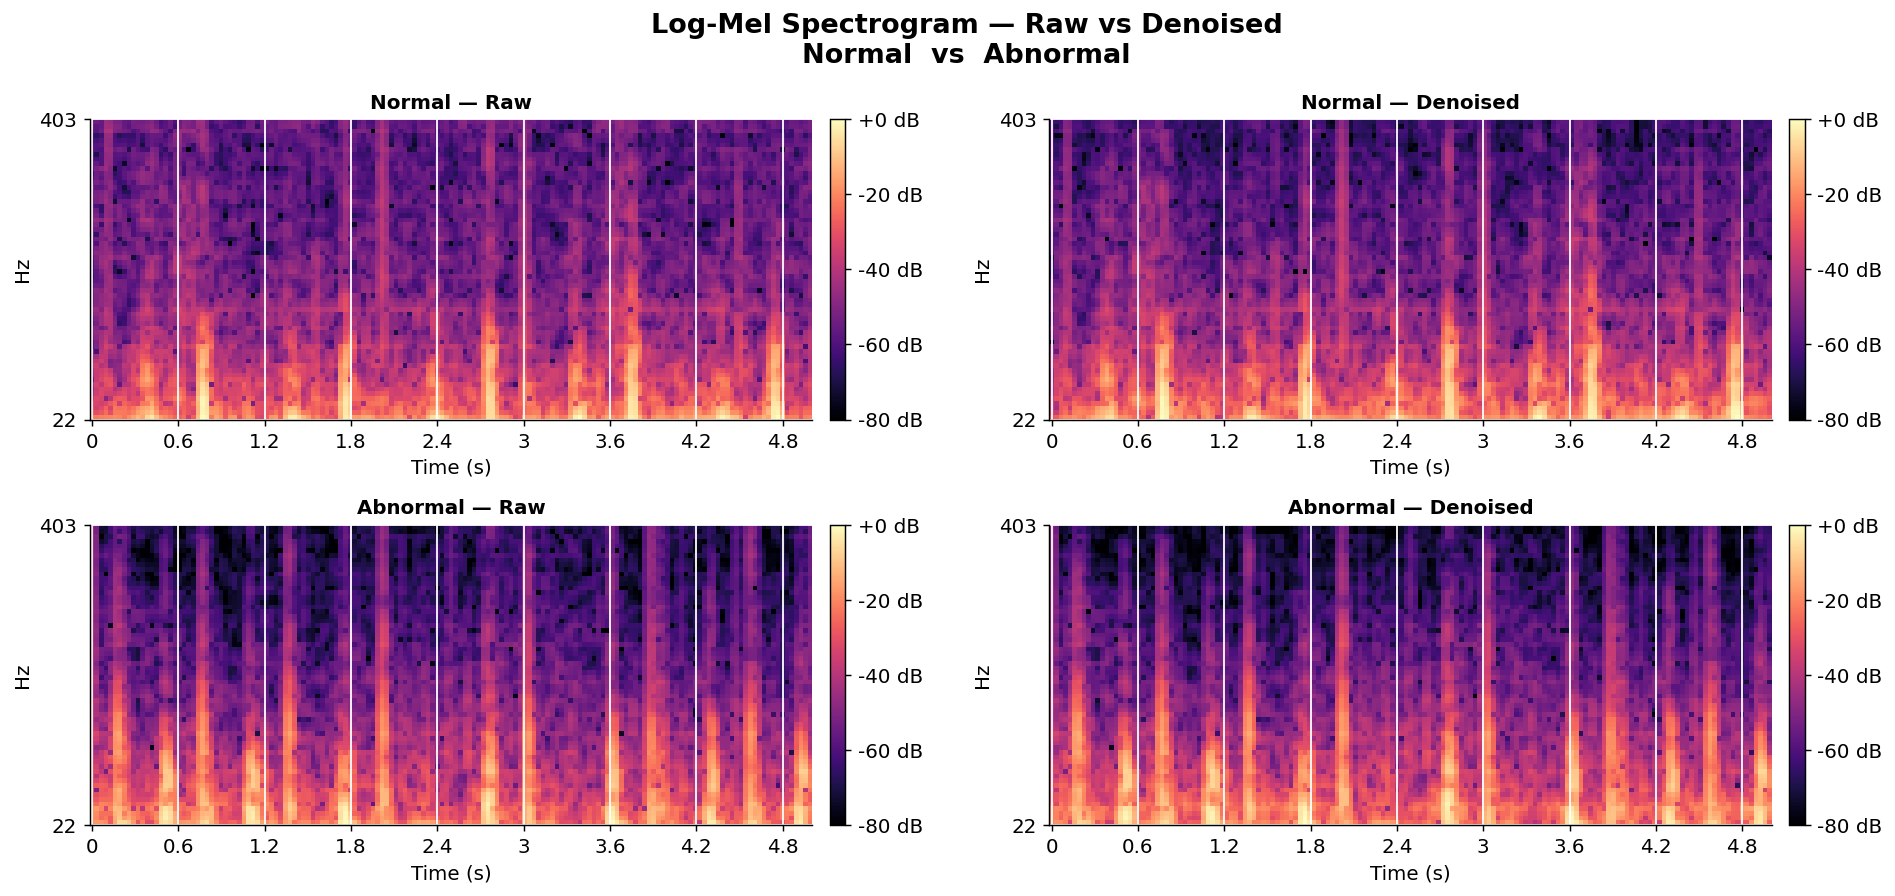

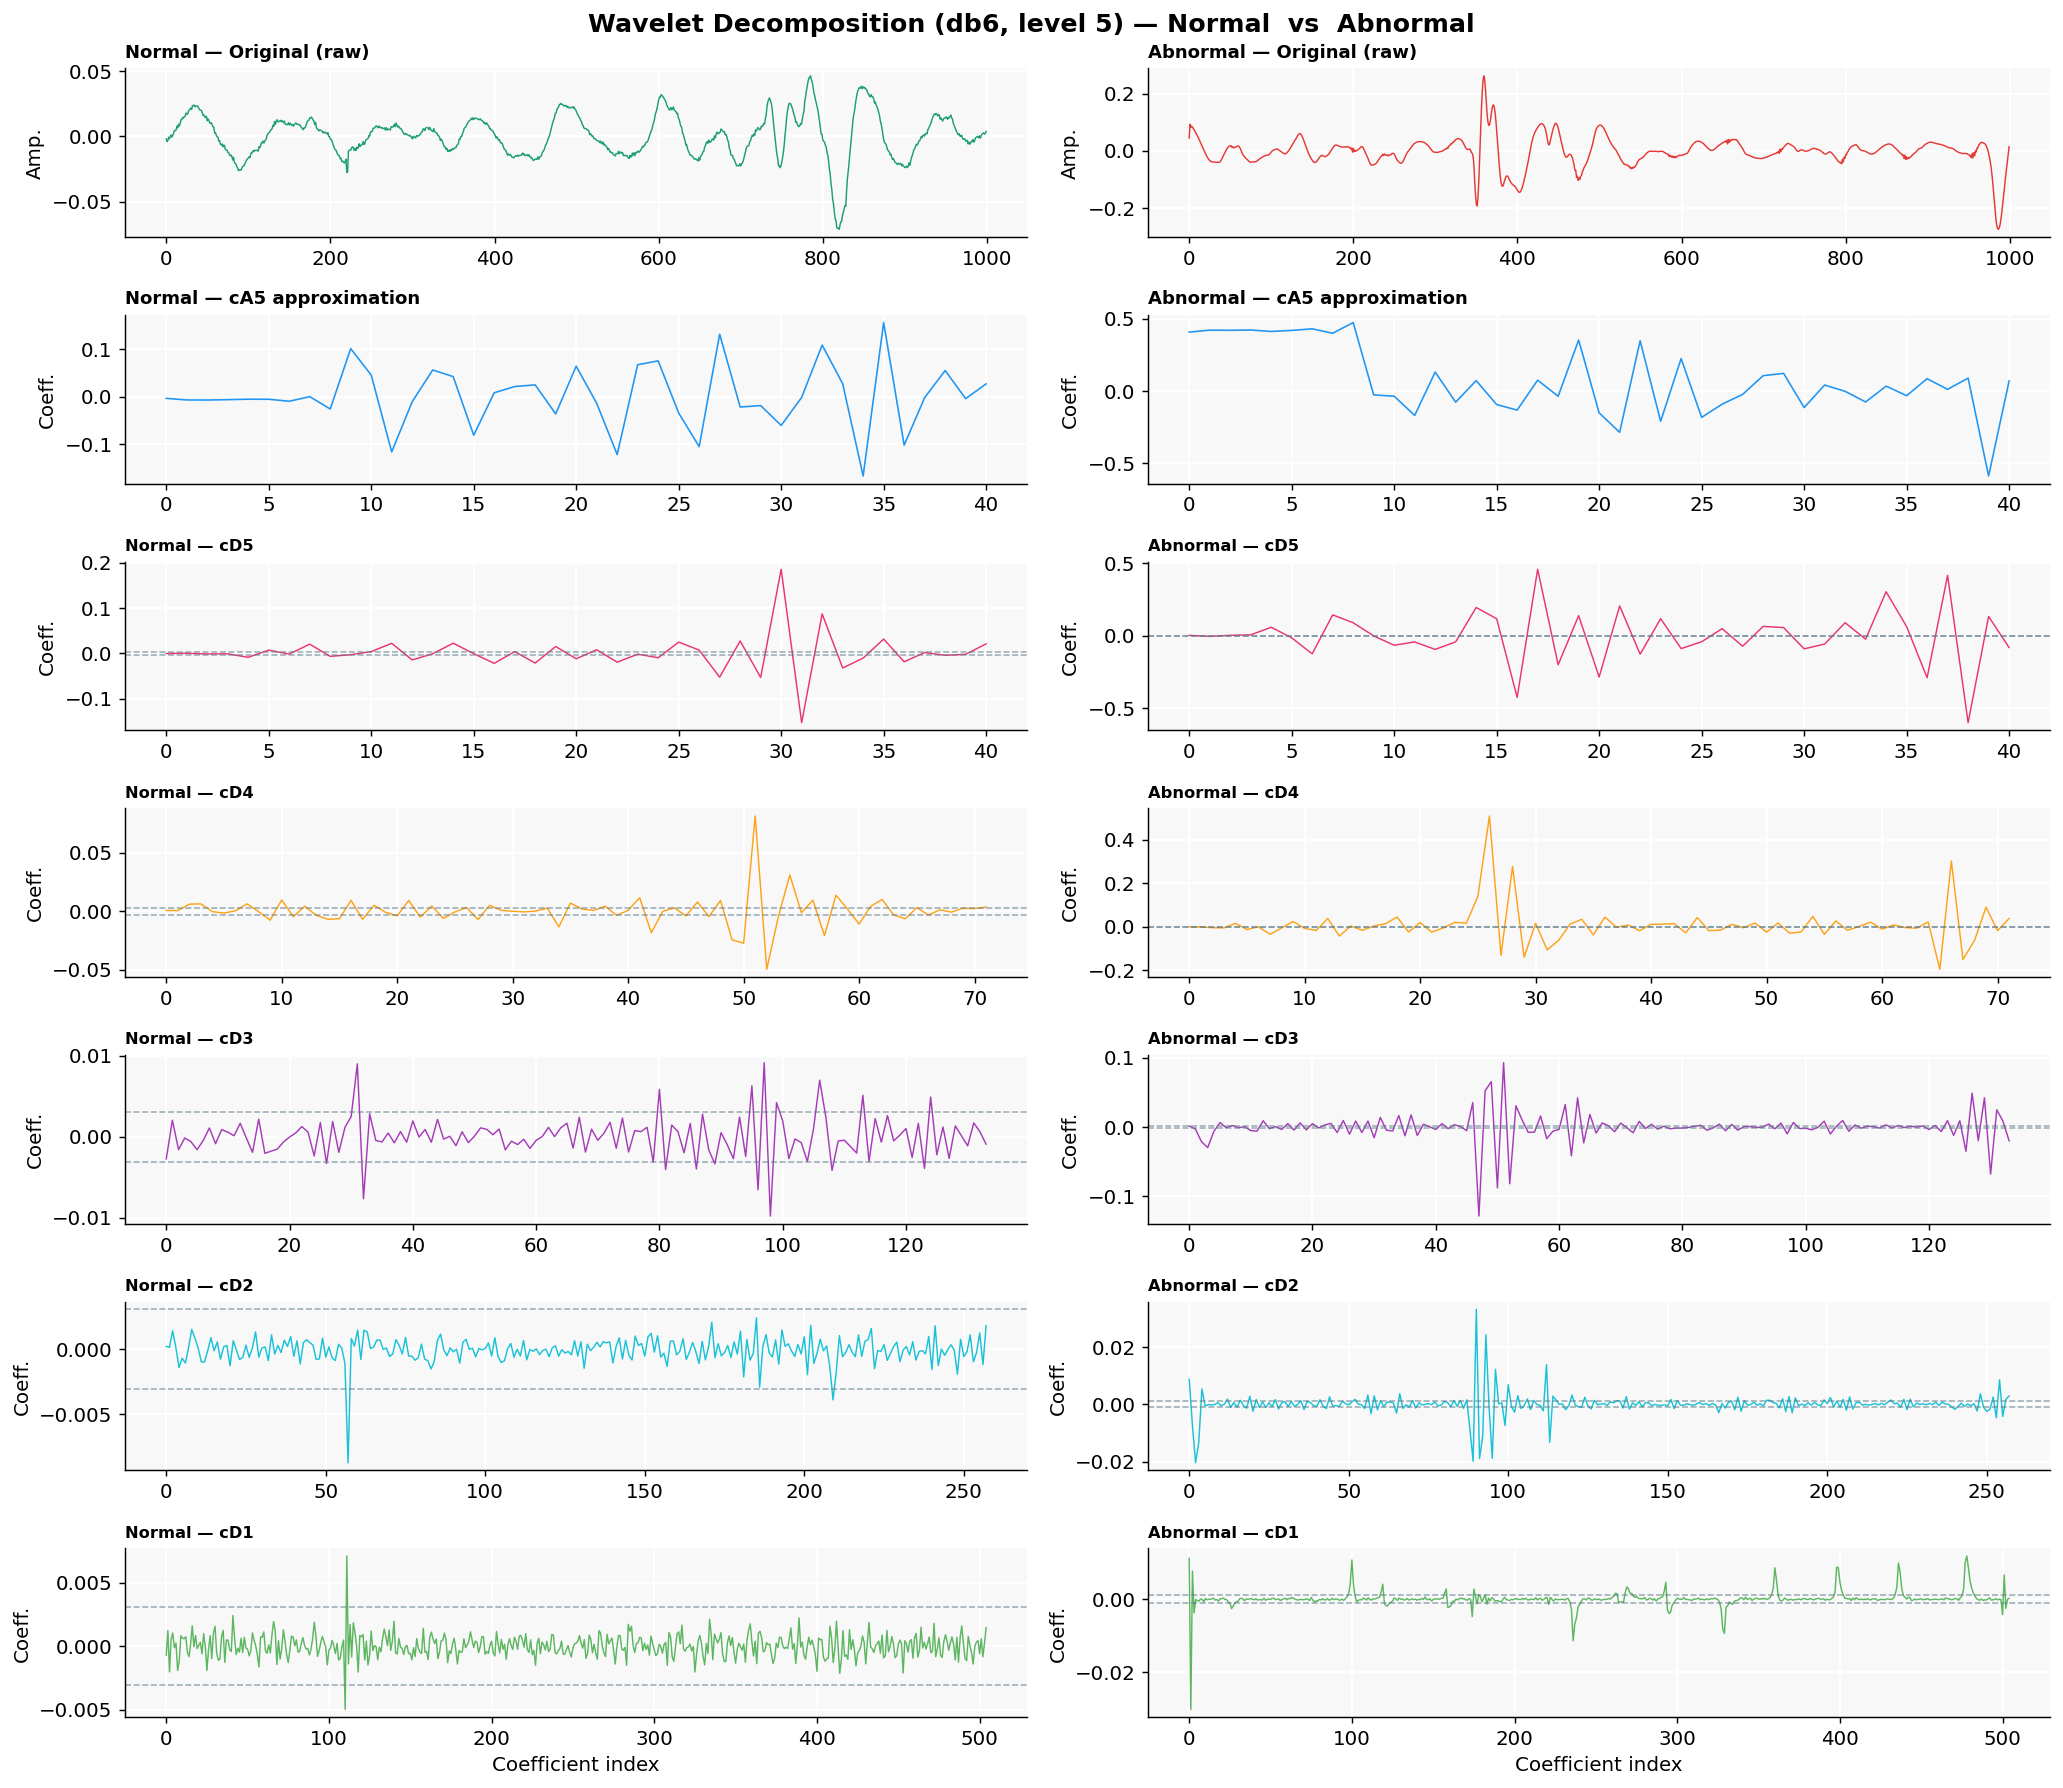

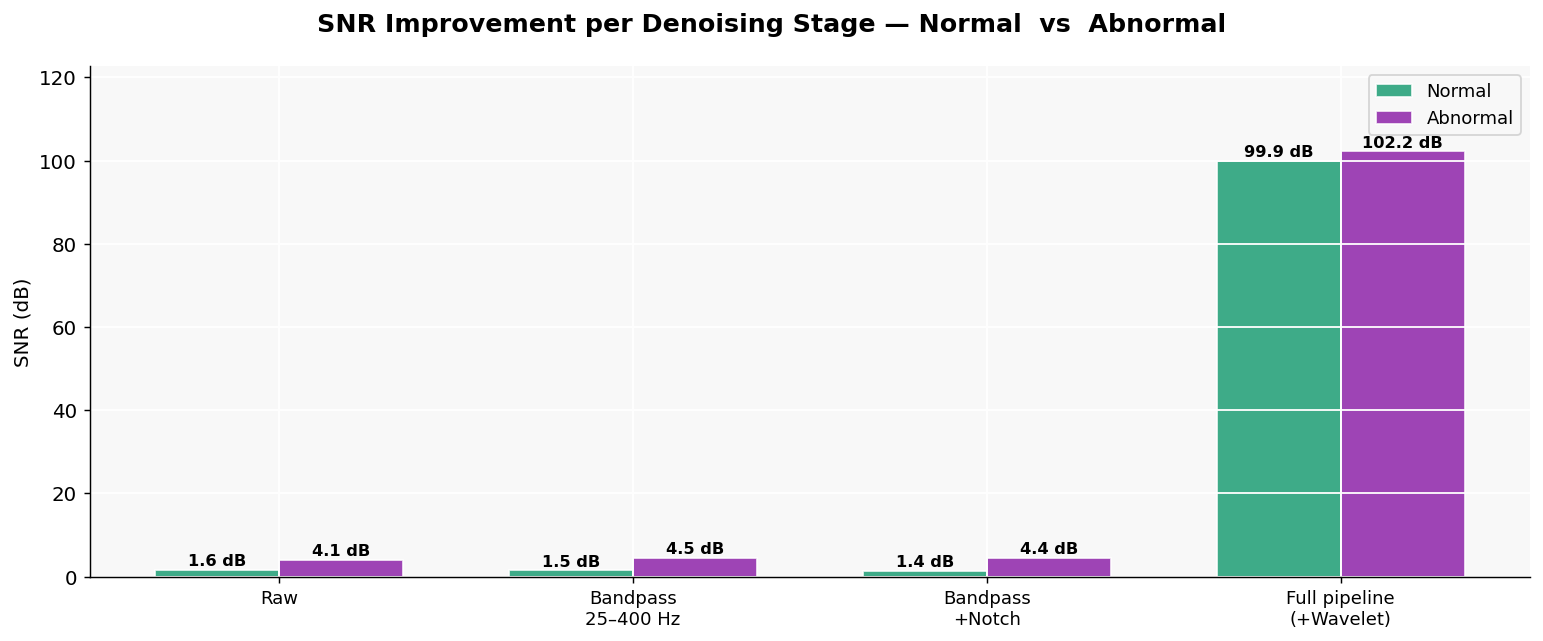

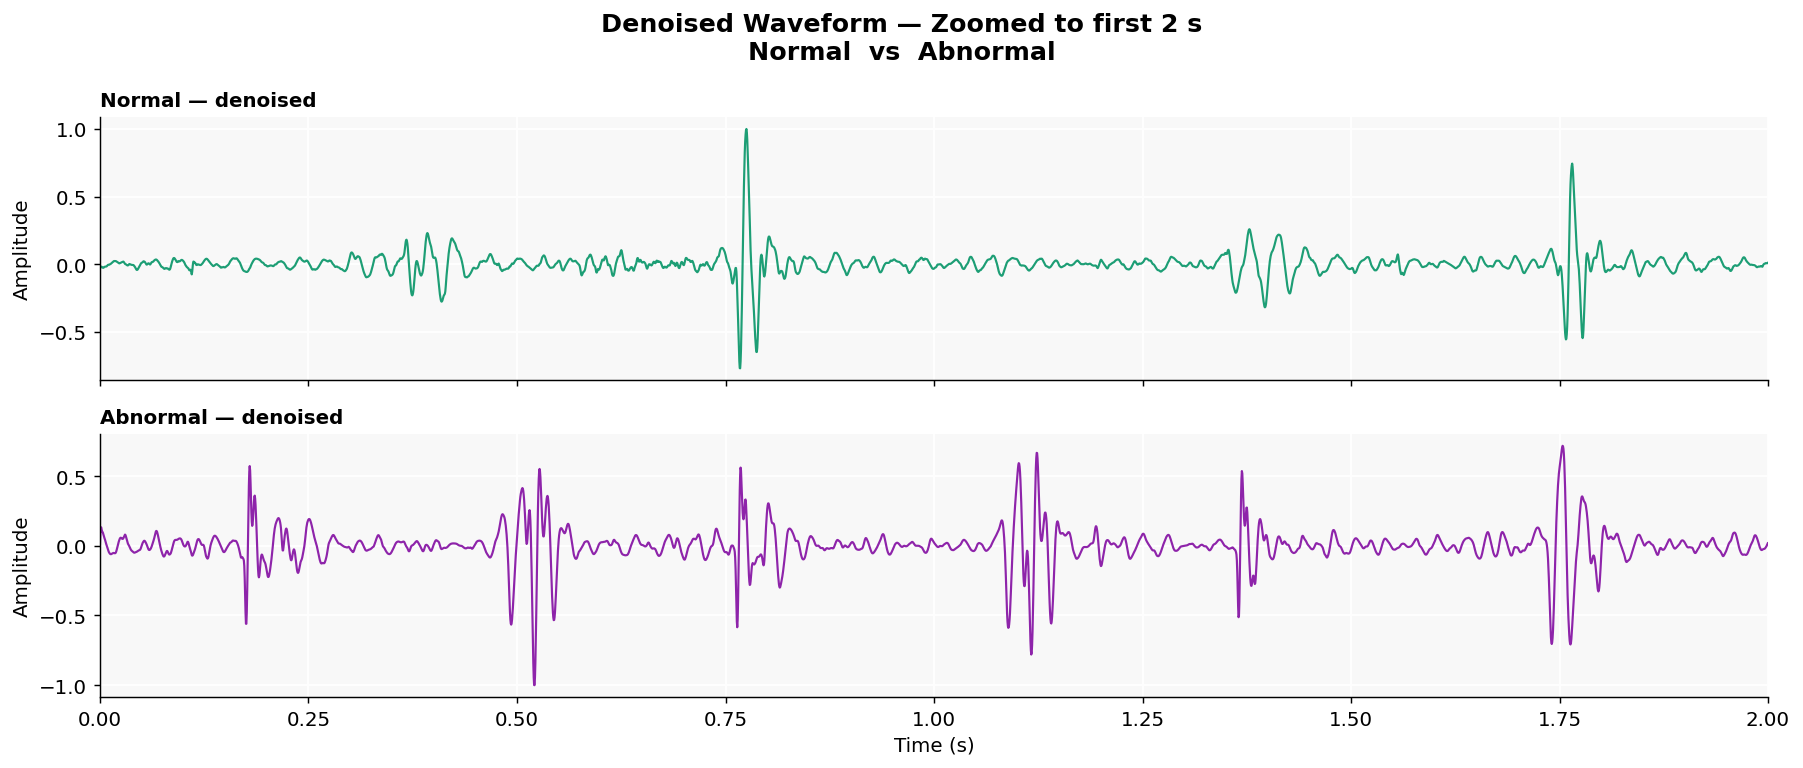


All noise-removal plots saved to ./outputs_new


In [28]:
# ── Pick one Normal and one Abnormal sample ───────────────────────────────────
normal_path   = next(fp for fp, lb in zip(filepaths, labels_enc) if lb == 1)
abnormal_path = next(fp for fp, lb in zip(filepaths, labels_enc) if lb == 0)

def build_stages(filepath):
    """Load a wav and return all four denoising stages."""
    raw, _ = librosa.load(filepath, sr=cfg.SAMPLE_RATE, mono=True)
    raw    = pad_or_truncate(raw, cfg.N_SAMPLES)
    bp     = butter_bandpass(raw,  fs=cfg.SAMPLE_RATE)
    notch  = notch_filter(bp,      freq=50, fs=cfg.SAMPLE_RATE)
    clean  = wavelet_denoise(notch)
    clean  = clean / (np.max(np.abs(clean)) + 1e-8)
    return raw, bp, notch, clean

raw_n, bp_n, notch_n, clean_n = build_stages(normal_path)
raw_a, bp_a, notch_a, clean_a = build_stages(abnormal_path)

SR = cfg.SAMPLE_RATE
t  = np.linspace(0, cfg.CLIP_DURATION, cfg.N_SAMPLES)

STAGE_LABELS   = [
    "① Raw signal",
    "② Bandpass (25–400 Hz)",
    "③ Bandpass + Notch (50 Hz)",
    "④ + Wavelet denoising",
]
STAGE_COLORS_N = ["#607D8B", "#2196F3", "#FF9800", "#1D9E75"]
STAGE_COLORS_A = ["#607D8B", "#E53935", "#FB8C00", "#8E24AA"]

print(f"Normal sample   : {os.path.basename(normal_path)}")
print(f"Abnormal sample : {os.path.basename(abnormal_path)}")


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 1 — Waveforms: all 4 stages, Normal (left) vs Abnormal (right)
# ════════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True)
fig.suptitle("Waveform — Noise Removal Pipeline\nNormal  vs  Abnormal",
             fontsize=15, fontweight="bold")

for row, (sn, sa, label, cn, ca) in enumerate(
        zip([raw_n, bp_n, notch_n, clean_n],
            [raw_a, bp_a, notch_a, clean_a],
            STAGE_LABELS, STAGE_COLORS_N, STAGE_COLORS_A)):
    for ax, sig, col, title in [
        (axes[row, 0], sn, cn, f"Normal — {label}"),
        (axes[row, 1], sa, ca, f"Abnormal — {label}"),
    ]:
        ax.plot(t, sig, color=col, linewidth=0.8, alpha=0.9)
        ax.set_title(title, fontsize=10, loc="left")
        ax.set_ylabel("Amplitude", fontsize=9)
        ax.set_xlim(0, cfg.CLIP_DURATION)

for ax in axes[-1]:
    ax.set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_01_waveforms.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 2 — Power Spectral Density: Raw vs Clean, Normal vs Abnormal
# ════════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
fig.suptitle("Power Spectral Density — Raw vs Denoised\nNormal  vs  Abnormal",
             fontsize=15, fontweight="bold")

for ax, sig, col, title in [
    (axes[0, 0], raw_n,   "#607D8B", "Normal — Raw"),
    (axes[0, 1], clean_n, "#1D9E75", "Normal — Denoised"),
    (axes[1, 0], raw_a,   "#607D8B", "Abnormal — Raw"),
    (axes[1, 1], clean_a, "#8E24AA", "Abnormal — Denoised"),
]:
    f, p = welch(sig, fs=SR, nperseg=512)
    pdb  = 10 * np.log10(p + 1e-12)
    ax.plot(f, pdb, color=col, linewidth=1.5)
    ax.fill_between(f, pdb, pdb.min(), alpha=0.15, color=col)
    ax.axvspan(0,   25,    alpha=0.10, color="#F44336", label="<25 Hz removed")
    ax.axvspan(400, SR//2, alpha=0.10, color="#F44336", label=">400 Hz removed")
    ax.axvline(50, color="#FF9800", linestyle="--", linewidth=1.1, label="50 Hz hum")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (dB)")
    ax.set_xlim(0, SR // 2); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_02_psd.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 3 — Log-Mel Spectrograms: Raw vs Clean, Normal vs Abnormal
# ════════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
fig.suptitle("Log-Mel Spectrogram — Raw vs Denoised\nNormal  vs  Abnormal",
             fontsize=15, fontweight="bold")

for ax, sig, title in [
    (axes[0, 0], raw_n,   "Normal — Raw"),
    (axes[0, 1], clean_n, "Normal — Denoised"),
    (axes[1, 0], raw_a,   "Abnormal — Raw"),
    (axes[1, 1], clean_a, "Abnormal — Denoised"),
]:
    mel = librosa.feature.melspectrogram(
        y=sig, sr=SR, n_fft=256, hop_length=64,
        n_mels=64, fmin=25, fmax=400)
    img = librosa.display.specshow(
        librosa.power_to_db(mel, ref=np.max),
        sr=SR, hop_length=64, fmin=25, fmax=400,
        x_axis="time", y_axis="mel", ax=ax, cmap="magma")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Time (s)")
    fig.colorbar(img, ax=ax, format="%+2.0f dB", pad=0.02)

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_03_mel_spectrogram.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 4 — Wavelet Decomposition: Normal vs Abnormal
# ════════════════════════════════════════════════════════════════════════════════
def wavelet_decomp_axes(axes_col, signal_segment, title_prefix, header_col):
    wavelet = "db6"; level = 5
    coeffs    = pywt.wavedec(signal_segment, wavelet, level=level)
    sigma     = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(signal_segment) + 1e-8))
    detail_colors = ["#E91E63", "#FF9800", "#9C27B0", "#00BCD4", "#4CAF50"]
    axes_col[0].plot(signal_segment, color=header_col, linewidth=0.8)
    axes_col[0].set_title(f"{title_prefix} — Original (raw)", fontsize=10, loc="left")
    axes_col[0].set_ylabel("Amp.")
    axes_col[1].plot(coeffs[0], color="#2196F3", linewidth=0.9)
    axes_col[1].set_title(f"{title_prefix} — cA5 approximation", fontsize=10, loc="left")
    axes_col[1].set_ylabel("Coeff.")
    for i, (d, col) in enumerate(zip(coeffs[1:], detail_colors)):
        ax = axes_col[i + 2]
        ax.plot(d, color=col, linewidth=0.8, alpha=0.9)
        ax.axhline( threshold, color="#607D8B", linestyle="--", linewidth=0.9, alpha=0.6)
        ax.axhline(-threshold, color="#607D8B", linestyle="--", linewidth=0.9, alpha=0.6)
        ax.set_title(f"{title_prefix} — cD{level - i}", fontsize=9, loc="left")
        ax.set_ylabel("Coeff.")
    axes_col[-1].set_xlabel("Coefficient index")

fig, axes = plt.subplots(7, 2, figsize=(16, 14))
fig.suptitle("Wavelet Decomposition (db6, level 5) — Normal  vs  Abnormal",
             fontsize=14, fontweight="bold")
wavelet_decomp_axes(axes[:, 0], raw_n[:1000], "Normal",   "#1D9E75")
wavelet_decomp_axes(axes[:, 1], raw_a[:1000], "Abnormal", "#E53935")
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_04_wavelet_decomposition.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 5 — SNR improvement: Normal vs Abnormal grouped bar
# ════════════════════════════════════════════════════════════════════════════════
stage_names = ["Raw", "Bandpass\n25–400 Hz", "Bandpass\n+Notch", "Full pipeline\n(+Wavelet)"]

snr_n = [snr_db(clean_n, s) for s in [raw_n, bp_n, notch_n, clean_n]]
snr_a = [snr_db(clean_a, s) for s in [raw_a, bp_a, notch_a, clean_a]]

x = np.arange(len(stage_names)); w = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle("SNR Improvement per Denoising Stage — Normal  vs  Abnormal",
             fontsize=14, fontweight="bold")

bars_n = ax.bar(x - w/2, snr_n, w, color="#1D9E75", alpha=0.85,
                edgecolor="white", label="Normal")
bars_a = ax.bar(x + w/2, snr_a, w, color="#8E24AA", alpha=0.85,
                edgecolor="white", label="Abnormal")
for bar, v in list(zip(bars_n, snr_n)) + list(zip(bars_a, snr_a)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3, f"{v:.1f} dB",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(stage_names, fontsize=10)
ax.set_ylabel("SNR (dB)"); ax.legend()
ax.set_ylim(0, max(snr_n + snr_a) * 1.20)
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_05_snr_improvement.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 6 — Zoomed clean waveform: Normal vs Abnormal
# ════════════════════════════════════════════════════════════════════════════════
zoom_n = int(2.0 * SR)
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
fig.suptitle("Denoised Waveform — Zoomed to first 2 s\nNormal  vs  Abnormal",
             fontsize=14, fontweight="bold")
axes[0].plot(t[:zoom_n], clean_n[:zoom_n], color="#1D9E75", linewidth=1.2)
axes[0].set_title("Normal — denoised", fontsize=11, loc="left")
axes[0].set_ylabel("Amplitude")
axes[1].plot(t[:zoom_n], clean_a[:zoom_n], color="#8E24AA", linewidth=1.2)
axes[1].set_title("Abnormal — denoised", fontsize=11, loc="left")
axes[1].set_ylabel("Amplitude"); axes[1].set_xlabel("Time (s)")
for ax in axes:
    ax.set_xlim(0, 2.0)
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "NR_06_zoomed_clean.png"), bbox_inches="tight")
plt.show()

print("\nAll noise-removal plots saved to", cfg.OUTPUT_DIR)

#### Diagnose fold splits before training

In [29]:

skf = StratifiedKFold(n_splits=cfg.N_FOLDS, shuffle=True, random_state=cfg.SEED)

print(f"Total samples : {len(labels_enc)}")
print(f"Label counts  : {Counter(labels_enc)}")
print(f"Positive rate : {sum(labels_enc)/len(labels_enc):.3f}\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(filepaths, labels_enc)):
    tr_lbs = [labels_enc[i] for i in train_idx]
    vl_lbs = [labels_enc[i] for i in val_idx]
    tr_pos = sum(tr_lbs) / len(tr_lbs)
    vl_pos = sum(vl_lbs) / len(vl_lbs)
    print(f"Fold {fold+1} | "
          f"Train: {len(tr_lbs)} samples  pos={tr_pos:.3f} | "
          f"Val: {len(vl_lbs)} samples  pos={vl_pos:.3f}")

Total samples : 3541
Label counts  : Counter({0: 2725, 1: 816})
Positive rate : 0.230

Fold 1 | Train: 2832 samples  pos=0.230 | Val: 709 samples  pos=0.231
Fold 2 | Train: 2833 samples  pos=0.230 | Val: 708 samples  pos=0.230
Fold 3 | Train: 2833 samples  pos=0.230 | Val: 708 samples  pos=0.230
Fold 4 | Train: 2833 samples  pos=0.230 | Val: 708 samples  pos=0.230
Fold 5 | Train: 2833 samples  pos=0.230 | Val: 708 samples  pos=0.230


#### corrected diagnostic (use full labels_enc)

In [30]:
# ── class weights on full dataset ─────────────────────────────────────────────
w = compute_class_weights(labels_enc)
print(f"\nFull dataset class weights:")
print(f"  Abnormal (0, n={Counter(labels_enc)[0]}) → weight {w[0]:.4f}  (should be < 1.0)")
print(f"  Normal   (1, n={Counter(labels_enc)[1]}) → weight {w[1]:.4f}  (should be > 1.0)")

assert w[1] > w[0], "Weights inverted — minority class must have higher weight"
print("Class weights correct\n")

# ── sampler on full dataset ───────────────────────────────────────────────────
sampler = make_weighted_sampler(labels_enc)
print(f"Sampler num_samples : {sampler.num_samples}")
print(f"Expected            : {2 * Counter(labels_enc)[1] * 2}  "
      f"(2 × minority × n_classes)")

# ── simulate 5 batches and check average distribution ─────────────────────────
subset = Subset(
    HeartSoundDataset(filepaths, labels_enc, augment=False),
    range(min(500, len(filepaths)))   # use first 500 for speed
)
loader = DataLoader(
    subset, batch_size=32,
    sampler=make_weighted_sampler(labels_enc[:min(500, len(filepaths))])
)
batch_labels = []
for i, (_, lbs) in enumerate(loader):
    batch_labels.extend(lbs.tolist())
    if i >= 4: break   # check 5 batches only

c = Counter(batch_labels)
print(f"\n5-batch sample distribution:")
print(f"  Abnormal (0) : {c[0]}  ({c[0]/len(batch_labels)*100:.1f}%)")
print(f"  Normal   (1) : {c[1]}  ({c[1]/len(batch_labels)*100:.1f}%)")
print(f"  Expected     : ~50% each")

  Class weights → Abnormal (0): 0.650  Normal (1): 2.170

Full dataset class weights:
  Abnormal (0, n=2725) → weight 0.6497  (should be < 1.0)
  Normal   (1, n=816) → weight 2.1697  (should be > 1.0)
Class weights correct

Sampler num_samples : 3264
Expected            : 3264  (2 × minority × n_classes)

5-batch sample distribution:
  Abnormal (0) : 73  (45.6%)
  Normal   (1) : 87  (54.4%)
  Expected     : ~50% each


## Train the Model

#### Train the Model


  FOLD 1/5  |  model: cnn_lstm  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.172


  Ep 001 [40.1s  MPS mem 0.13GB] | TrLoss 0.2023 TrAcc 0.512 | VlLoss 0.2825 VlAcc 0.231 F1 0.188 AUC 0.374 BalAcc 0.500


  Ep 002 [31.0s  MPS mem 0.14GB] | TrLoss 0.1109 TrAcc 0.548 | VlLoss 0.1451 VlAcc 0.339 F1 0.328 AUC 0.175 BalAcc 0.570


  Ep 003 [58.6s  MPS mem 0.14GB] | TrLoss 0.1016 TrAcc 0.641 | VlLoss 0.1155 VlAcc 0.664 F1 0.649 AUC 0.168 BalAcc 0.777


  Ep 004 [31.8s  MPS mem 0.14GB] | TrLoss 0.0881 TrAcc 0.672 | VlLoss 0.1107 VlAcc 0.714 F1 0.693 AUC 0.170 BalAcc 0.807


  Ep 005 [32.9s  MPS mem 0.14GB] | TrLoss 0.0900 TrAcc 0.691 | VlLoss 0.1461 VlAcc 0.611 F1 0.602 AUC 0.151 BalAcc 0.747


... (37 outputs left out)

  Ep 043 [32.6s  MPS mem 0.14GB] | TrLoss 0.0558 TrAcc 0.817 | VlLoss 0.1080 VlAcc 0.739 F1 0.717 AUC 0.091 BalAcc 0.828


  Ep 044 [32.6s  MPS mem 0.14GB] | TrLoss 0.0546 TrAcc 0.822 | VlLoss 0.1094 VlAcc 0.728 F1 0.707 AUC 0.081 BalAcc 0.823


  Ep 045 [32.1s  MPS mem 0.14GB] | TrLoss 0.0565 TrAcc 0.808 | VlLoss 0.0869 VlAcc 0.726 F1 0.705 AUC 0.077 BalAcc 0.820
  ⏹ Early stopping at epoch 45



  ✅ Fold 1 Best → F1: 0.7170  BalAcc: 0.8281  AUC: 0.1192
              precision    recall  f1-score   support

    Abnormal       1.00      0.66      0.80       545
      Normal       0.47      0.99      0.64       164

    accuracy                           0.74       709
   macro avg       0.73      0.83      0.72       709
weighted avg       0.88      0.74      0.76       709



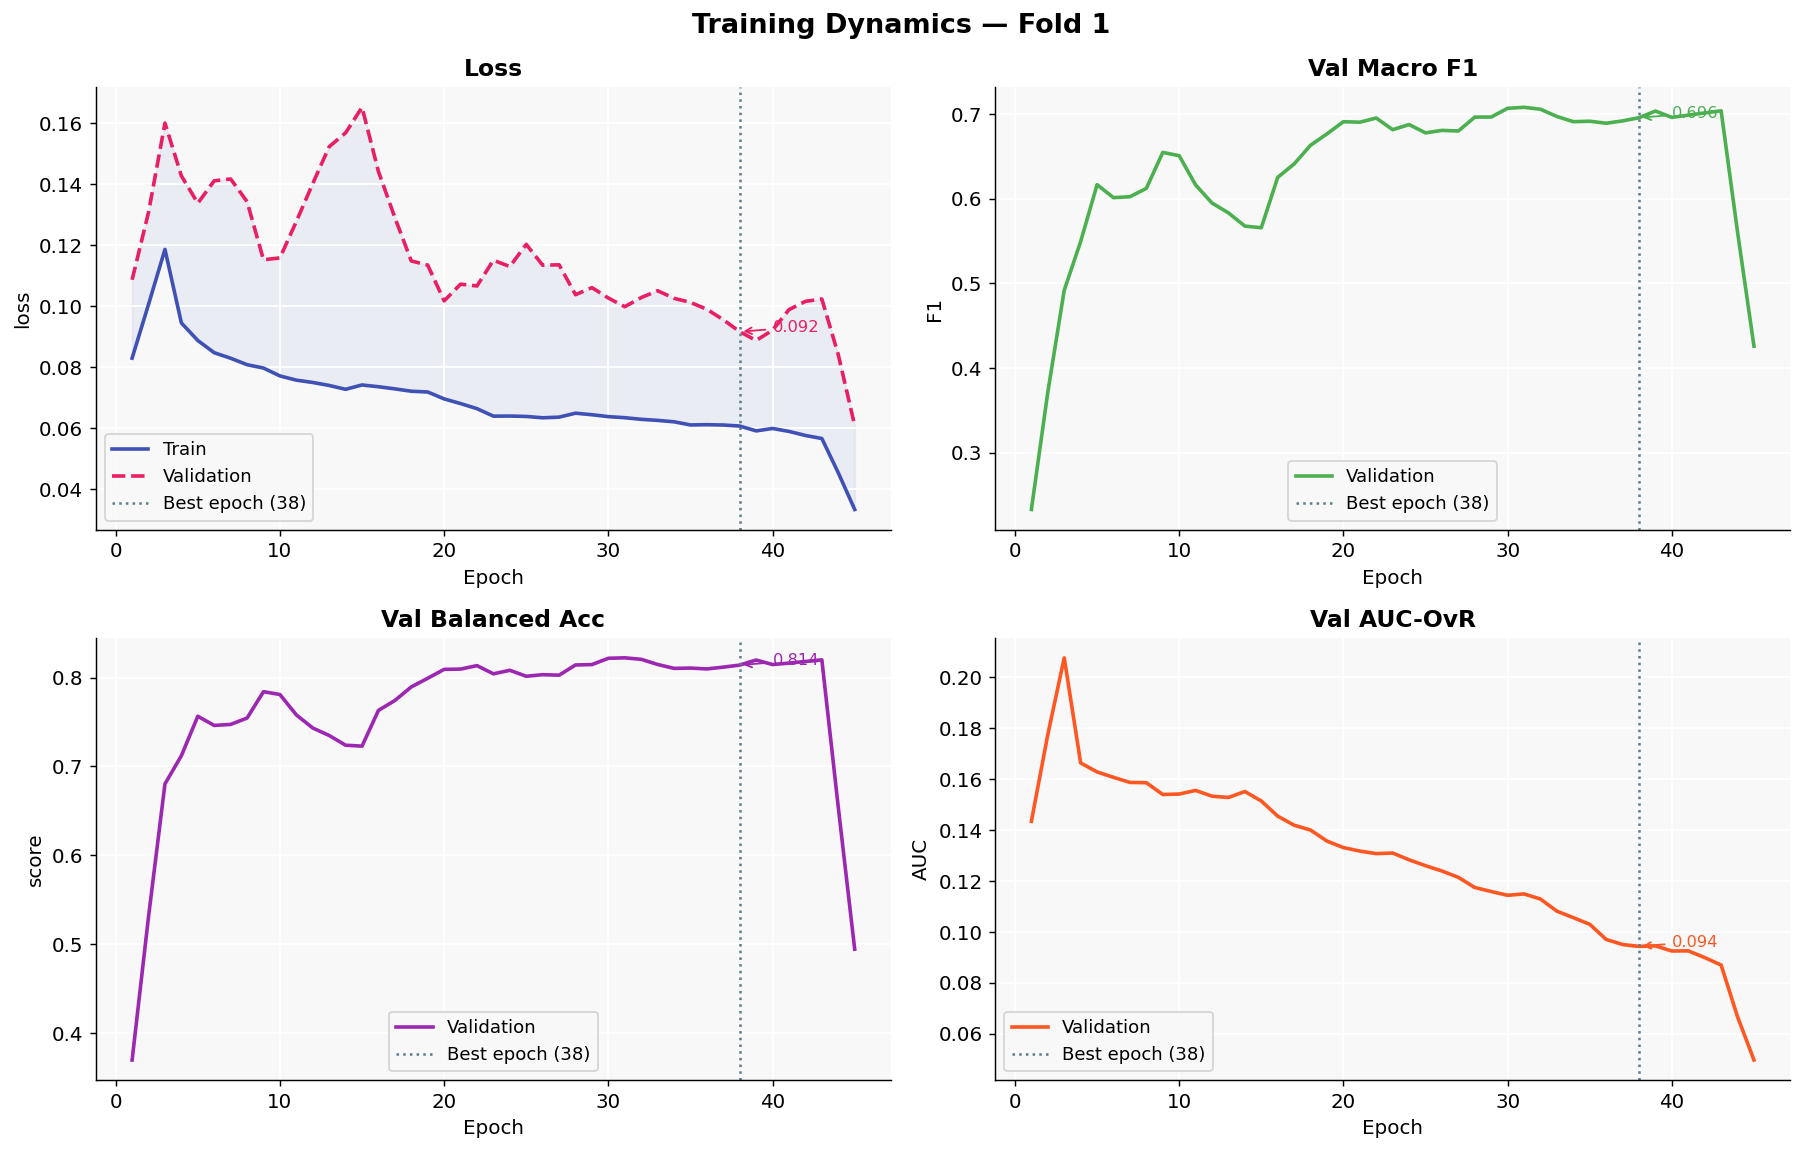

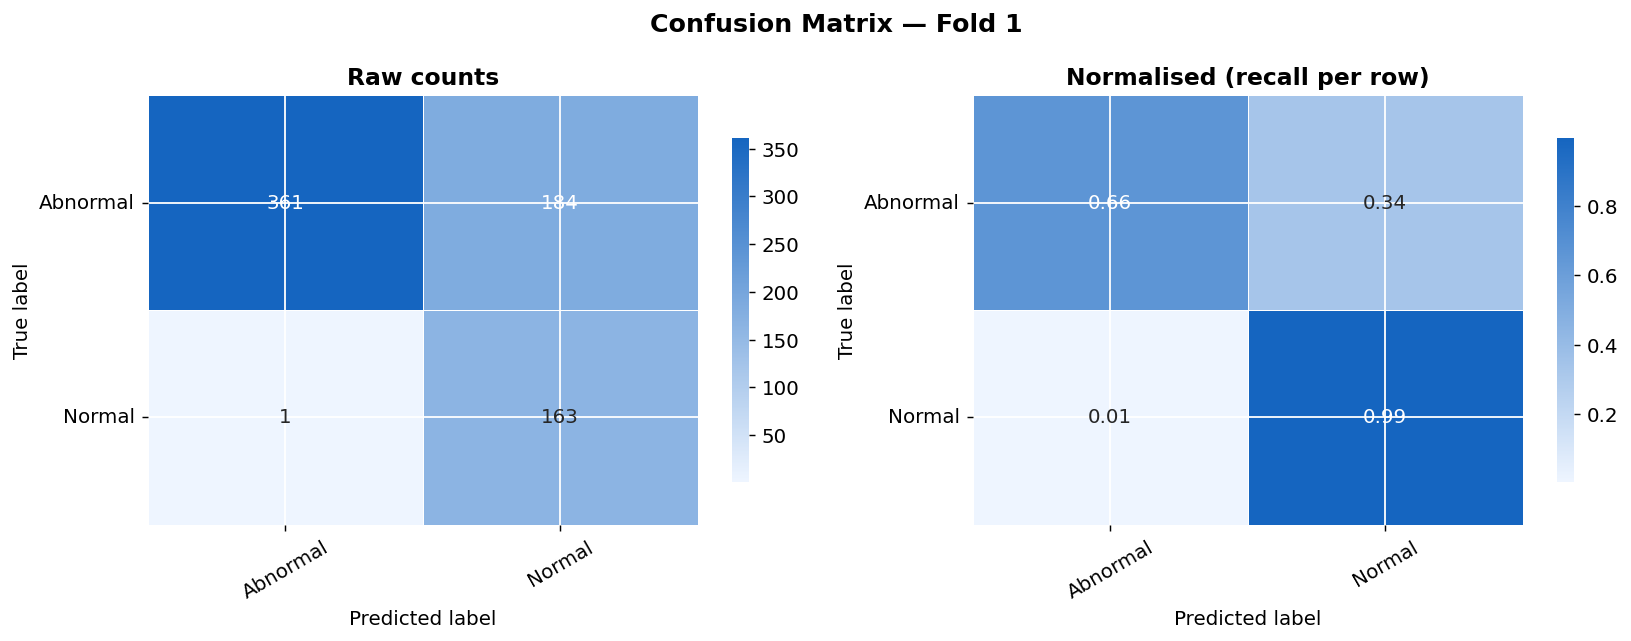

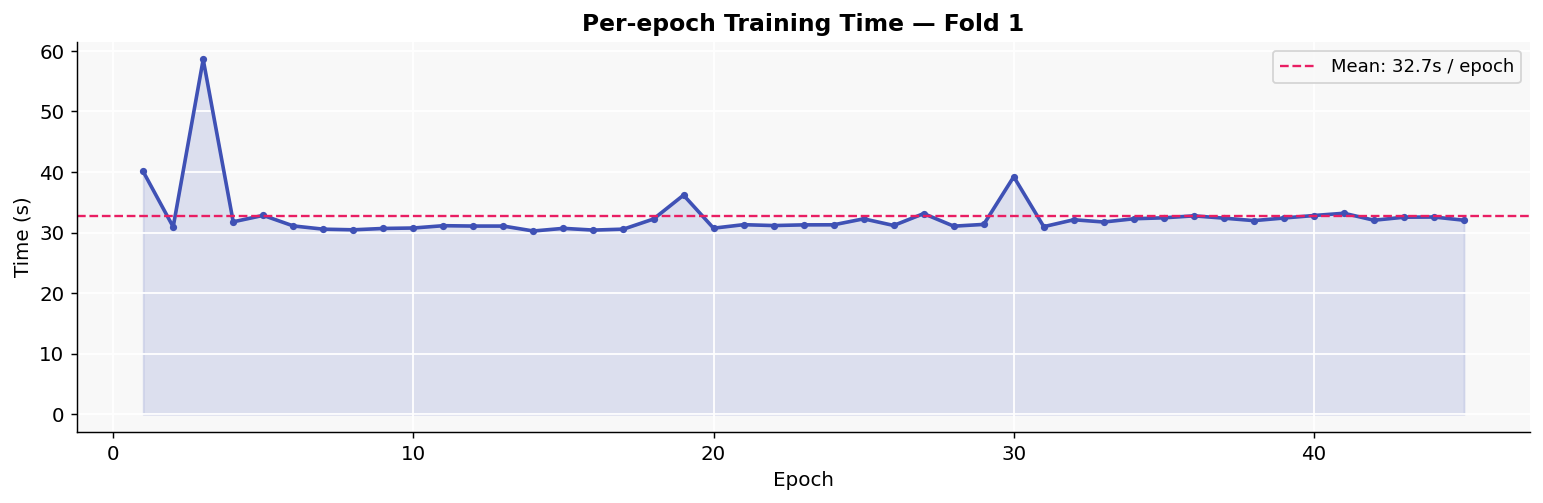


  FOLD 2/5  |  model: cnn_lstm  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [33.9s  MPS mem 0.15GB] | TrLoss 0.1749 TrAcc 0.523 | VlLoss 0.1858 VlAcc 0.230 F1 0.187 AUC 0.255 BalAcc 0.500


  Ep 002 [34.5s  MPS mem 0.15GB] | TrLoss 0.1144 TrAcc 0.542 | VlLoss 0.1669 VlAcc 0.322 F1 0.309 AUC 0.158 BalAcc 0.560


  Ep 003 [34.1s  MPS mem 0.15GB] | TrLoss 0.1015 TrAcc 0.623 | VlLoss 0.1050 VlAcc 0.750 F1 0.720 AUC 0.172 BalAcc 0.810


  Ep 004 [32.5s  MPS mem 0.15GB] | TrLoss 0.0956 TrAcc 0.634 | VlLoss 0.0883 VlAcc 0.679 F1 0.662 AUC 0.166 BalAcc 0.787


  Ep 005 [32.1s  MPS mem 0.15GB] | TrLoss 0.0929 TrAcc 0.648 | VlLoss 0.0974 VlAcc 0.612 F1 0.603 AUC 0.147 BalAcc 0.748


... (18 outputs left out)

  Ep 024 [31.7s  MPS mem 0.15GB] | TrLoss 0.0683 TrAcc 0.770 | VlLoss 0.1079 VlAcc 0.736 F1 0.714 AUC 0.101 BalAcc 0.826


  Ep 025 [32.4s  MPS mem 0.15GB] | TrLoss 0.0722 TrAcc 0.759 | VlLoss 0.0880 VlAcc 0.739 F1 0.717 AUC 0.103 BalAcc 0.830


  Ep 026 [32.2s  MPS mem 0.15GB] | TrLoss 0.0691 TrAcc 0.767 | VlLoss 0.0999 VlAcc 0.701 F1 0.682 AUC 0.105 BalAcc 0.806
  ⏹ Early stopping at epoch 26



  ✅ Fold 2 Best → F1: 0.7300  BalAcc: 0.8361  AUC: 0.1202
              precision    recall  f1-score   support

    Abnormal       0.99      0.68      0.81       545
      Normal       0.48      0.99      0.65       163

    accuracy                           0.75       708
   macro avg       0.74      0.84      0.73       708
weighted avg       0.88      0.75      0.77       708



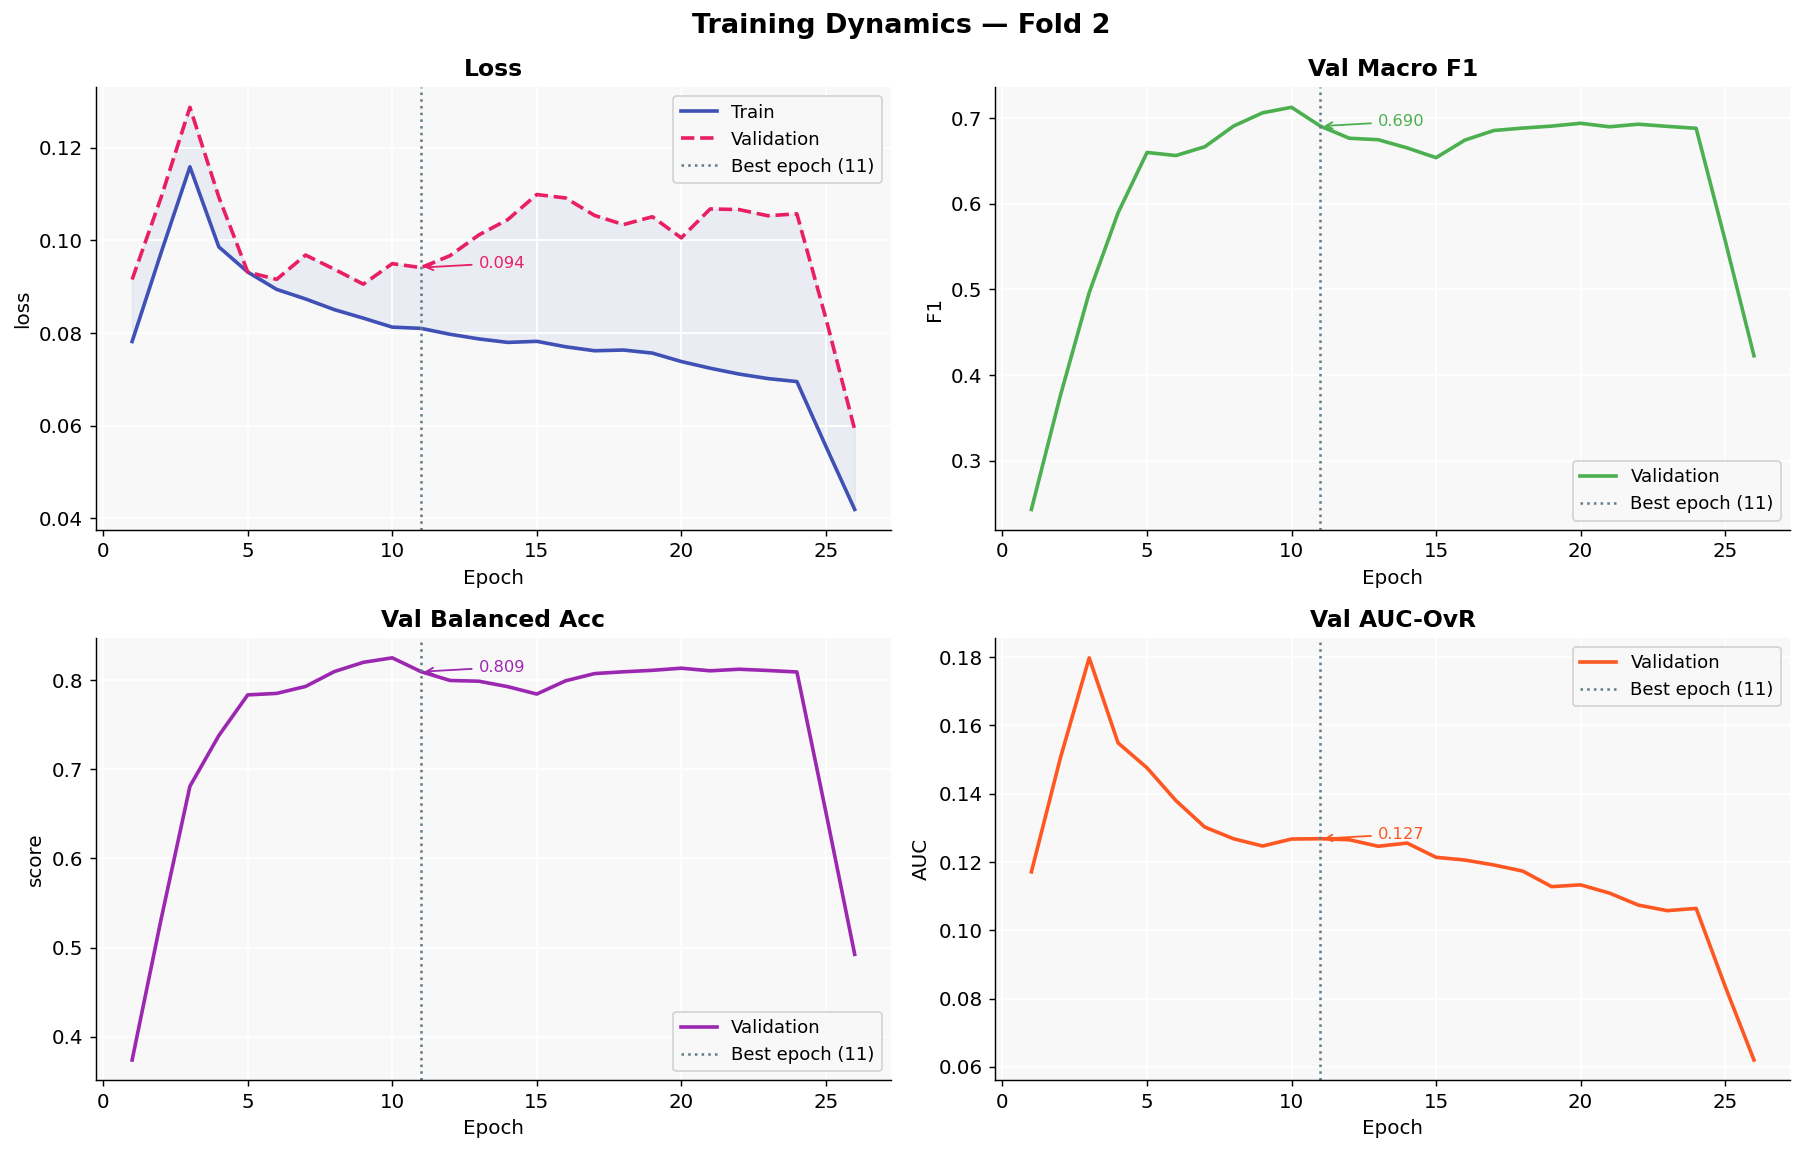

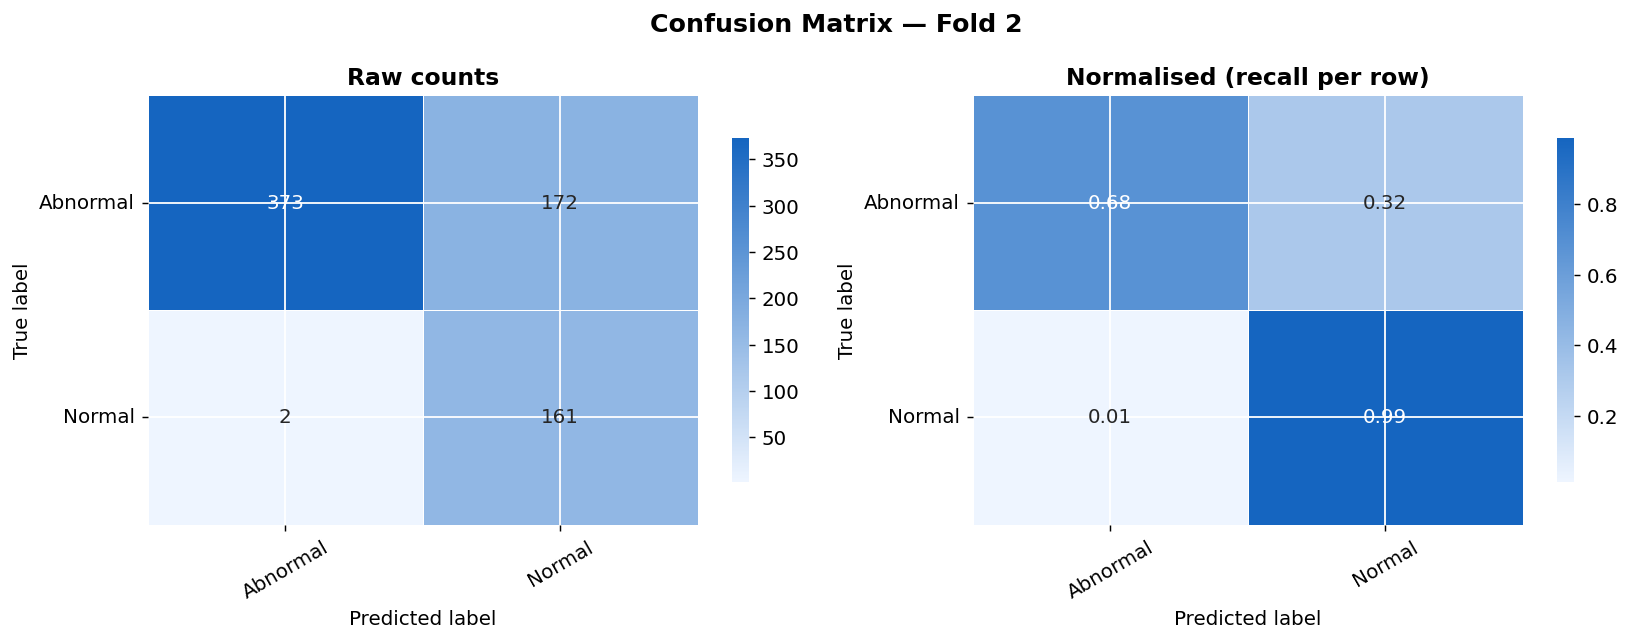

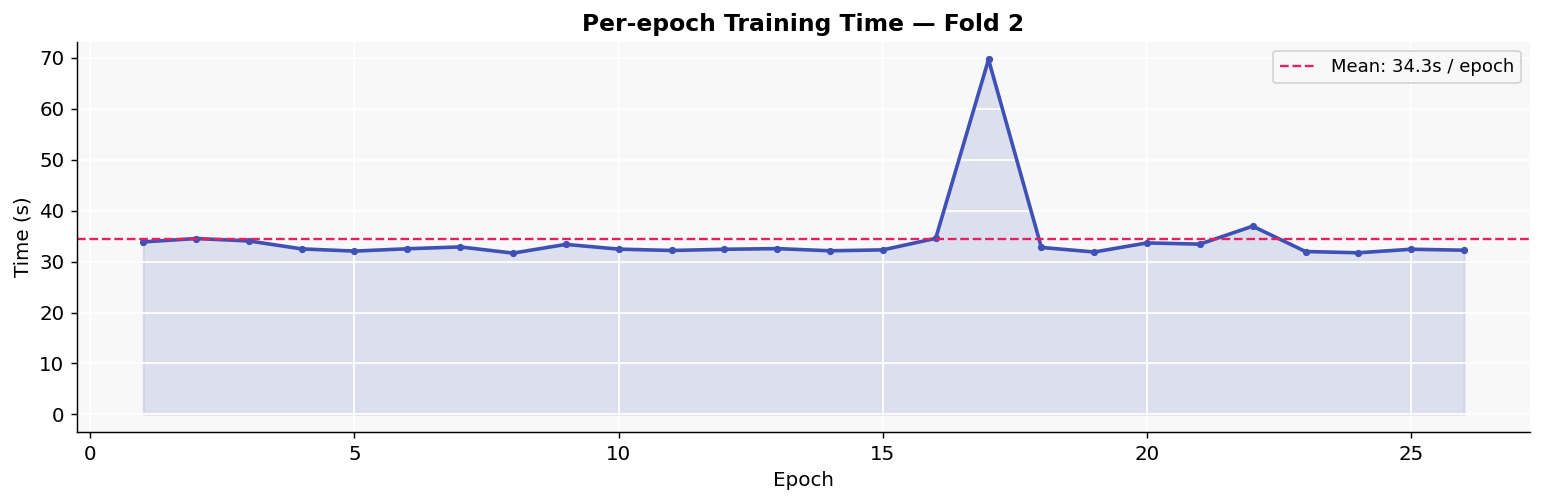


  FOLD 3/5  |  model: cnn_lstm  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [32.7s  MPS mem 0.15GB] | TrLoss 0.2163 TrAcc 0.503 | VlLoss 0.1022 VlAcc 0.230 F1 0.187 AUC 0.262 BalAcc 0.500


  Ep 002 [31.6s  MPS mem 0.15GB] | TrLoss 0.1143 TrAcc 0.510 | VlLoss 0.1377 VlAcc 0.446 F1 0.446 AUC 0.164 BalAcc 0.640


  Ep 003 [31.4s  MPS mem 0.15GB] | TrLoss 0.0999 TrAcc 0.607 | VlLoss 0.1027 VlAcc 0.682 F1 0.665 AUC 0.130 BalAcc 0.789


  Ep 004 [33.0s  MPS mem 0.15GB] | TrLoss 0.0925 TrAcc 0.669 | VlLoss 0.0915 VlAcc 0.630 F1 0.619 AUC 0.153 BalAcc 0.757


  Ep 005 [31.5s  MPS mem 0.15GB] | TrLoss 0.0851 TrAcc 0.697 | VlLoss 0.1408 VlAcc 0.701 F1 0.673 AUC 0.198 BalAcc 0.767


... (15 outputs left out)

  Ep 021 [36.5s  MPS mem 0.15GB] | TrLoss 0.0685 TrAcc 0.768 | VlLoss 0.1235 VlAcc 0.720 F1 0.700 AUC 0.100 BalAcc 0.818


  Ep 022 [37.5s  MPS mem 0.15GB] | TrLoss 0.0658 TrAcc 0.786 | VlLoss 0.1094 VlAcc 0.672 F1 0.657 AUC 0.103 BalAcc 0.787


  Ep 023 [37.4s  MPS mem 0.15GB] | TrLoss 0.0681 TrAcc 0.771 | VlLoss 0.1059 VlAcc 0.698 F1 0.680 AUC 0.104 BalAcc 0.804
  ⏹ Early stopping at epoch 23



  ✅ Fold 3 Best → F1: 0.7261  BalAcc: 0.8333  AUC: 0.1218
              precision    recall  f1-score   support

    Abnormal       0.99      0.68      0.81       545
      Normal       0.48      0.99      0.65       163

    accuracy                           0.75       708
   macro avg       0.74      0.83      0.73       708
weighted avg       0.88      0.75      0.77       708



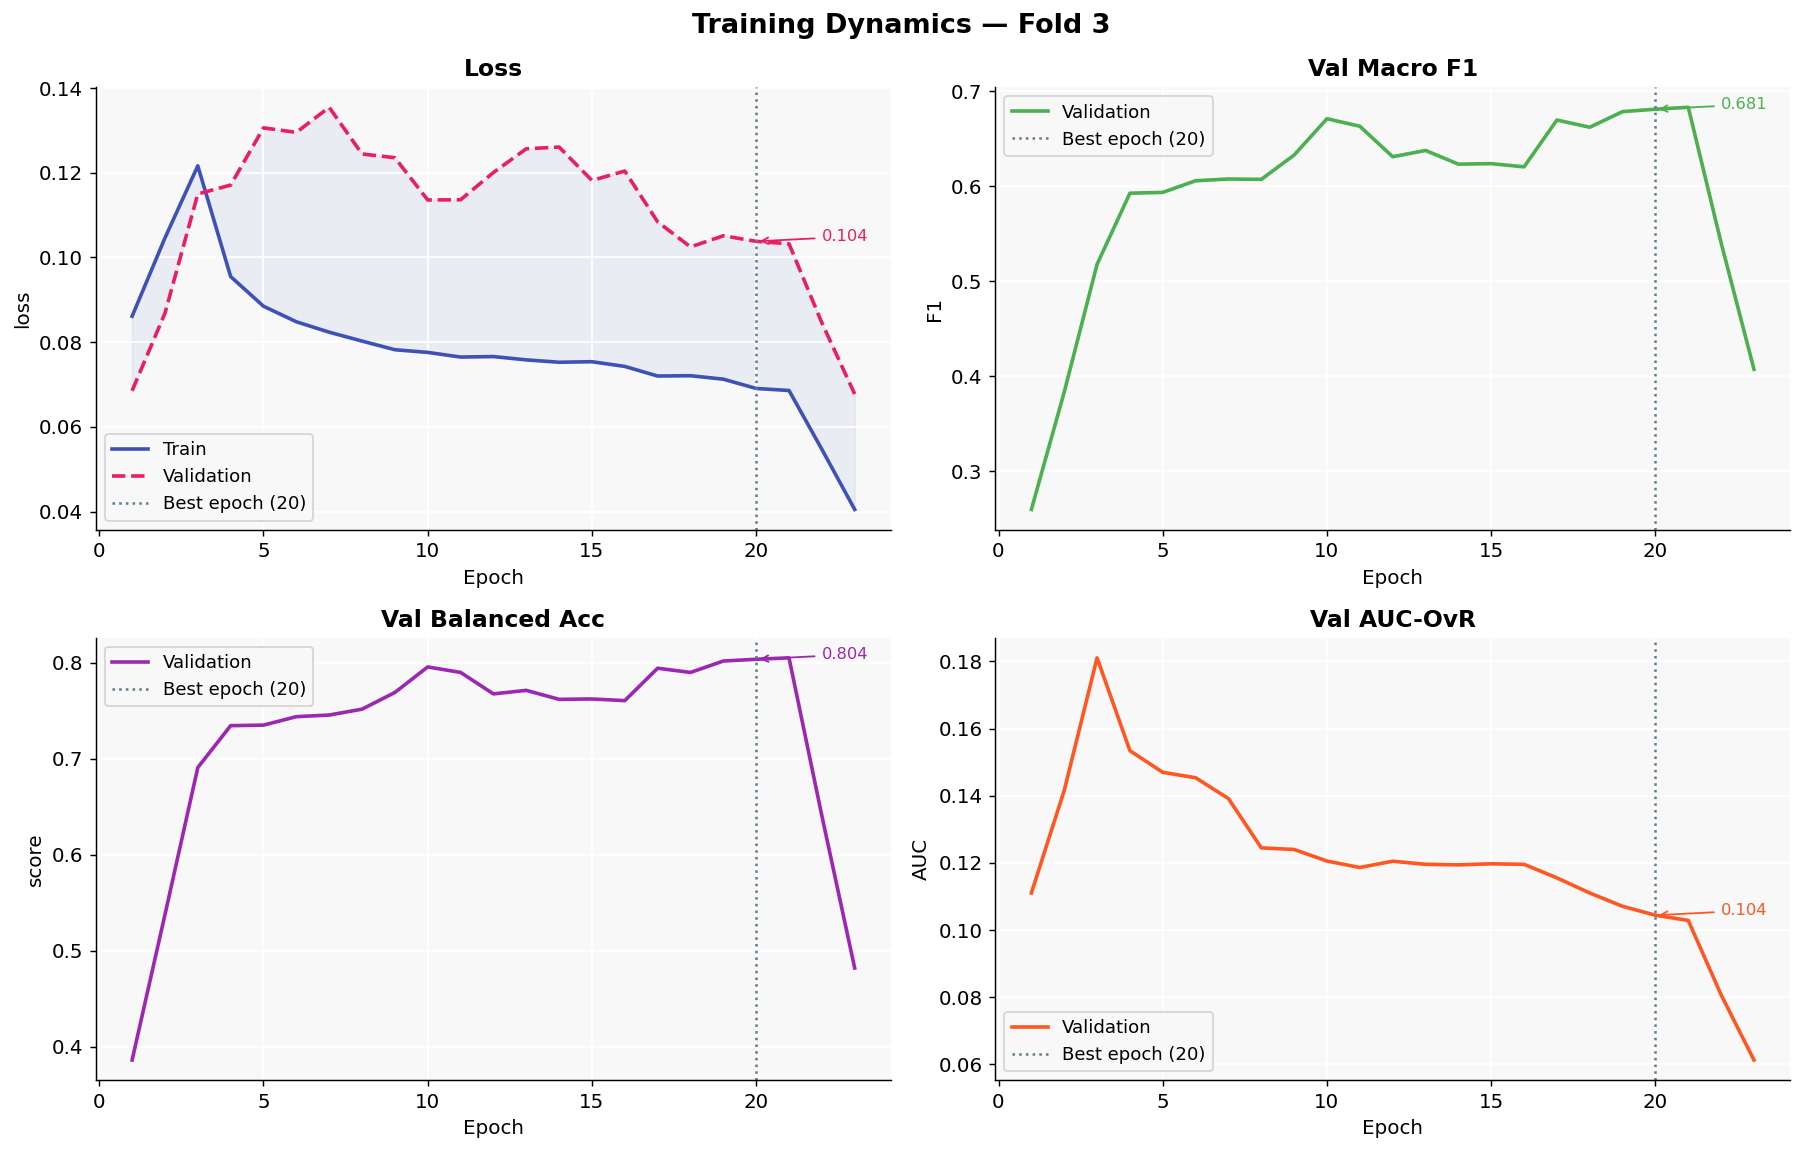

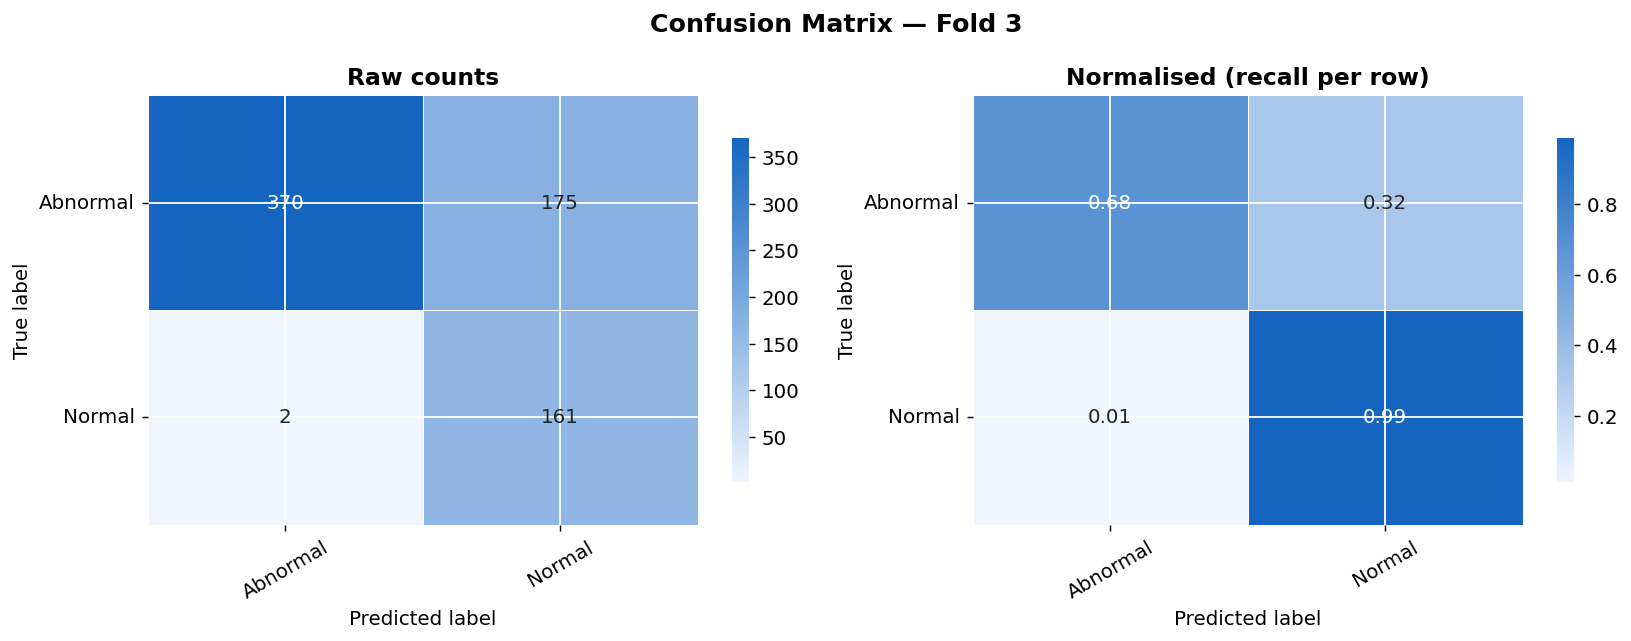

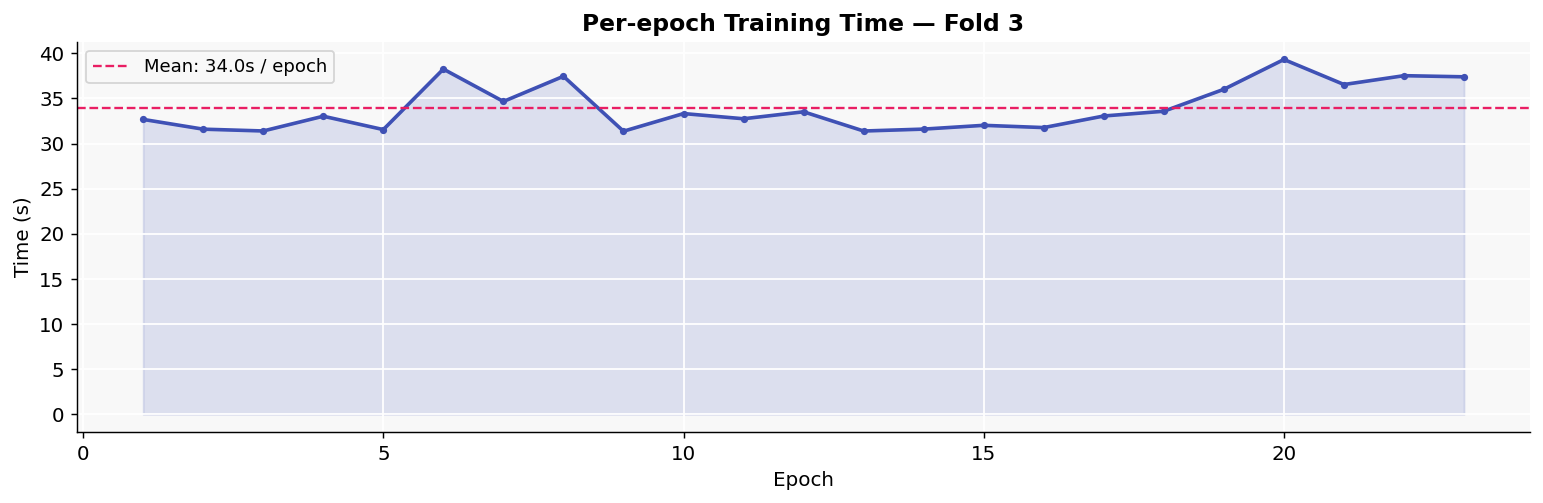


  FOLD 4/5  |  model: cnn_lstm  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [31.5s  MPS mem 0.14GB] | TrLoss 0.2080 TrAcc 0.519 | VlLoss 0.2718 VlAcc 0.230 F1 0.187 AUC 0.257 BalAcc 0.500


  Ep 002 [35.8s  MPS mem 0.14GB] | TrLoss 0.1104 TrAcc 0.538 | VlLoss 0.1946 VlAcc 0.254 F1 0.221 AUC 0.151 BalAcc 0.516


  Ep 003 [42.6s  MPS mem 0.14GB] | TrLoss 0.1027 TrAcc 0.609 | VlLoss 0.1522 VlAcc 0.493 F1 0.492 AUC 0.139 BalAcc 0.671


  Ep 004 [35.8s  MPS mem 0.14GB] | TrLoss 0.0996 TrAcc 0.655 | VlLoss 0.1215 VlAcc 0.668 F1 0.651 AUC 0.130 BalAcc 0.776


  Ep 005 [38.6s  MPS mem 0.14GB] | TrLoss 0.0900 TrAcc 0.677 | VlLoss 0.1484 VlAcc 0.588 F1 0.580 AUC 0.140 BalAcc 0.730


... (21 outputs left out)

  Ep 027 [34.1s  MPS mem 0.14GB] | TrLoss 0.0718 TrAcc 0.758 | VlLoss 0.0937 VlAcc 0.719 F1 0.699 AUC 0.094 BalAcc 0.817


  Ep 028 [34.5s  MPS mem 0.14GB] | TrLoss 0.0676 TrAcc 0.771 | VlLoss 0.1278 VlAcc 0.736 F1 0.714 AUC 0.087 BalAcc 0.828


  Ep 029 [36.1s  MPS mem 0.14GB] | TrLoss 0.0695 TrAcc 0.775 | VlLoss 0.0976 VlAcc 0.678 F1 0.662 AUC 0.102 BalAcc 0.791
  ⏹ Early stopping at epoch 29



  ✅ Fold 4 Best → F1: 0.7400  BalAcc: 0.8413  AUC: 0.1021
              precision    recall  f1-score   support

    Abnormal       0.99      0.70      0.82       545
      Normal       0.50      0.98      0.66       163

    accuracy                           0.77       708
   macro avg       0.74      0.84      0.74       708
weighted avg       0.88      0.77      0.78       708



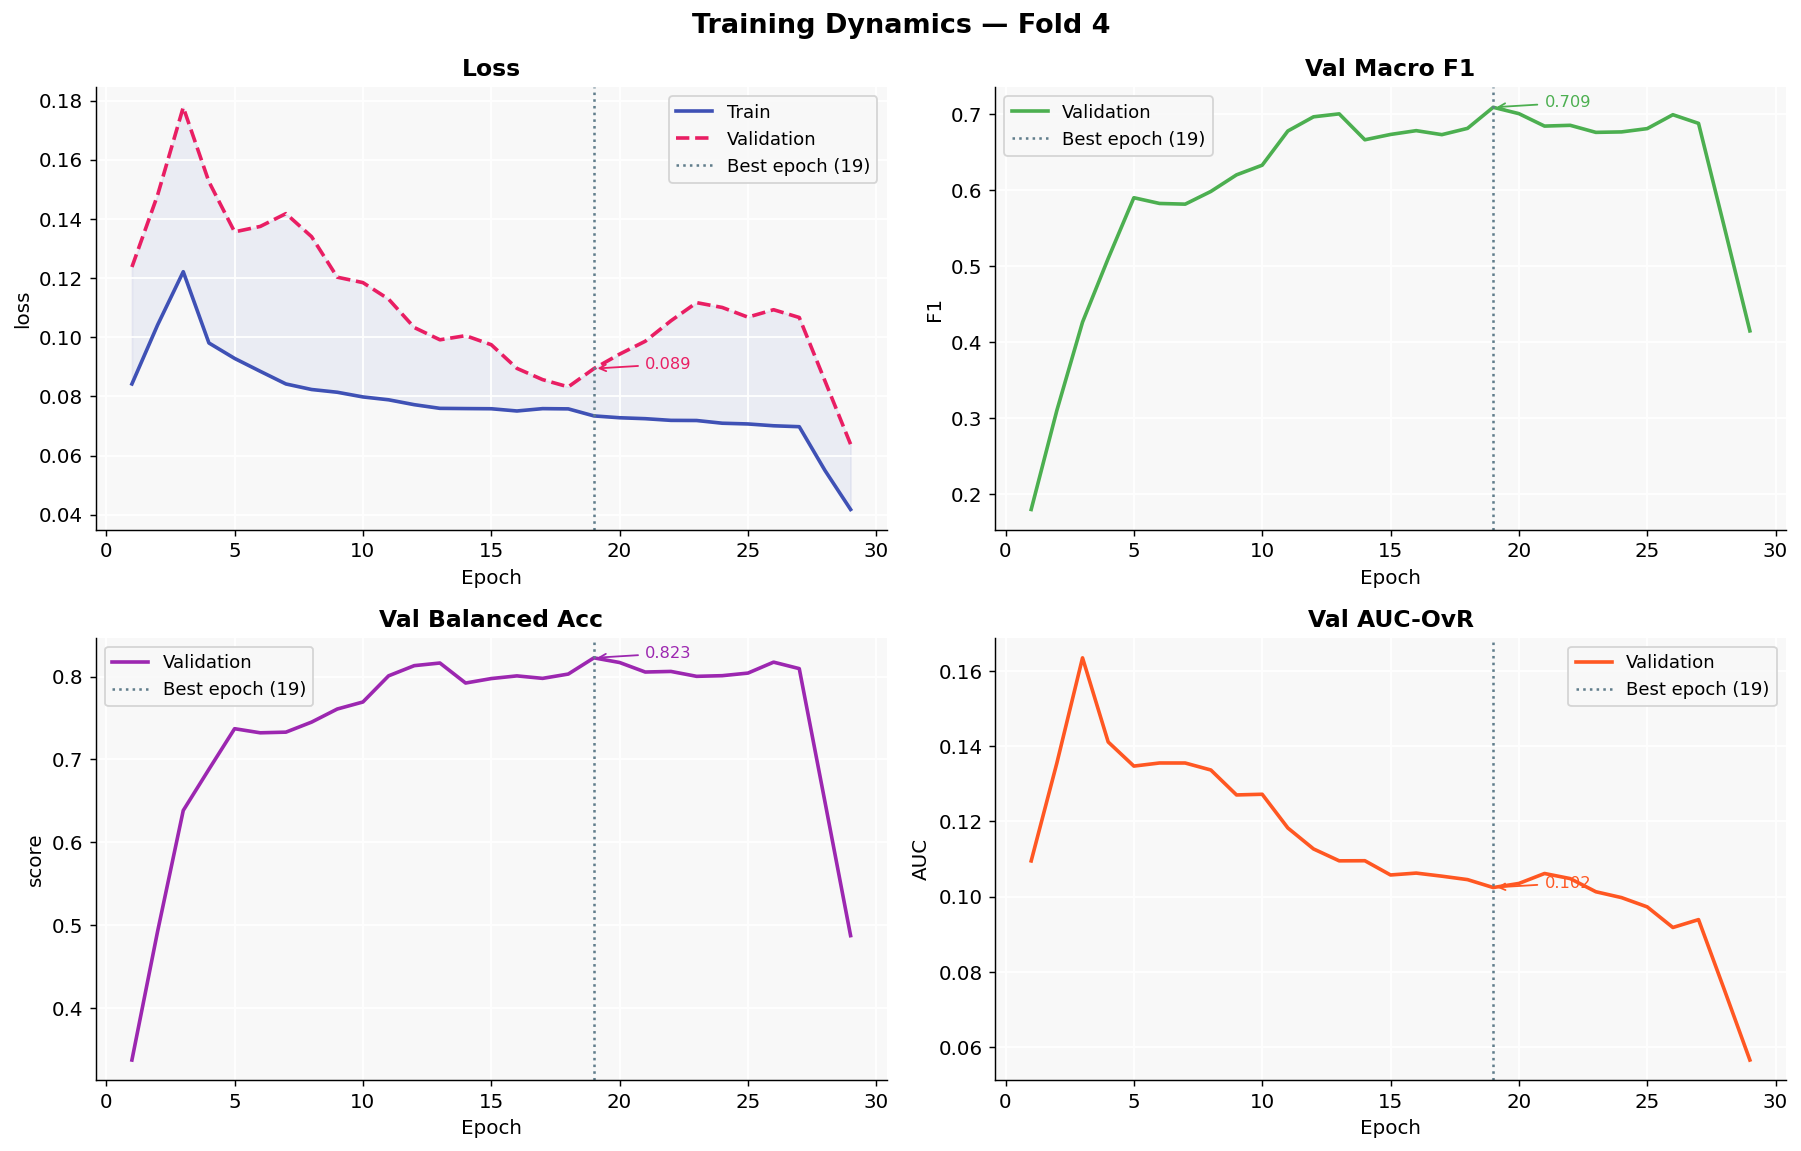

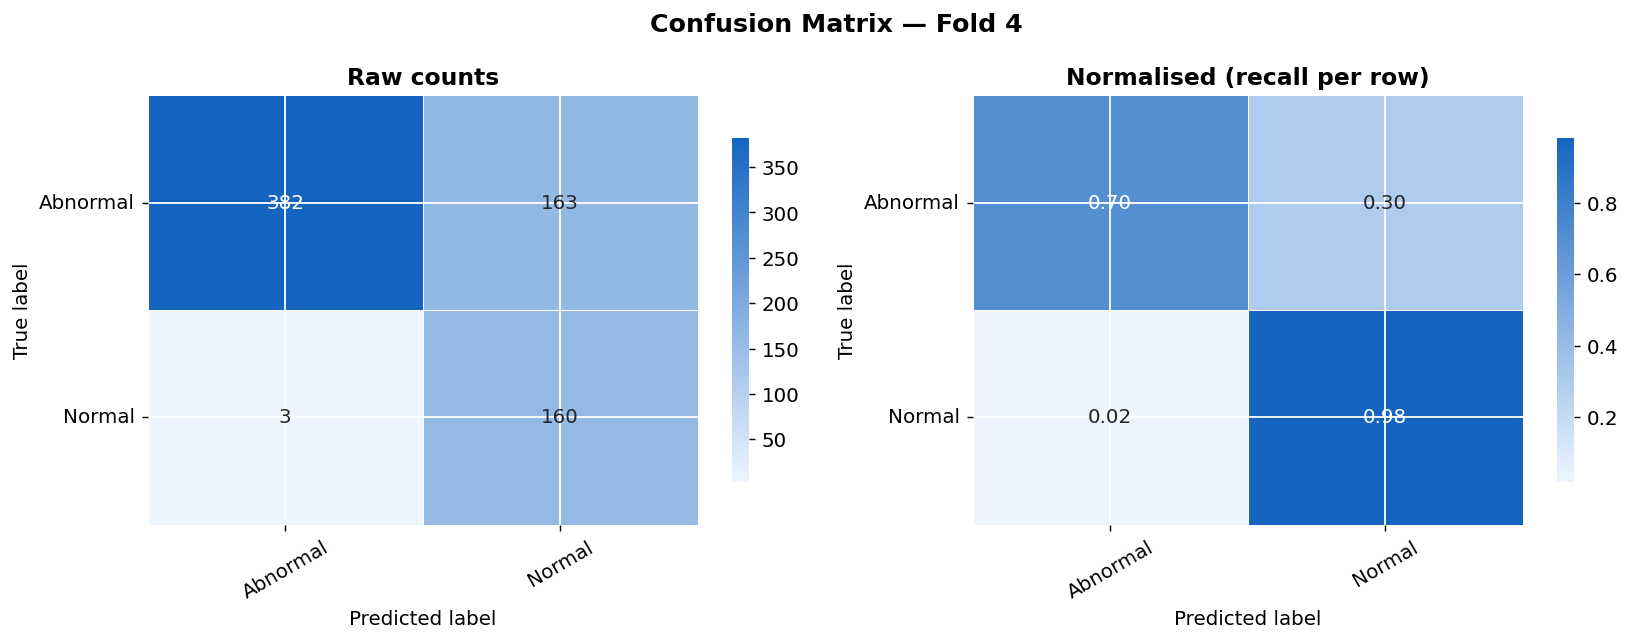

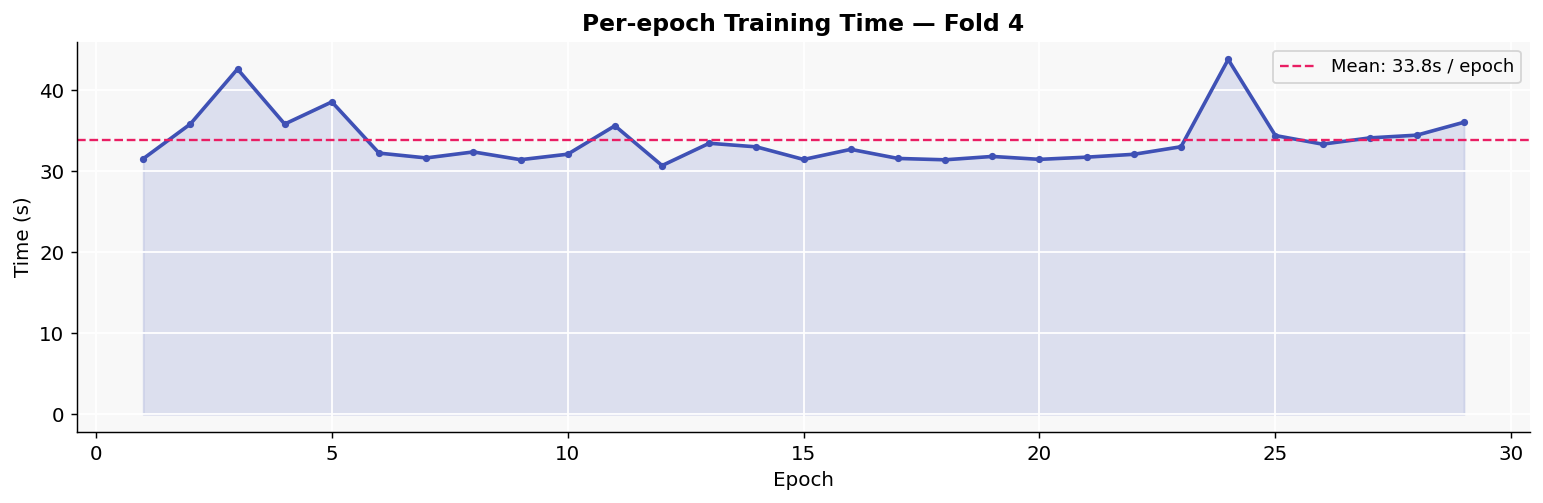


  FOLD 5/5  |  model: cnn_lstm  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [32.6s  MPS mem 0.14GB] | TrLoss 0.1940 TrAcc 0.503 | VlLoss 0.1688 VlAcc 0.230 F1 0.187 AUC 0.272 BalAcc 0.500


  Ep 002 [33.3s  MPS mem 0.14GB] | TrLoss 0.1233 TrAcc 0.498 | VlLoss 0.1059 VlAcc 0.517 F1 0.515 AUC 0.204 BalAcc 0.686


  Ep 003 [32.8s  MPS mem 0.14GB] | TrLoss 0.1027 TrAcc 0.592 | VlLoss 0.1347 VlAcc 0.582 F1 0.576 AUC 0.155 BalAcc 0.728


  Ep 004 [32.6s  MPS mem 0.14GB] | TrLoss 0.0964 TrAcc 0.648 | VlLoss 0.1974 VlAcc 0.359 F1 0.352 AUC 0.158 BalAcc 0.583


  Ep 005 [33.5s  MPS mem 0.14GB] | TrLoss 0.0900 TrAcc 0.667 | VlLoss 0.1673 VlAcc 0.442 F1 0.442 AUC 0.152 BalAcc 0.638


... (66 outputs left out)

  Ep 072 [33.6s  MPS mem 0.14GB] | TrLoss 0.0503 TrAcc 0.834 | VlLoss 0.0742 VlAcc 0.766 F1 0.741 AUC 0.056 BalAcc 0.848


  Ep 073 [34.3s  MPS mem 0.14GB] | TrLoss 0.0491 TrAcc 0.838 | VlLoss 0.0741 VlAcc 0.763 F1 0.739 AUC 0.056 BalAcc 0.846


  Ep 074 [34.1s  MPS mem 0.14GB] | TrLoss 0.0511 TrAcc 0.828 | VlLoss 0.0728 VlAcc 0.764 F1 0.740 AUC 0.057 BalAcc 0.847
  ⏹ Early stopping at epoch 74



  ✅ Fold 5 Best → F1: 0.7454  BalAcc: 0.8505  AUC: 0.0569
              precision    recall  f1-score   support

    Abnormal       1.00      0.70      0.82       545
      Normal       0.50      1.00      0.67       163

    accuracy                           0.77       708
   macro avg       0.75      0.85      0.75       708
weighted avg       0.88      0.77      0.79       708



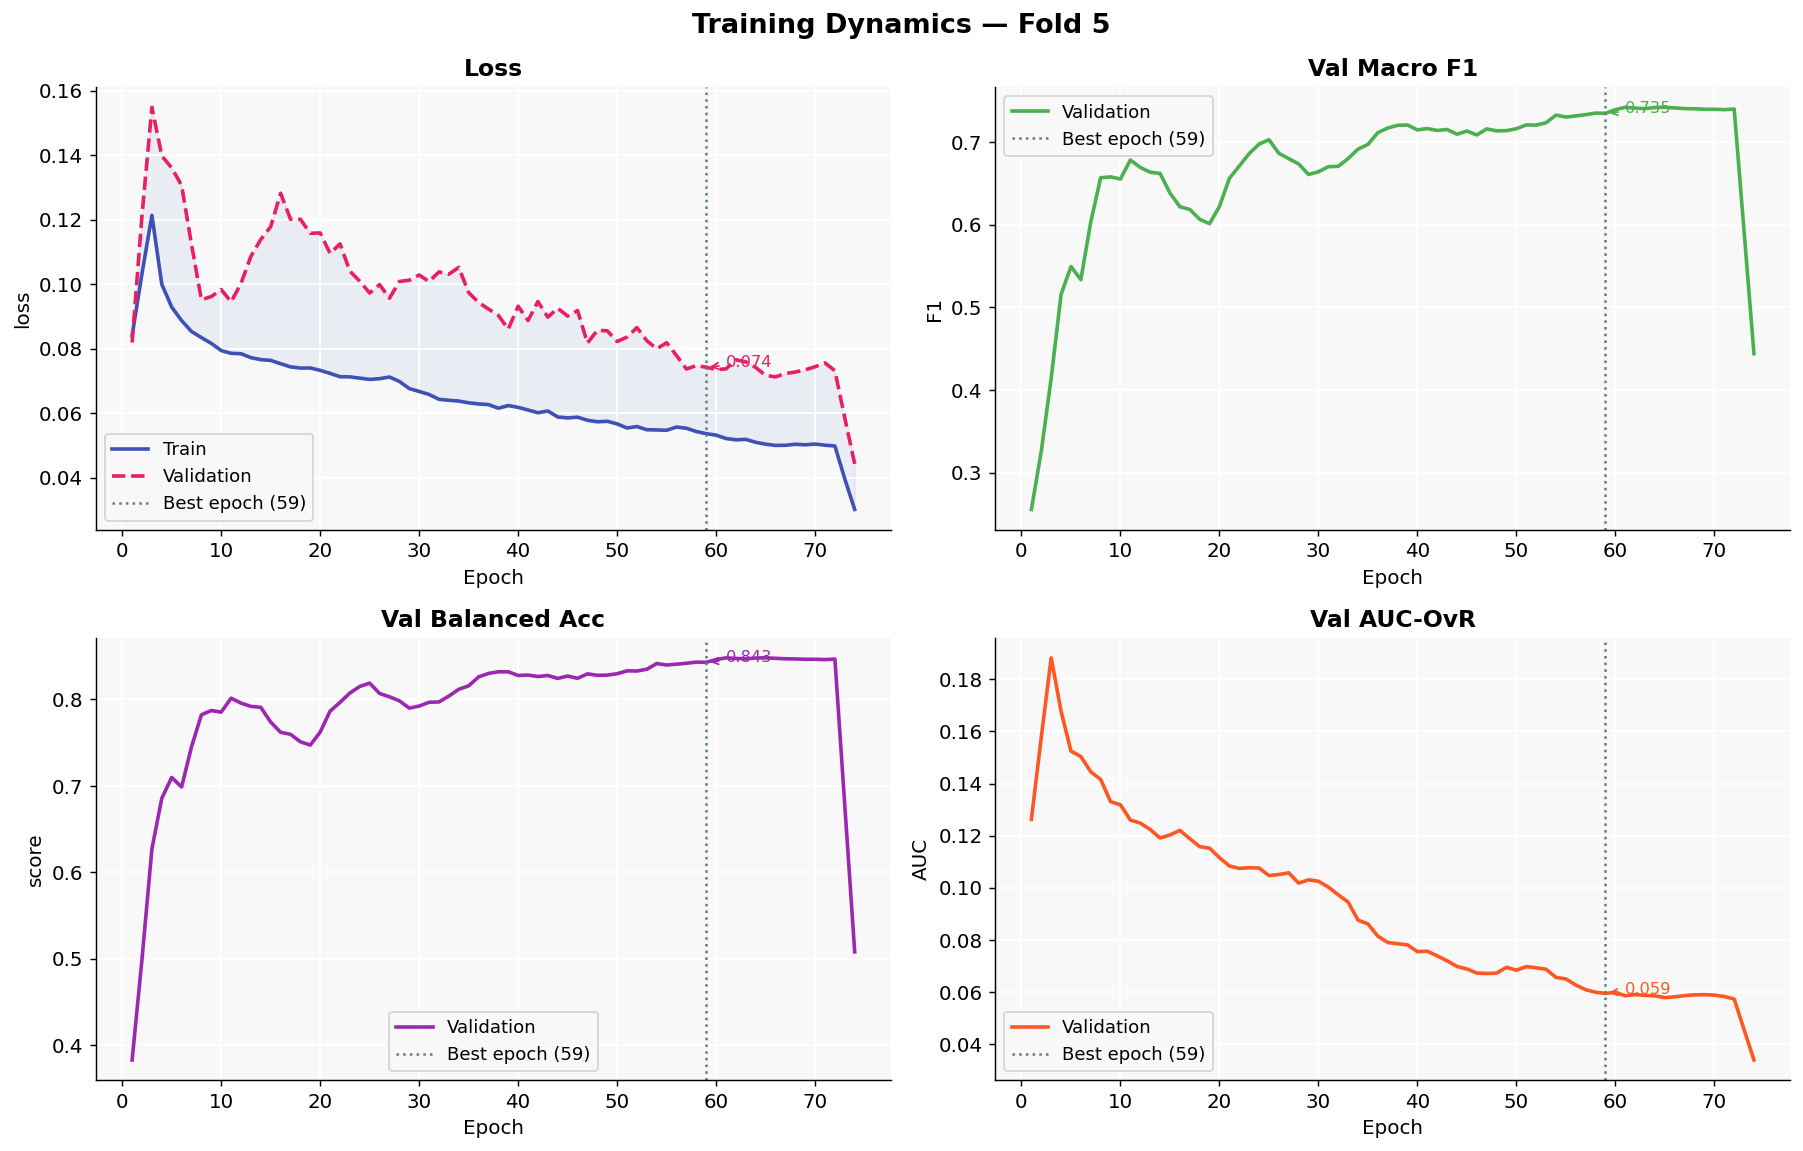

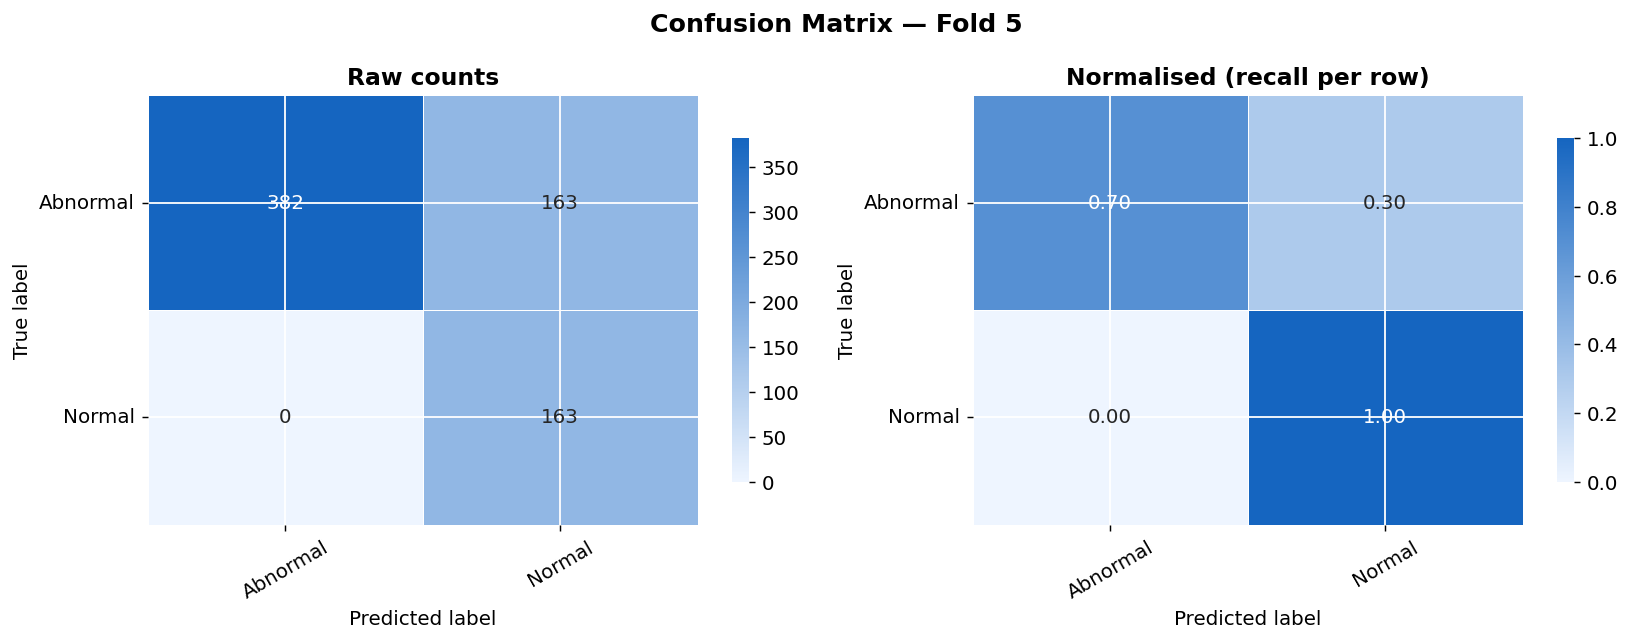

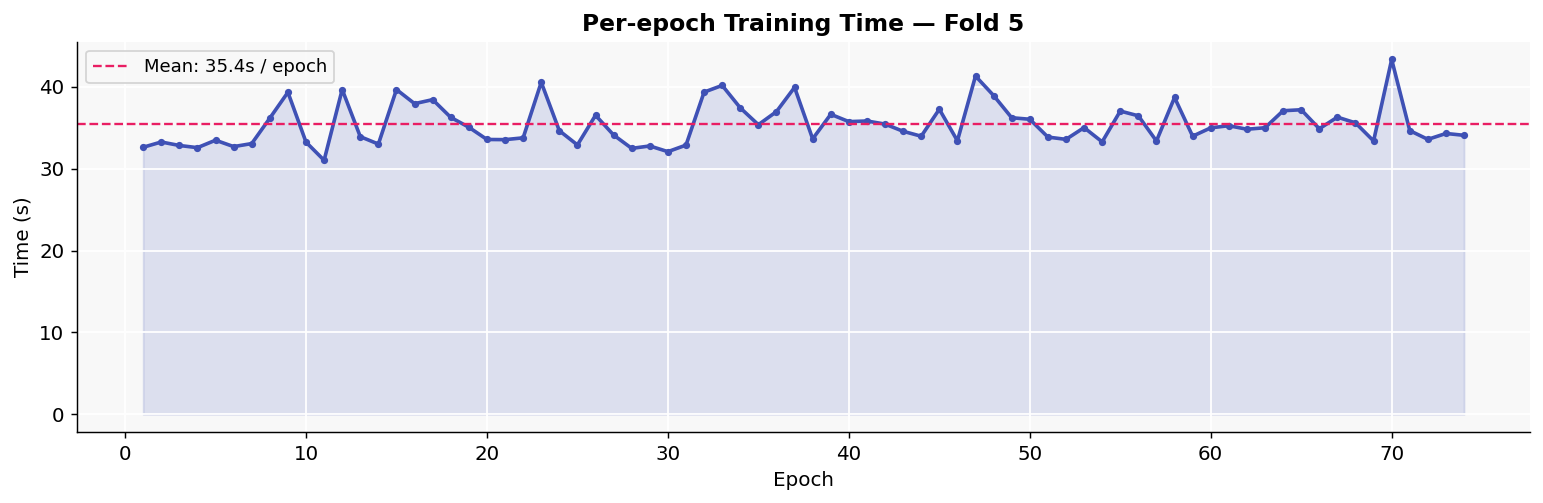


  [CNN_LSTM] CROSS-VALIDATION SUMMARY
 fold       f1  bal_acc      auc
    1 0.716998 0.828144 0.119188
    2 0.730032 0.836067 0.120212
    3 0.726135 0.833315 0.121765
    4 0.739971 0.841256 0.102099
    5 0.745415 0.850459 0.056948

  Mean F1     : 0.7317 ± 0.0113
  Mean BalAcc : 0.8378 ± 0.0085
  Mean AUC    : 0.1040 ± 0.0275
  Saved → ./outputs_new/cv_results_cnn_lstm.csv


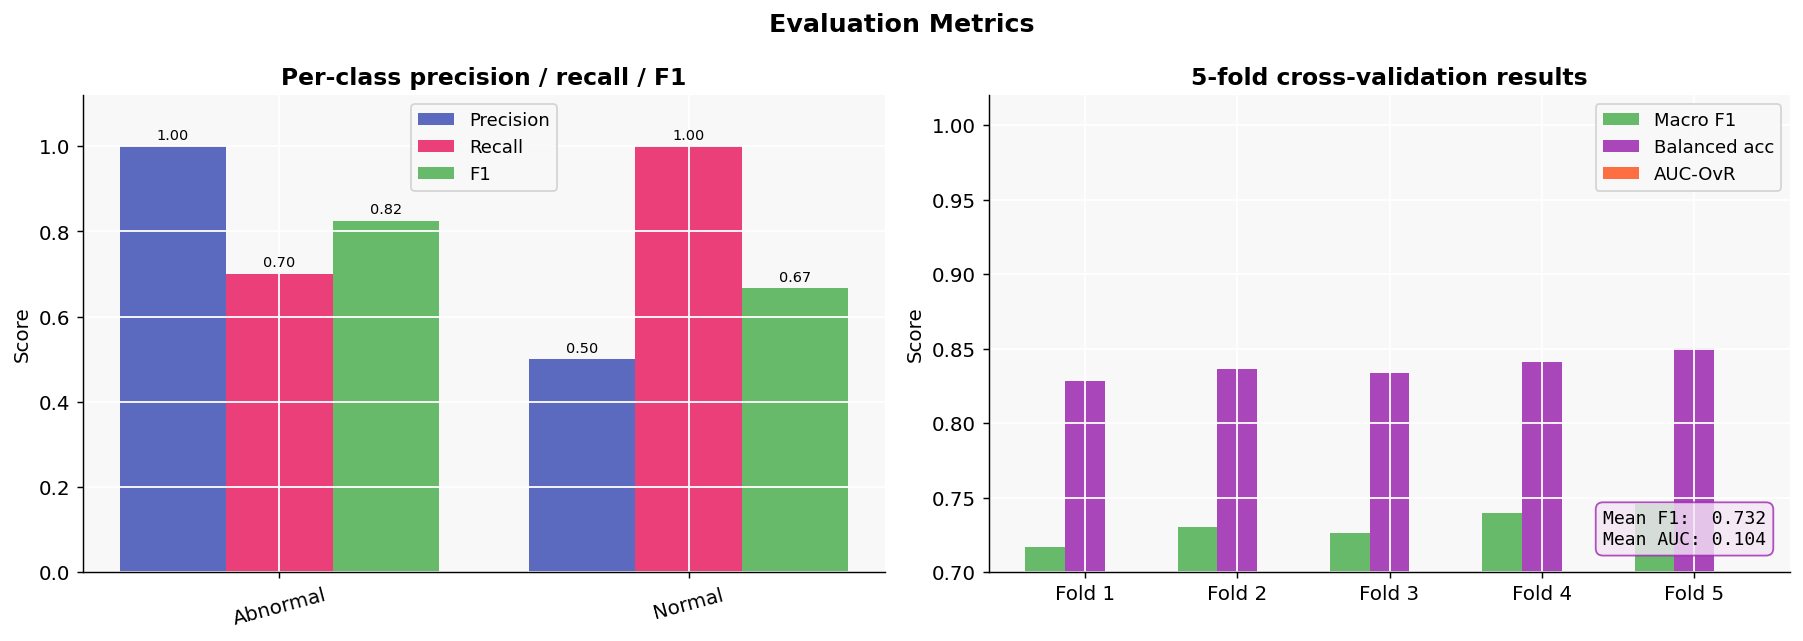

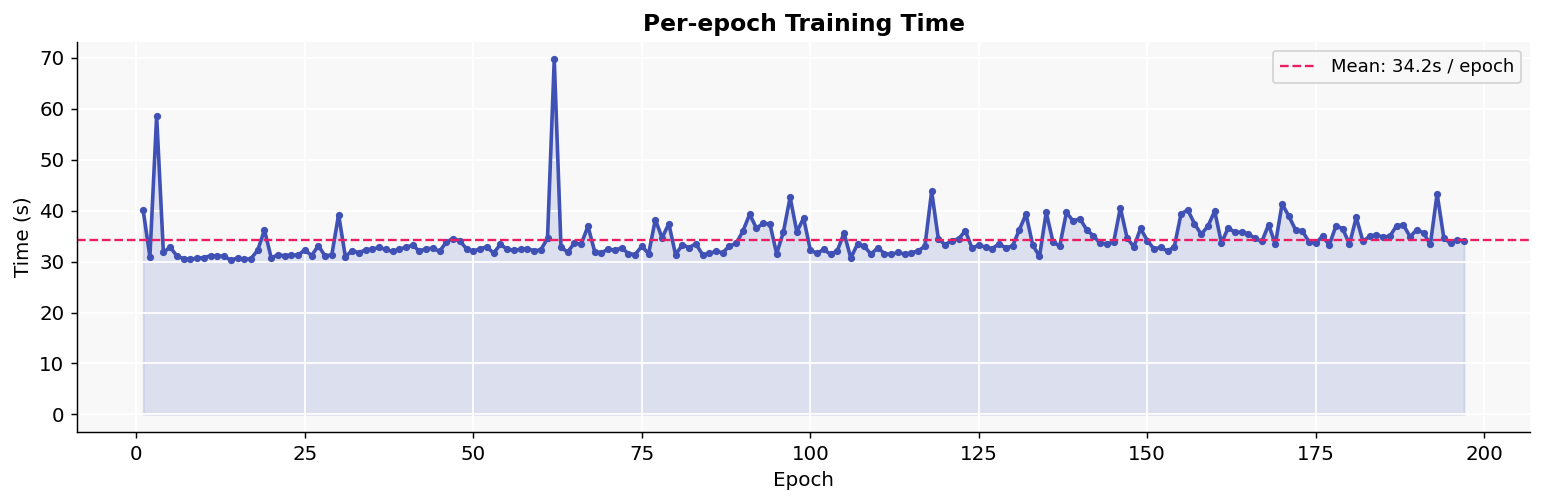

In [31]:
results_df, best_preds, best_targets, best_fold = run_training(
    filepaths, labels_enc, n_classes, label_names)

#### Post-Training Visualization

 fold       f1  bal_acc      auc
    1 0.716998 0.828144 0.119188
    2 0.730032 0.836067 0.120212
    3 0.726135 0.833315 0.121765
    4 0.739971 0.841256 0.102099
    5 0.745415 0.850459 0.056948


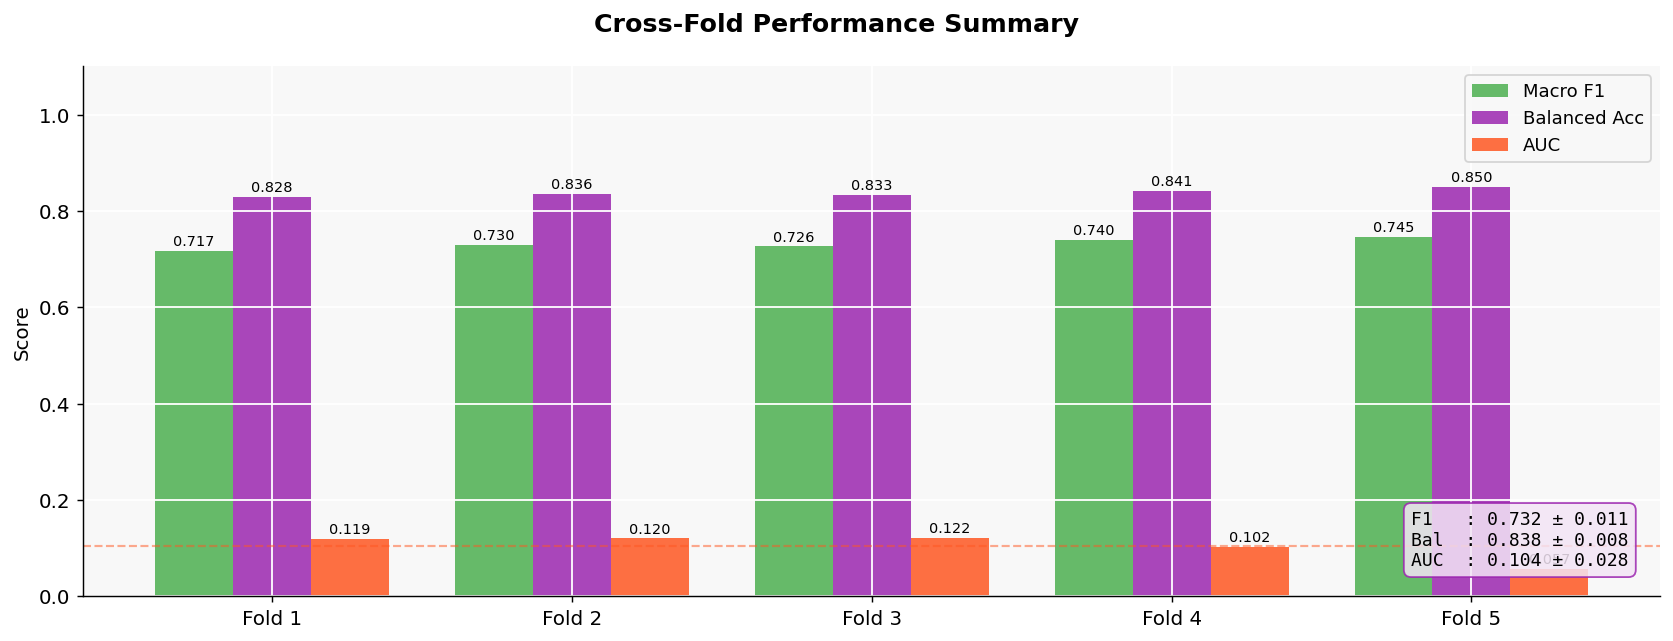

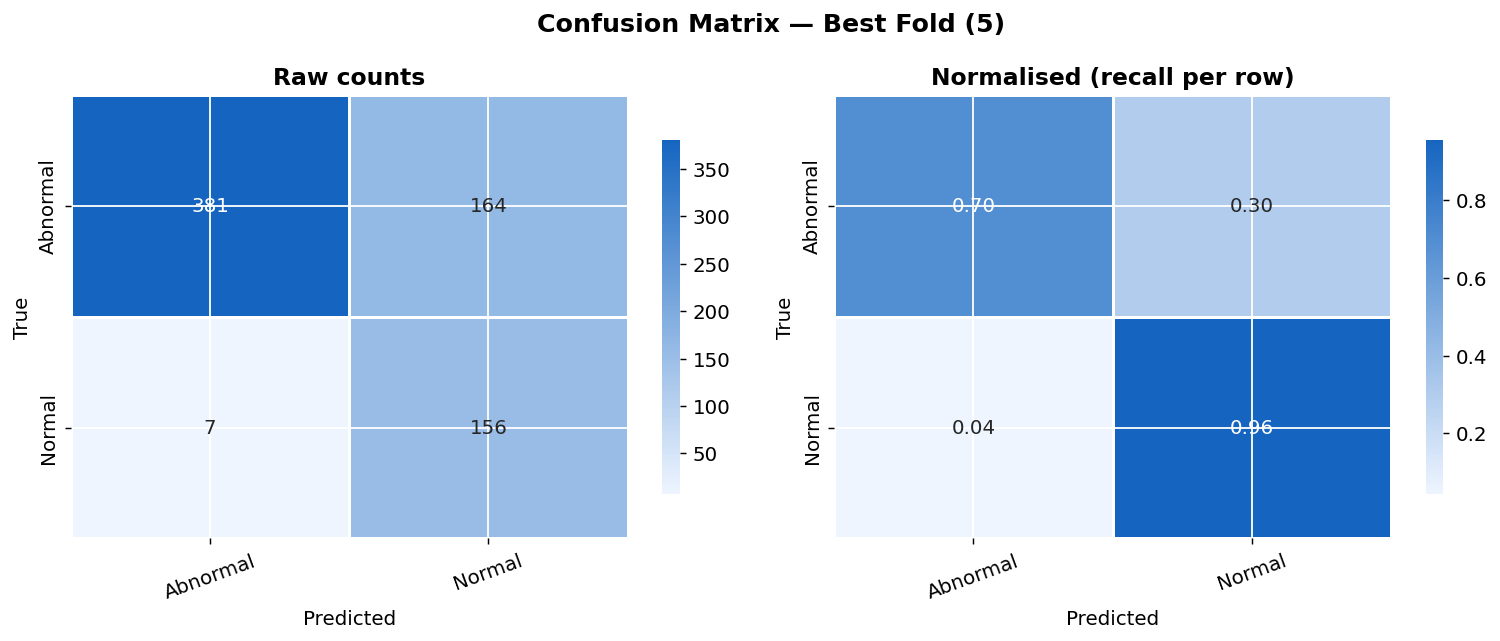

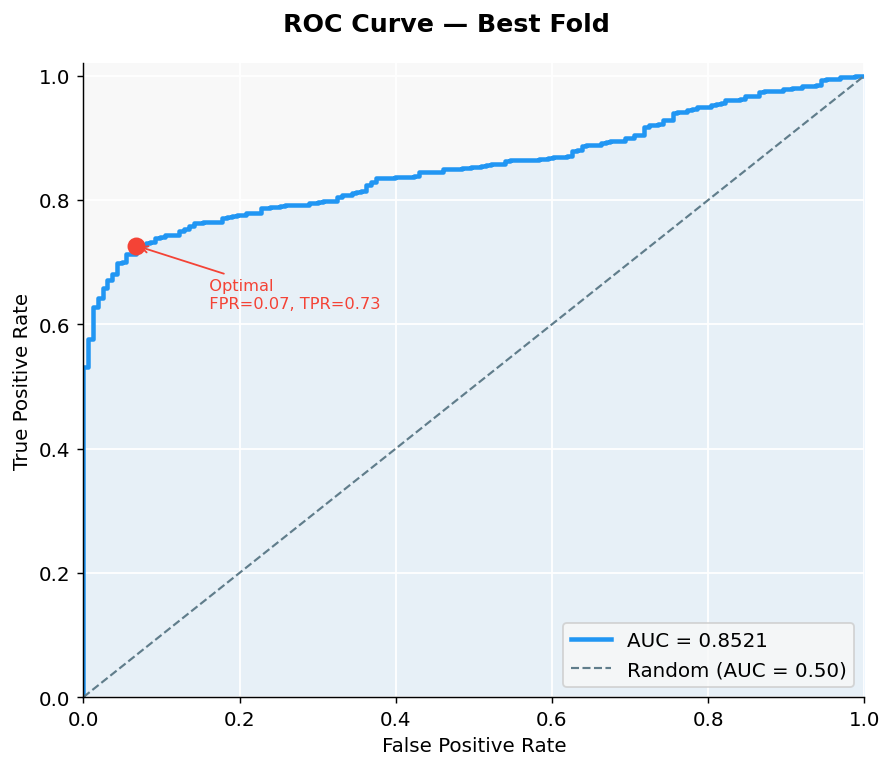

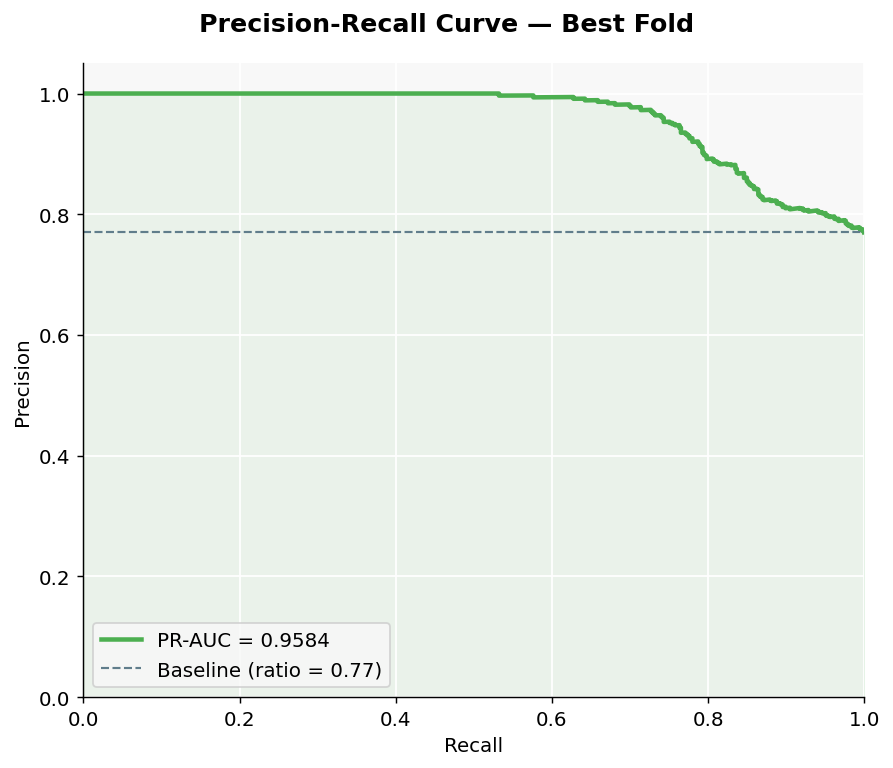


Classification Report — Best Fold:
              precision    recall  f1-score   support

    Abnormal       0.98      0.70      0.82       545
      Normal       0.49      0.96      0.65       163

    accuracy                           0.76       708
   macro avg       0.73      0.83      0.73       708
weighted avg       0.87      0.76      0.78       708



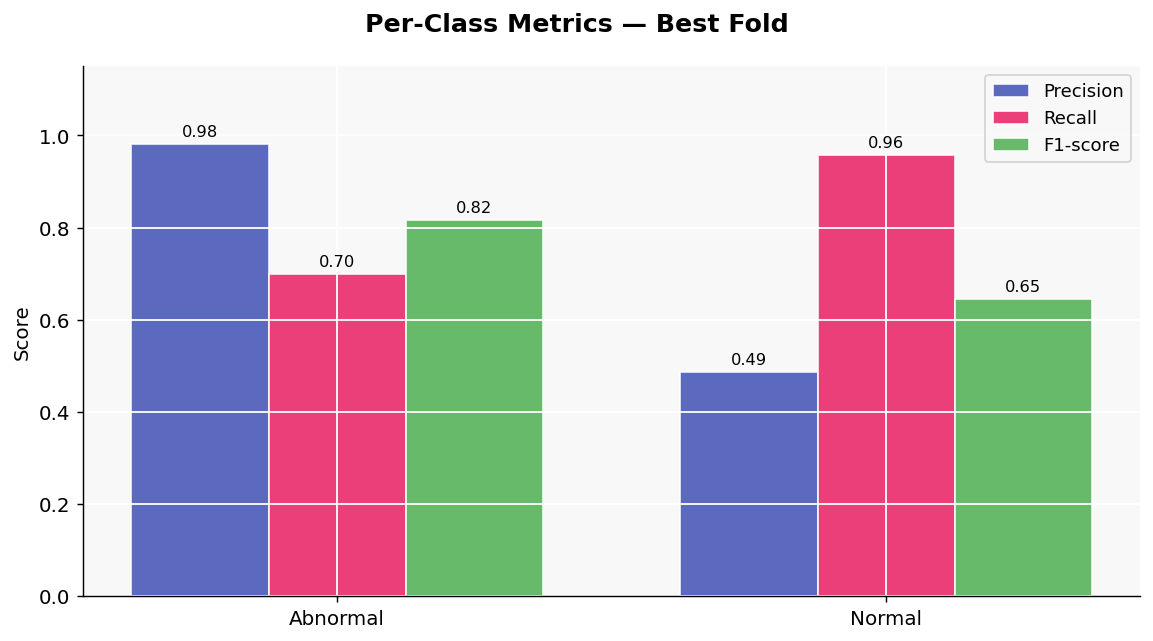

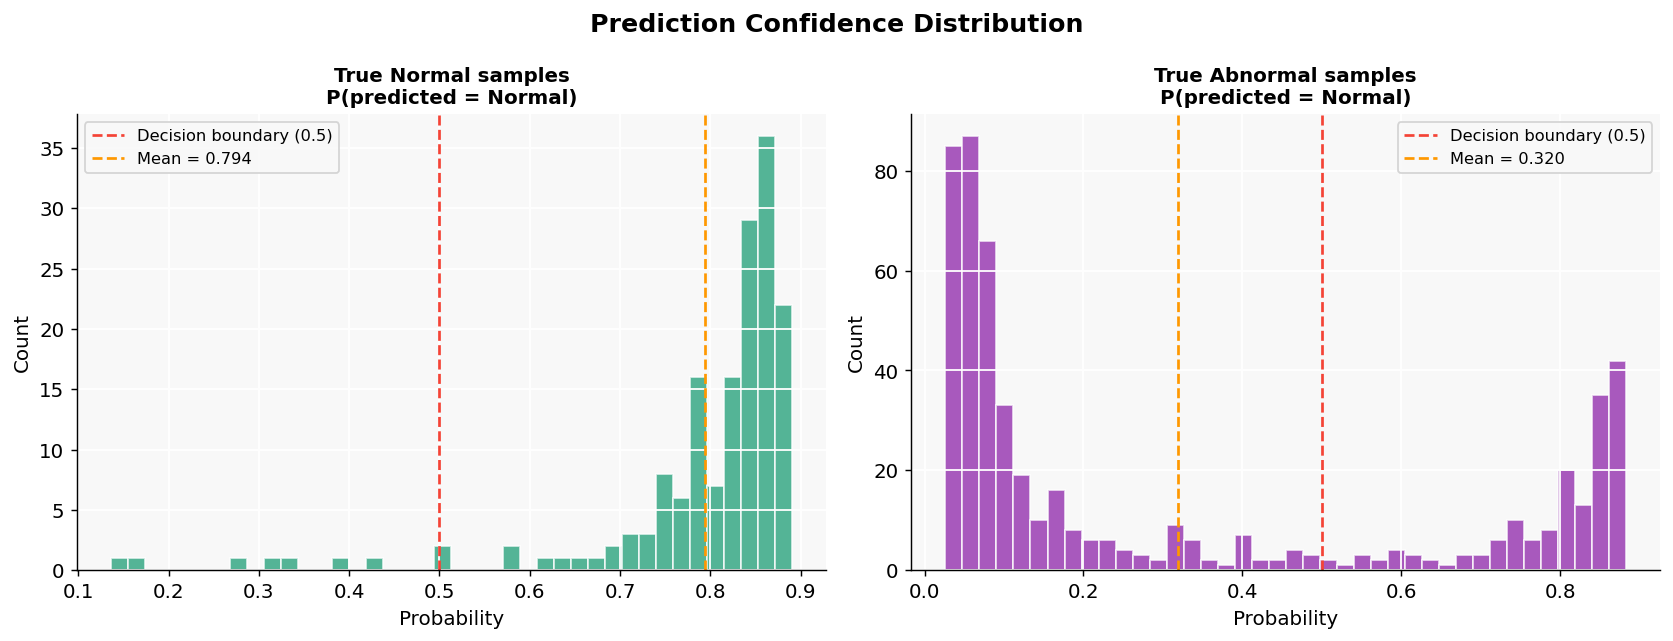

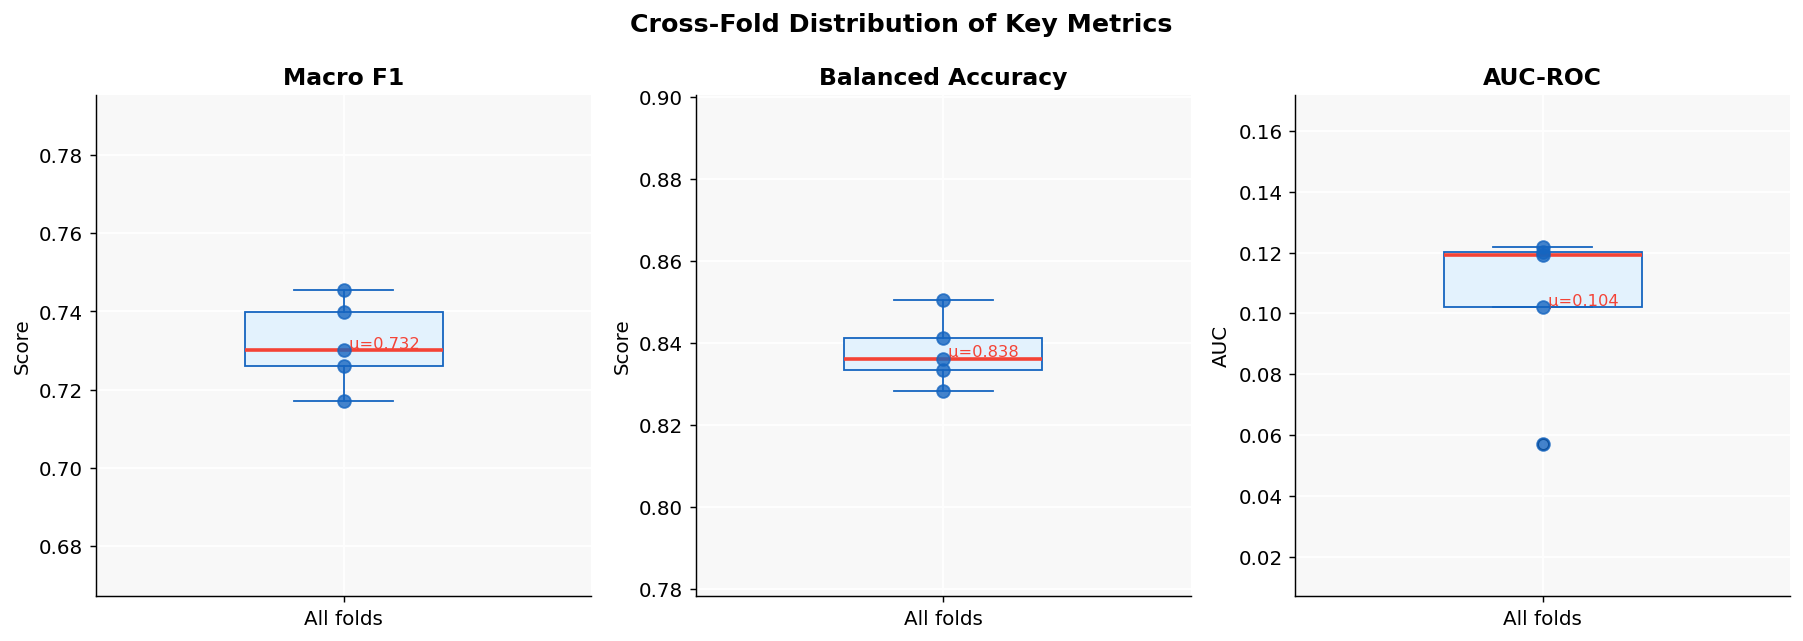


All post-training plots saved to ./outputs_new


In [32]:
# ── rebuild history from saved cv_results_cnn_lstm + re-evaluate best fold model ───────

# ─────────────────────────────────────────────────────────────────────────────
# helper — reload best fold model and collect predictions + probabilities
# ─────────────────────────────────────────────────────────────────────────────
@torch.no_grad()
def get_predictions(fold):
    ckpt = os.path.join(cfg.CHECKPOINT_DIR, f"fold{fold}_best.pt")
    model = build_model(n_classes)
    state = torch.load(ckpt, map_location=DEVICE)
    (model.module if isinstance(model, nn.DataParallel) else model).load_state_dict(state)
    model.eval()

    skf = StratifiedKFold(n_splits=cfg.N_FOLDS, shuffle=True, random_state=cfg.SEED)
    splits = list(skf.split(filepaths, labels_enc))
    _, val_idx = splits[fold - 1]

    val_fps = [filepaths[i] for i in val_idx]
    val_lbs = [labels_enc[i] for i in val_idx]
    val_ds  = HeartSoundDataset(val_fps, val_lbs, augment=False)
    val_loader = DataLoader(val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False,
                            num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY)

    all_preds, all_labels, all_probs = [], [], []
    for specs, labels in tqdm(val_loader, desc=f"Re-evaluating fold {fold}", leave=False):
        specs = specs.to(DEVICE)
        with get_autocast():
            logits, _ = model(specs)
        probs = torch.softmax(logits, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ─────────────────────────────────────────────────────────────────────────────
# load cv_results_cnn_lstm
# ─────────────────────────────────────────────────────────────────────────────
cv_df = pd.read_csv(os.path.join(cfg.OUTPUT_DIR, "cv_results_cnn_lstm.csv"))
print(cv_df.to_string(index=False))

targets_b, preds_b, probs_b = get_predictions(best_fold)


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 1 — Training history: Loss / Accuracy / F1 / AUC per epoch (best fold)
# ════════════════════════════════════════════════════════════════════════════════
# NOTE: run_training() already calls plot_training_curves() per fold inline.
# This plot reconstructs a cleaner version from the history dict if you saved it.
# To enable: add  `histories[fold] = history`  inside run_training()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 2 — Cross-fold metric comparison (bar chart)
# ════════════════════════════════════════════════════════════════════════════════
folds  = [f"Fold {int(r)}" for r in cv_df["fold"]]
x      = np.arange(len(folds)); w = 0.26

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle("Cross-Fold Performance Summary", fontsize=14, fontweight="bold")

b1 = ax.bar(x - w,   cv_df["f1"],      w, label="Macro F1",    color="#4CAF50", alpha=0.85)
b2 = ax.bar(x,       cv_df["bal_acc"], w, label="Balanced Acc", color="#9C27B0", alpha=0.85)
b3 = ax.bar(x + w,   cv_df["auc"],     w, label="AUC",          color="#FF5722", alpha=0.85)

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{bar.get_height():.3f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(folds)
ax.set_ylim(0.0, 1.10); ax.set_ylabel("Score"); ax.legend()
ax.axhline(cv_df["auc"].mean(), color="#FF5722", linestyle="--",
           linewidth=1.2, alpha=0.5, label=f"Mean AUC {cv_df['auc'].mean():.3f}")

# mean ± std annotation
ax.text(0.98, 0.05,
        f"F1   : {cv_df['f1'].mean():.3f} ± {cv_df['f1'].std():.3f}\n"
        f"Bal  : {cv_df['bal_acc'].mean():.3f} ± {cv_df['bal_acc'].std():.3f}\n"
        f"AUC  : {cv_df['auc'].mean():.3f} ± {cv_df['auc'].std():.3f}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
        family="monospace",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#F3E5F5",
                  edgecolor="#9C27B0", alpha=0.85))

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_01_crossfold_summary.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 3 — Confusion matrix (best fold, raw + normalised)
# ════════════════════════════════════════════════════════════════════════════════
cm      = confusion_matrix(targets_b, preds_b)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f"Confusion Matrix — Best Fold ({best_fold})",
             fontsize=14, fontweight="bold")

cmap = LinearSegmentedColormap.from_list("bw", ["#EEF5FF", "#1565C0"])
for ax, data, fmt, title in [
    (axes[0], cm,      "d",   "Raw counts"),
    (axes[1], cm_norm, ".2f", "Normalised (recall per row)"),
]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                xticklabels=label_names, yticklabels=label_names,
                linewidths=0.8, linecolor="white", cbar_kws={"shrink": 0.8})
    ax.set_title(title); ax.set_ylabel("True"); ax.set_xlabel("Predicted")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_02_confusion_matrix.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 4 — ROC curve + AUC
# ════════════════════════════════════════════════════════════════════════════════
fpr, tpr, _ = roc_curve(targets_b, probs_b[:, 0], pos_label=0)
roc_auc_val = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))
fig.suptitle("ROC Curve — Best Fold", fontsize=14, fontweight="bold")

ax.plot(fpr, tpr, color="#2196F3", linewidth=2.5,
        label=f"AUC = {roc_auc_val:.4f}")
ax.fill_between(fpr, tpr, alpha=0.08, color="#2196F3")
ax.plot([0, 1], [0, 1], color="#607D8B", linestyle="--",
        linewidth=1.2, label="Random (AUC = 0.50)")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=11)

# annotate optimal threshold (Youden's J)
j_scores = tpr - fpr
opt_idx  = np.argmax(j_scores)
ax.scatter(fpr[opt_idx], tpr[opt_idx], color="#F44336", zorder=5, s=80,
           label=f"Optimal threshold")
ax.annotate(f"  Optimal\n  FPR={fpr[opt_idx]:.2f}, TPR={tpr[opt_idx]:.2f}",
            xy=(fpr[opt_idx], tpr[opt_idx]),
            xytext=(fpr[opt_idx] + 0.08, tpr[opt_idx] - 0.10),
            fontsize=9, color="#F44336",
            arrowprops=dict(arrowstyle="->", color="#F44336", lw=1.0))

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_03_roc_curve.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 5 — Precision-Recall curve
# ════════════════════════════════════════════════════════════════════════════════
precision, recall, _ = precision_recall_curve(targets_b, probs_b[:, 0], pos_label=0)
pr_auc = auc(recall, precision)
baseline = 1 - targets_b.mean()   # positive class ratio

fig, ax = plt.subplots(figsize=(7, 6))
fig.suptitle("Precision-Recall Curve — Best Fold", fontsize=14, fontweight="bold")

ax.plot(recall, precision, color="#4CAF50", linewidth=2.5,
        label=f"PR-AUC = {pr_auc:.4f}")
ax.fill_between(recall, precision, alpha=0.08, color="#4CAF50")
ax.axhline(baseline, color="#607D8B", linestyle="--", linewidth=1.2,
           label=f"Baseline (ratio = {baseline:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.legend(loc="lower left", fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_04_precision_recall.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 6 — Per-class metrics bar (Precision / Recall / F1 for Normal & Abnormal)
# ════════════════════════════════════════════════════════════════════════════════
report = classification_report(targets_b, preds_b, target_names=label_names,
                                output_dict=True, zero_division=0)
print("\nClassification Report — Best Fold:")
print(classification_report(targets_b, preds_b, target_names=label_names, zero_division=0))

metrics   = ["precision", "recall", "f1-score"]
x         = np.arange(len(label_names)); w = 0.25
bar_colors = ["#3F51B5", "#E91E63", "#4CAF50"]

fig, ax = plt.subplots(figsize=(9, 5))
fig.suptitle("Per-Class Metrics — Best Fold", fontsize=14, fontweight="bold")

for i, (metric, col) in enumerate(zip(metrics, bar_colors)):
    vals = [report[cls][metric] for cls in label_names]
    bars = ax.bar(x + (i - 1) * w, vals, w, label=metric.capitalize(),
                  color=col, alpha=0.85, edgecolor="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01, f"{v:.2f}",
                ha="center", va="bottom", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(label_names)
ax.set_ylim(0, 1.15); ax.set_ylabel("Score"); ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_05_per_class_metrics.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 7 — Prediction confidence distribution (Normal vs Abnormal)
# ════════════════════════════════════════════════════════════════════════════════
prob_normal   = probs_b[targets_b == 1, 1]   # P(Normal) for true Normal
prob_abnormal = probs_b[targets_b == 0, 1]   # P(Normal) for true Abnormal

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Prediction Confidence Distribution", fontsize=14, fontweight="bold")

for ax, probs_cls, col, title in [
    (axes[0], prob_normal,   "#1D9E75", "True Normal samples\nP(predicted = Normal)"),
    (axes[1], prob_abnormal, "#8E24AA", "True Abnormal samples\nP(predicted = Normal)"),
]:
    ax.hist(probs_cls, bins=40, color=col, alpha=0.75, edgecolor="white")
    ax.axvline(0.5, color="#F44336", linestyle="--", linewidth=1.5, label="Decision boundary (0.5)")
    ax.axvline(probs_cls.mean(), color="#FF9800", linestyle="--", linewidth=1.5,
               label=f"Mean = {probs_cls.mean():.3f}")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Probability"); ax.set_ylabel("Count")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_06_confidence_distribution.png"), bbox_inches="tight")
plt.show()


# ════════════════════════════════════════════════════════════════════════════════
# PLOT 8 — Train vs Val accuracy & loss across folds (box plots)
# ════════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle("Cross-Fold Distribution of Key Metrics", fontsize=14, fontweight="bold")

for ax, col, ylabel, title in [
    (axes[0], "f1",      "Score", "Macro F1"),
    (axes[1], "bal_acc", "Score", "Balanced Accuracy"),
    (axes[2], "auc",     "AUC",   "AUC-ROC"),
]:
    vals = cv_df[col].values
    bp   = ax.boxplot(vals, patch_artist=True, widths=0.4,
                      boxprops=dict(facecolor="#E3F2FD", color="#1565C0"),
                      medianprops=dict(color="#F44336", linewidth=2),
                      whiskerprops=dict(color="#1565C0"),
                      capprops=dict(color="#1565C0"),
                      flierprops=dict(marker="o", color="#FF9800", markersize=6))
    ax.scatter([1] * len(vals), vals, color="#1565C0", zorder=5,
               s=50, alpha=0.8, label="Fold scores")
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.set_xticks([1]); ax.set_xticklabels(["All folds"])
    ax.set_ylim(max(0, vals.min() - 0.05), min(1.0, vals.max() + 0.05))
    ax.text(1, vals.mean(), f" μ={vals.mean():.3f}", va="center",
            fontsize=9, color="#F44336")

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "PT_07_crossfold_boxplot.png"), bbox_inches="tight")
plt.show()

print("\nAll post-training plots saved to", cfg.OUTPUT_DIR)

## Inference Example

In [33]:
# label, probs, attn = predict(
#     model_path  = f"./checkpoints/fold{best_fold}_best.pt",
#     filepath    = "./test_sample.wav",
#     label_names = label_names,
#     n_classes   = n_classes,
#     visualize   = True,
# )

In [34]:
# ─────────────────────────────────────────────────────────────────────────────
# Simple CNN baseline — same ConvBlocks as CNN+LSTM but replaces
# BiLSTM + Attention with a single GlobalAvgPool. This isolates the
# contribution of temporal modelling in the proposed architecture.
# ─────────────────────────────────────────────────────────────────────────────

class SimpleCNN(nn.Module):
    """
    Baseline model.
    Input  (B, 1, F, T)
    → 4× ConvBlock  → GlobalAvgPool  → Dropout  → FC  → logits
    No LSTM, no attention. Treats spectrogram as a static 2D image.
    Returns (logits, None) to stay compatible with evaluate() and predict().
    """
    def __init__(self, n_classes, cnn_channels, dropout, n_mels=64):
        super().__init__()
        channels = [1] + cnn_channels
        self.cnn_blocks = nn.ModuleList([
            ConvBlock(channels[i], channels[i+1])
            for i in range(len(cnn_channels))
        ])
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))   # global avg pool
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(cnn_channels[-1], n_classes)

    def forward(self, x):
        for block in self.cnn_blocks:
            x = block(x)
        x = self.pool(x).squeeze(-1).squeeze(-1)      # (B, C)
        x = self.dropout(x)
        return self.fc(x), None                        # None keeps API consistent


print("SimpleCNN baseline + updated build_model / run_training ready")

SimpleCNN baseline + updated build_model / run_training ready


# Baseline Model: Simple CNN (no temporal modelling)


████████████████████████████████████████████████████████████
Simple CNN (baseline)
████████████████████████████████████████████████████████████

  FOLD 1/5  |  model: simple_cnn  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.172


  Ep 001 [36.5s  MPS mem 0.02GB] | TrLoss 0.1504 TrAcc 0.493 | VlLoss 0.1275 VlAcc 0.231 F1 0.188 AUC 0.233 BalAcc 0.500


  Ep 002 [39.1s  MPS mem 0.02GB] | TrLoss 0.1239 TrAcc 0.496 | VlLoss 0.1093 VlAcc 0.231 F1 0.188 AUC 0.194 BalAcc 0.500


  Ep 003 [34.5s  MPS mem 0.02GB] | TrLoss 0.1093 TrAcc 0.500 | VlLoss 0.1393 VlAcc 0.233 F1 0.190 AUC 0.187 BalAcc 0.501


  Ep 004 [32.3s  MPS mem 0.02GB] | TrLoss 0.1004 TrAcc 0.515 | VlLoss 0.1899 VlAcc 0.261 F1 0.230 AUC 0.193 BalAcc 0.519


  Ep 005 [32.1s  MPS mem 0.02GB] | TrLoss 0.0941 TrAcc 0.556 | VlLoss 0.0853 VlAcc 0.528 F1 0.525 AUC 0.168 BalAcc 0.691


... (19 outputs left out)

  Ep 025 [33.2s  MPS mem 0.02GB] | TrLoss 0.0754 TrAcc 0.674 | VlLoss 0.1048 VlAcc 0.530 F1 0.528 AUC 0.123 BalAcc 0.694


  Ep 026 [32.7s  MPS mem 0.02GB] | TrLoss 0.0759 TrAcc 0.677 | VlLoss 0.0682 VlAcc 0.650 F1 0.637 AUC 0.120 BalAcc 0.772


  Ep 027 [32.6s  MPS mem 0.02GB] | TrLoss 0.0784 TrAcc 0.658 | VlLoss 0.0898 VlAcc 0.523 F1 0.522 AUC 0.122 BalAcc 0.690
  ⏹ Early stopping at epoch 27



  ✅ Fold 1 Best → F1: 0.6911  BalAcc: 0.7867  AUC: 0.1751
              precision    recall  f1-score   support

    Abnormal       0.96      0.66      0.78       545
      Normal       0.45      0.91      0.60       164

    accuracy                           0.72       709
   macro avg       0.70      0.79      0.69       709
weighted avg       0.84      0.72      0.74       709



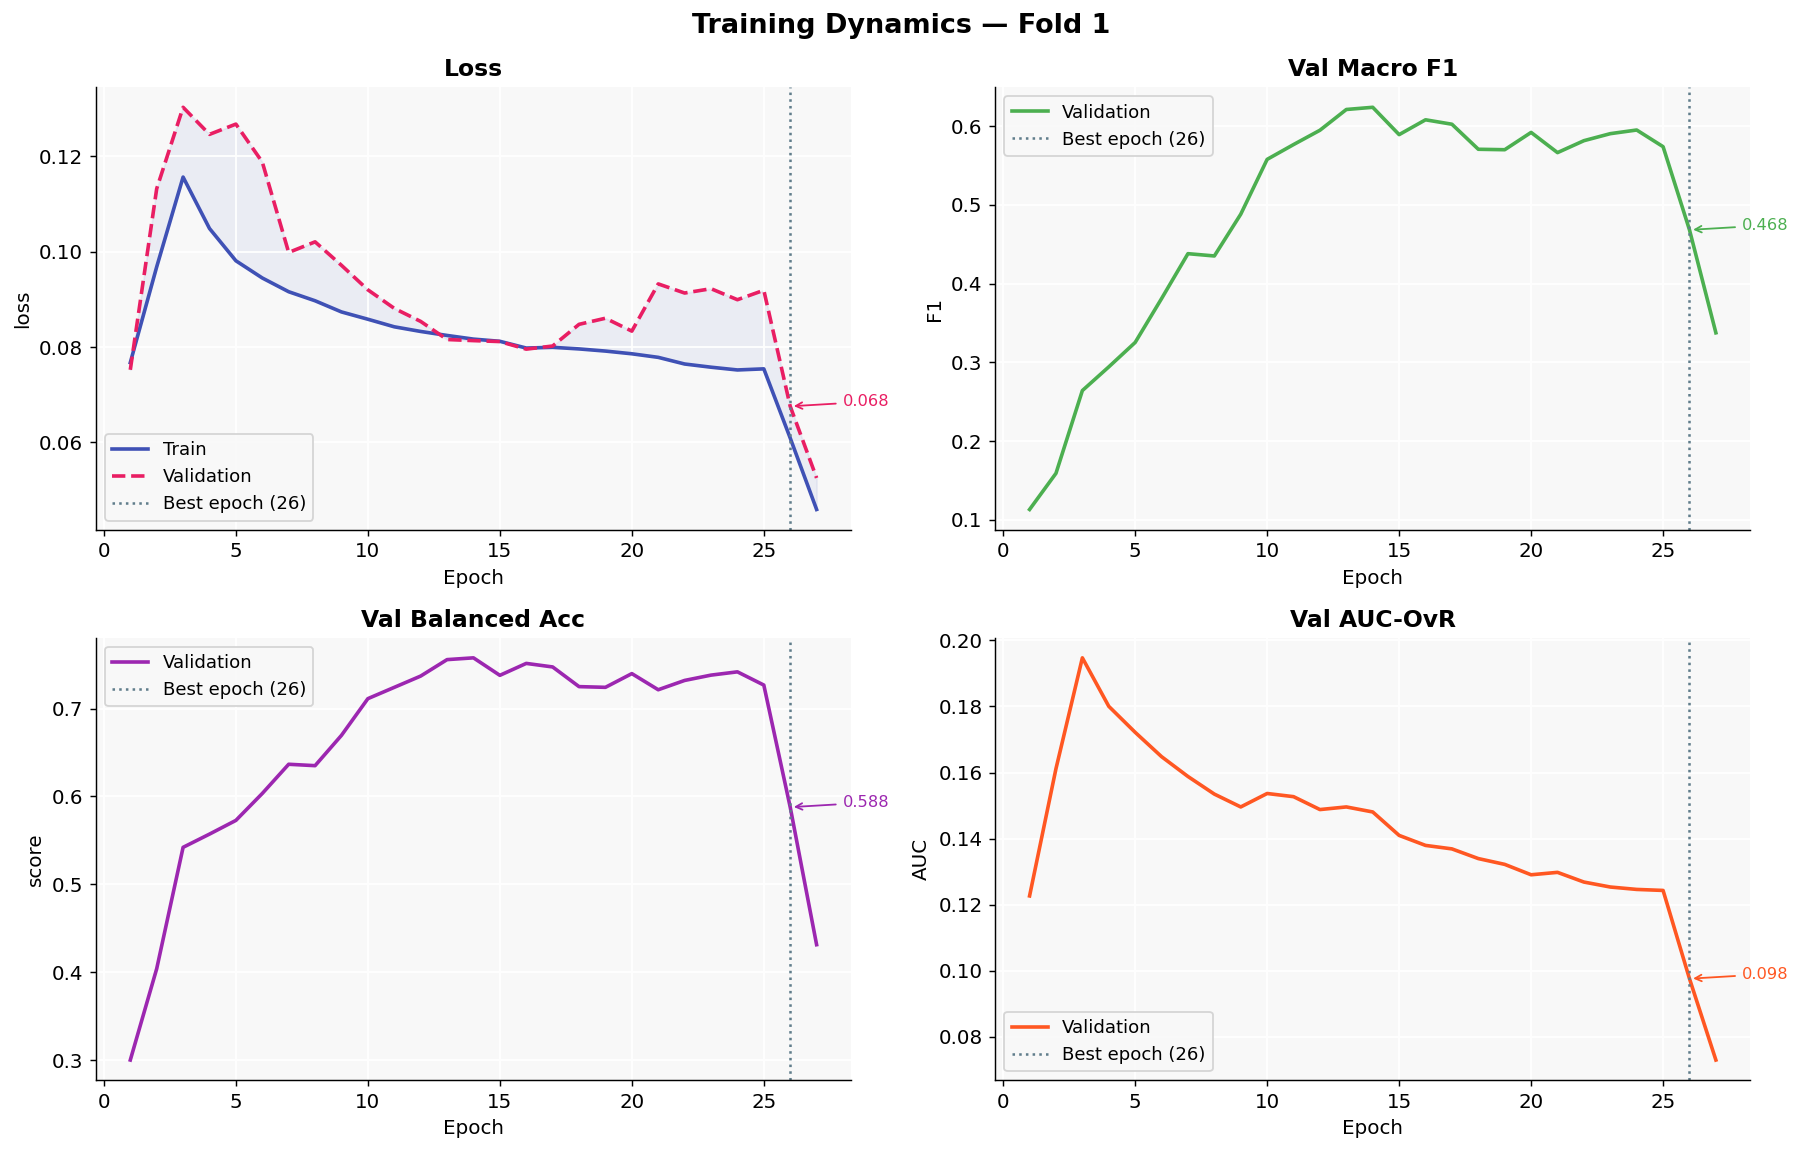

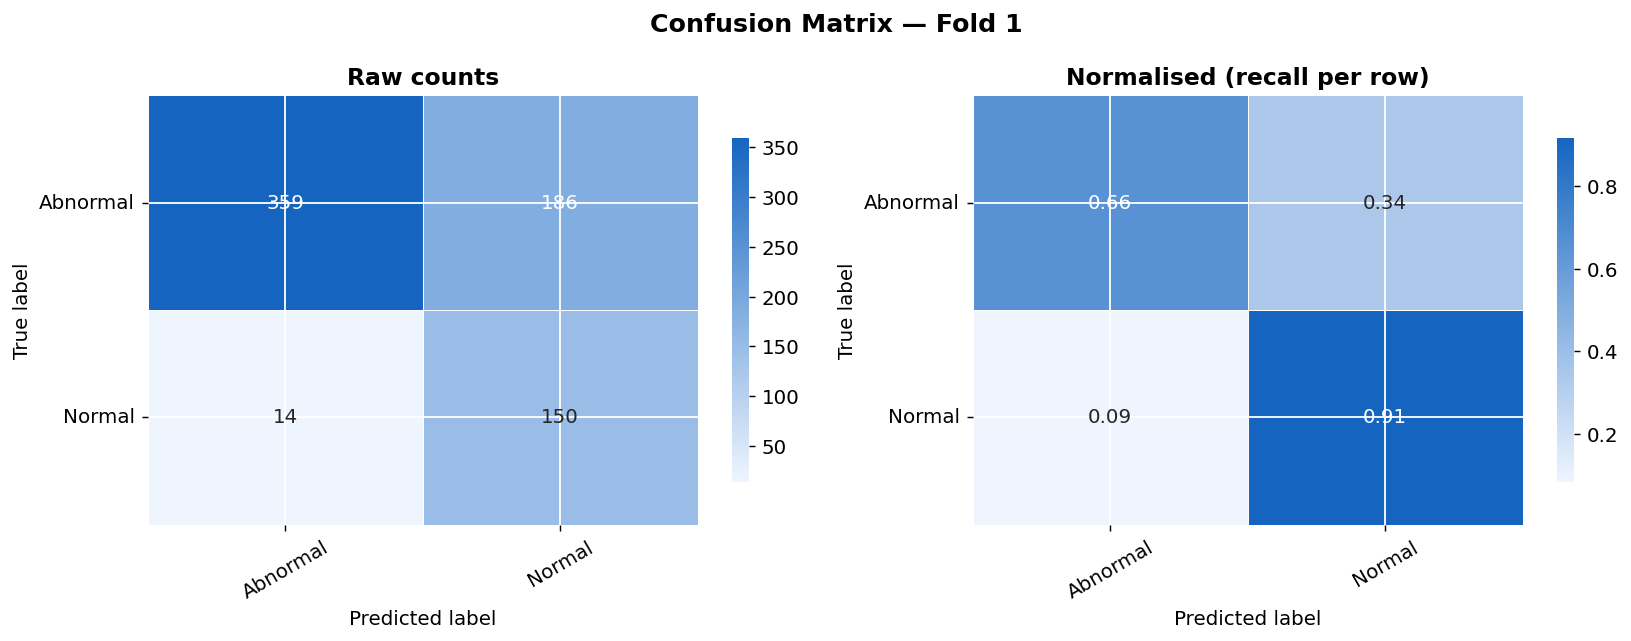

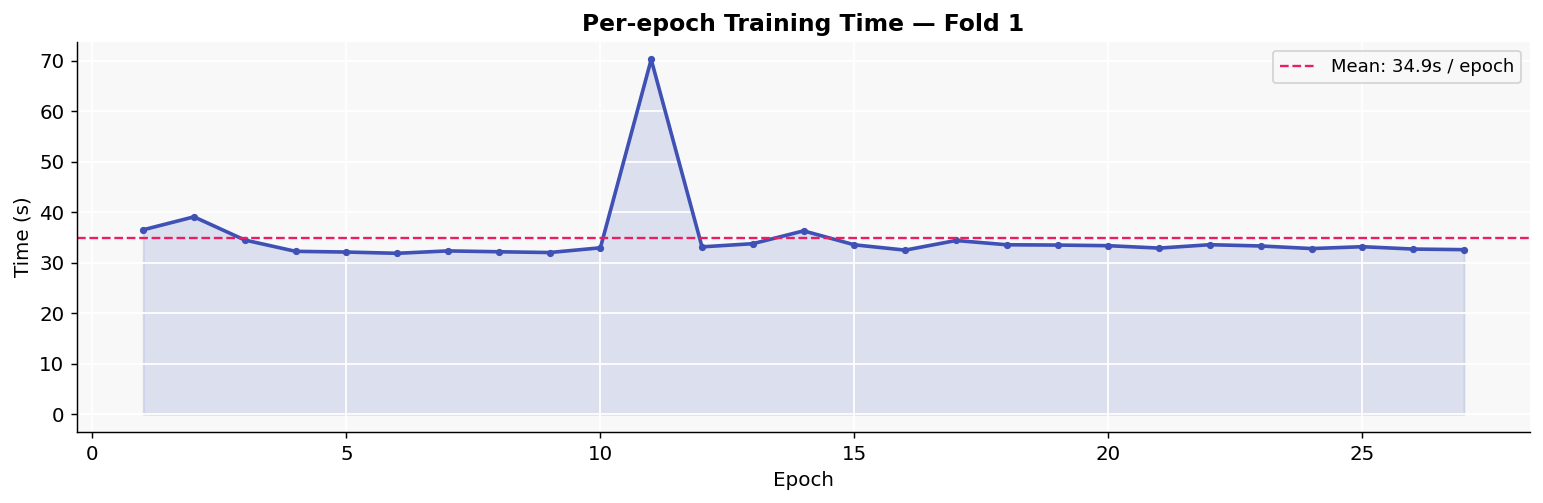


  FOLD 2/5  |  model: simple_cnn  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [33.7s  MPS mem 0.05GB] | TrLoss 0.1746 TrAcc 0.487 | VlLoss 0.1067 VlAcc 0.230 F1 0.187 AUC 0.260 BalAcc 0.500


  Ep 002 [33.2s  MPS mem 0.05GB] | TrLoss 0.1270 TrAcc 0.496 | VlLoss 0.1112 VlAcc 0.239 F1 0.199 AUC 0.245 BalAcc 0.506


  Ep 003 [33.3s  MPS mem 0.05GB] | TrLoss 0.1166 TrAcc 0.502 | VlLoss 0.1113 VlAcc 0.230 F1 0.187 AUC 0.159 BalAcc 0.500


  Ep 004 [33.0s  MPS mem 0.05GB] | TrLoss 0.1030 TrAcc 0.515 | VlLoss 0.0993 VlAcc 0.285 F1 0.263 AUC 0.141 BalAcc 0.536


  Ep 005 [32.8s  MPS mem 0.05GB] | TrLoss 0.0977 TrAcc 0.533 | VlLoss 0.1190 VlAcc 0.299 F1 0.281 AUC 0.145 BalAcc 0.545


... (72 outputs left out)

  Ep 078 [35.5s  MPS mem 0.05GB] | TrLoss 0.0550 TrAcc 0.778 | VlLoss 0.0579 VlAcc 0.744 F1 0.721 AUC 0.067 BalAcc 0.830


  Ep 079 [37.3s  MPS mem 0.05GB] | TrLoss 0.0572 TrAcc 0.761 | VlLoss 0.0587 VlAcc 0.737 F1 0.715 AUC 0.067 BalAcc 0.825


  Ep 080 [33.3s  MPS mem 0.05GB] | TrLoss 0.0579 TrAcc 0.764 | VlLoss 0.0586 VlAcc 0.737 F1 0.715 AUC 0.067 BalAcc 0.825



  ✅ Fold 2 Best → F1: 0.7248  BalAcc: 0.8324  AUC: 0.0667
              precision    recall  f1-score   support

    Abnormal       0.99      0.68      0.81       545
      Normal       0.48      0.99      0.64       163

    accuracy                           0.75       708
   macro avg       0.74      0.83      0.72       708
weighted avg       0.88      0.75      0.77       708



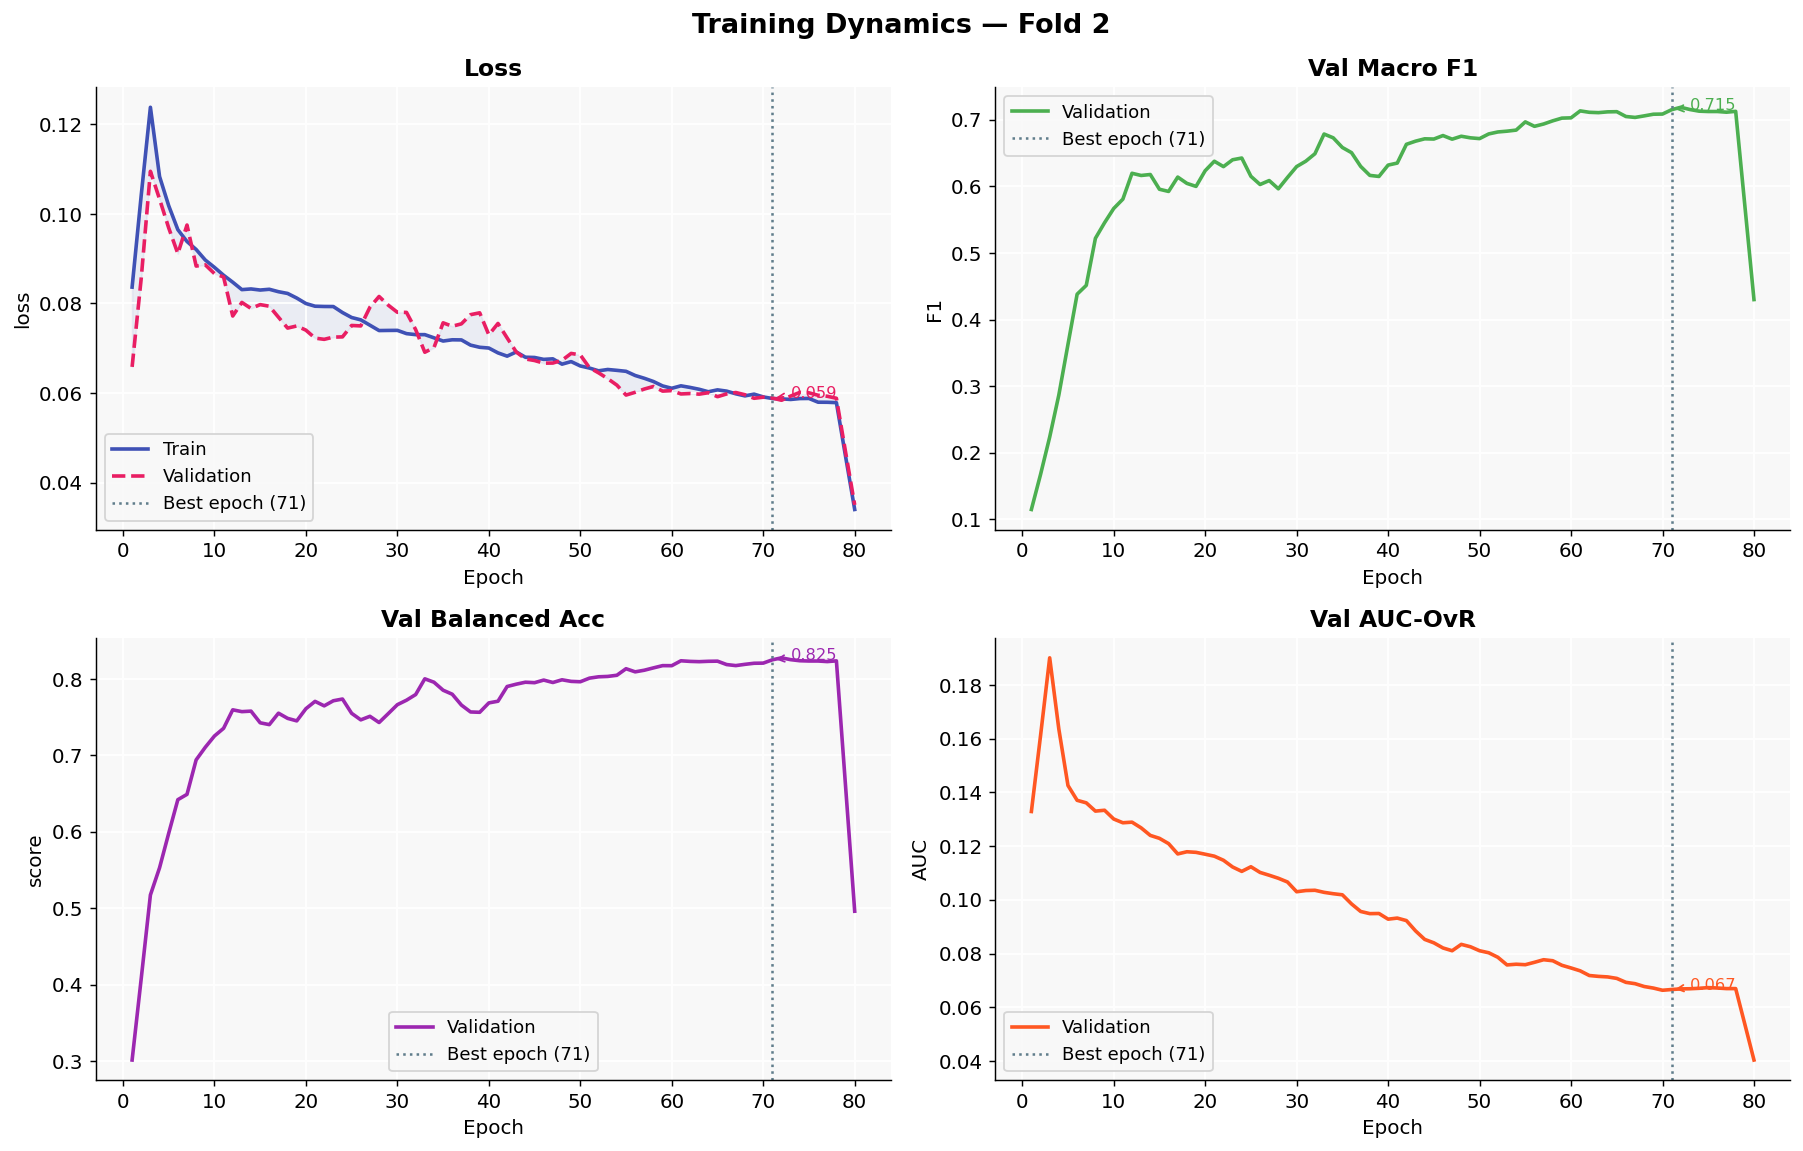

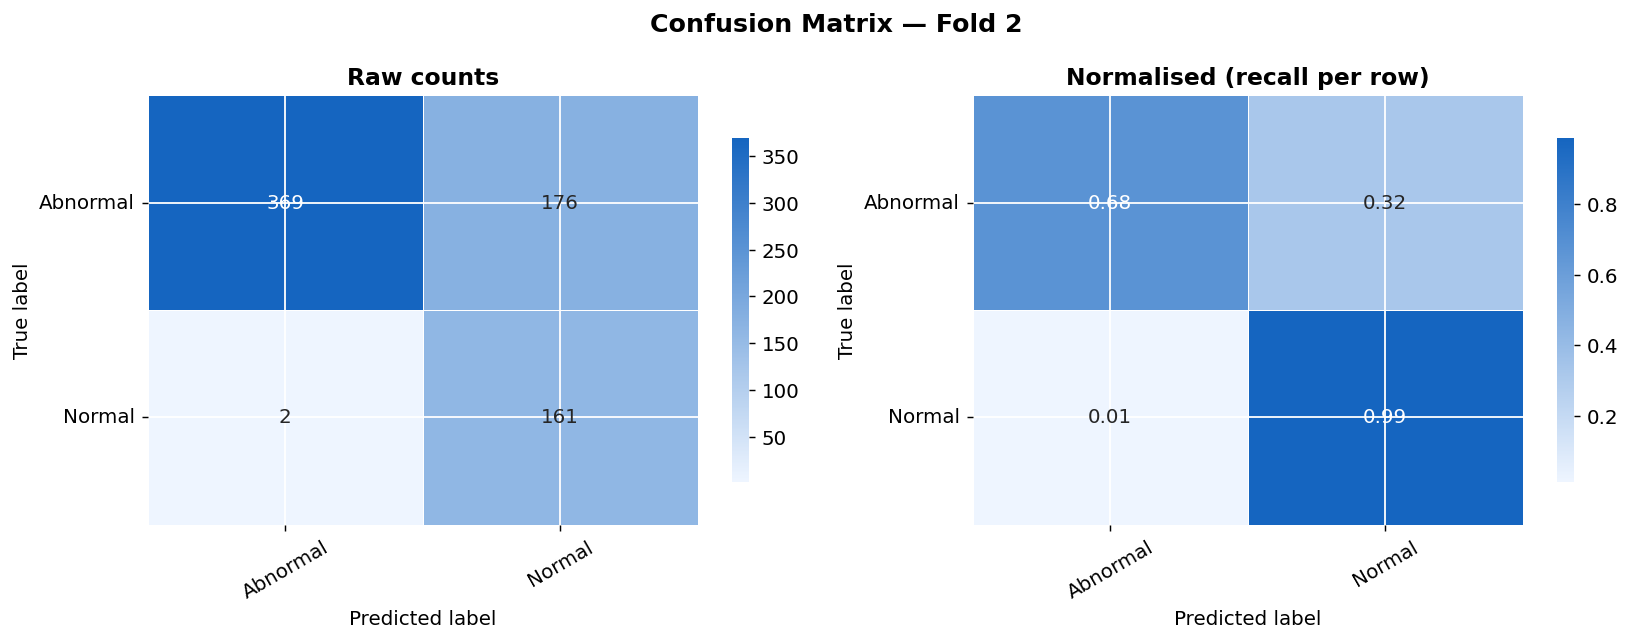

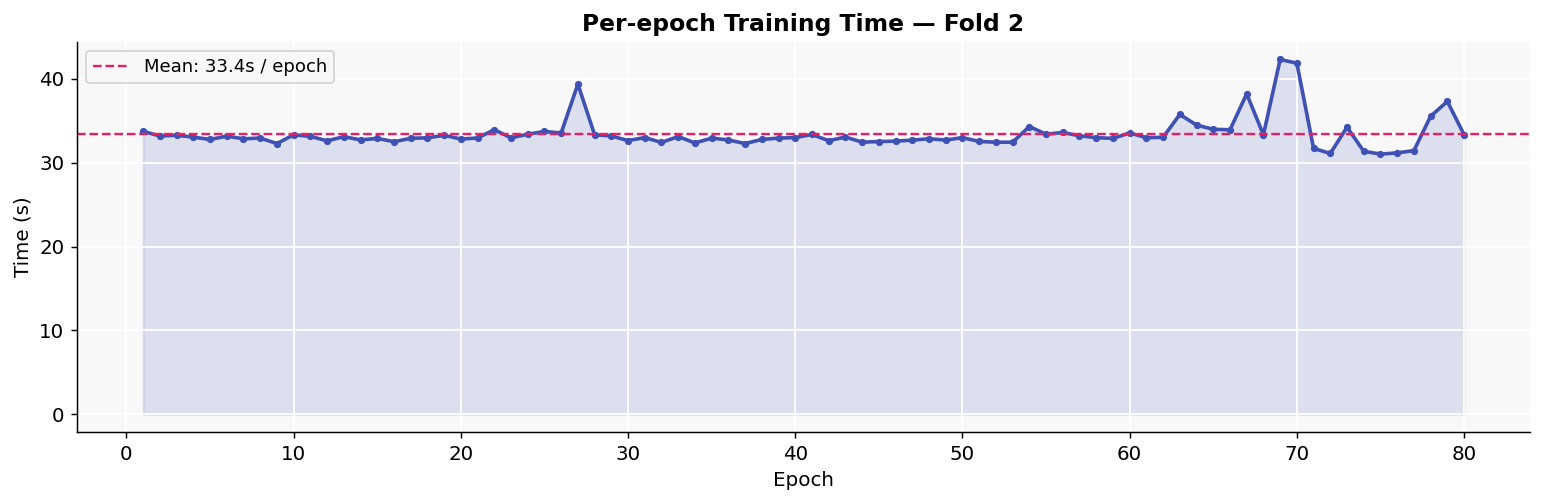


  FOLD 3/5  |  model: simple_cnn  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [41.4s  MPS mem 0.03GB] | TrLoss 0.1655 TrAcc 0.497 | VlLoss 0.1177 VlAcc 0.253 F1 0.222 AUC 0.307 BalAcc 0.508


  Ep 002 [36.0s  MPS mem 0.03GB] | TrLoss 0.1256 TrAcc 0.492 | VlLoss 0.1208 VlAcc 0.230 F1 0.187 AUC 0.188 BalAcc 0.500


  Ep 003 [35.5s  MPS mem 0.03GB] | TrLoss 0.1117 TrAcc 0.509 | VlLoss 0.0916 VlAcc 0.323 F1 0.311 AUC 0.177 BalAcc 0.561


  Ep 004 [32.0s  MPS mem 0.03GB] | TrLoss 0.1031 TrAcc 0.520 | VlLoss 0.1346 VlAcc 0.232 F1 0.189 AUC 0.142 BalAcc 0.501


  Ep 005 [35.6s  MPS mem 0.03GB] | TrLoss 0.0970 TrAcc 0.572 | VlLoss 0.0980 VlAcc 0.315 F1 0.300 AUC 0.144 BalAcc 0.555


... (29 outputs left out)

  Ep 035 [32.9s  MPS mem 0.03GB] | TrLoss 0.0707 TrAcc 0.711 | VlLoss 0.0683 VlAcc 0.621 F1 0.611 AUC 0.081 BalAcc 0.754


  Ep 036 [32.4s  MPS mem 0.03GB] | TrLoss 0.0680 TrAcc 0.720 | VlLoss 0.0733 VlAcc 0.694 F1 0.675 AUC 0.085 BalAcc 0.794


  Ep 037 [33.5s  MPS mem 0.03GB] | TrLoss 0.0712 TrAcc 0.712 | VlLoss 0.0781 VlAcc 0.657 F1 0.643 AUC 0.082 BalAcc 0.777
  ⏹ Early stopping at epoch 37



  ✅ Fold 3 Best → F1: 0.7203  BalAcc: 0.8063  AUC: 0.1276
              precision    recall  f1-score   support

    Abnormal       0.96      0.70      0.81       545
      Normal       0.48      0.91      0.63       163

    accuracy                           0.75       708
   macro avg       0.72      0.81      0.72       708
weighted avg       0.85      0.75      0.77       708



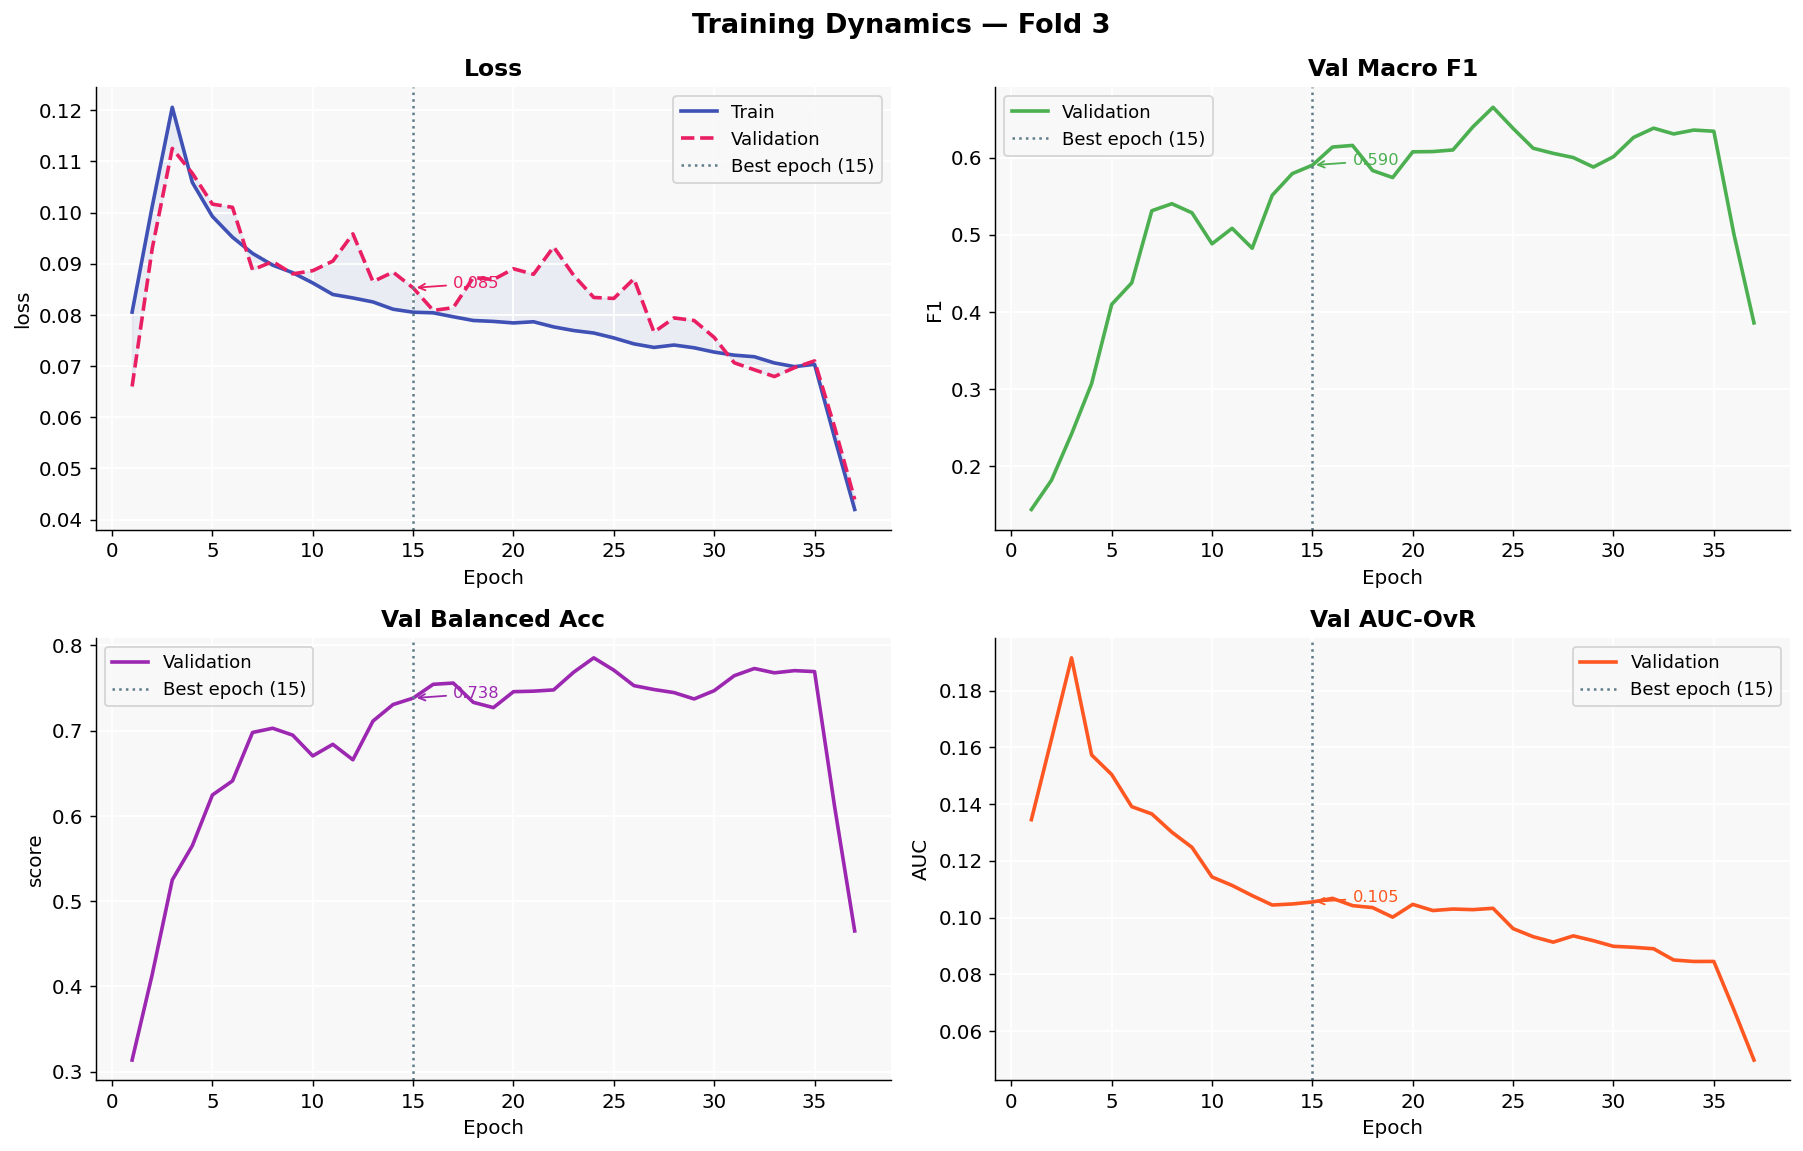

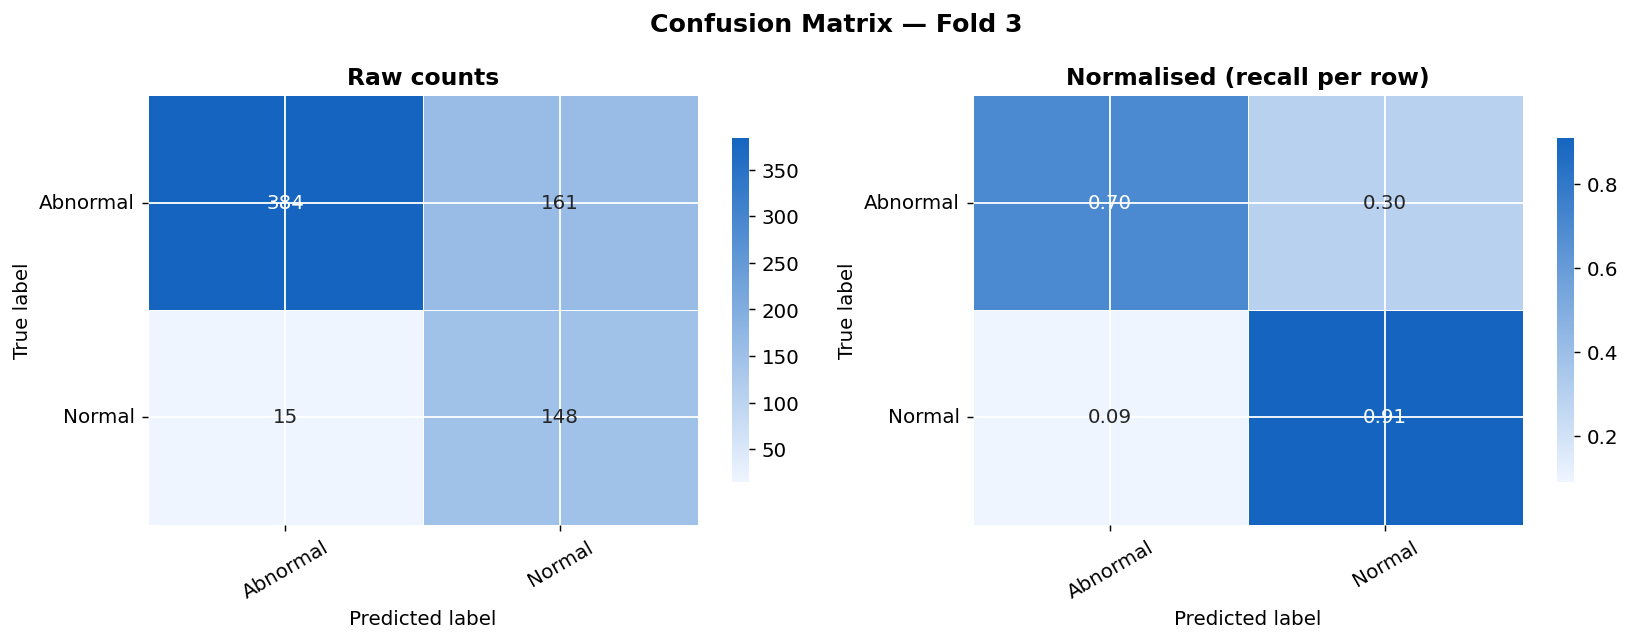

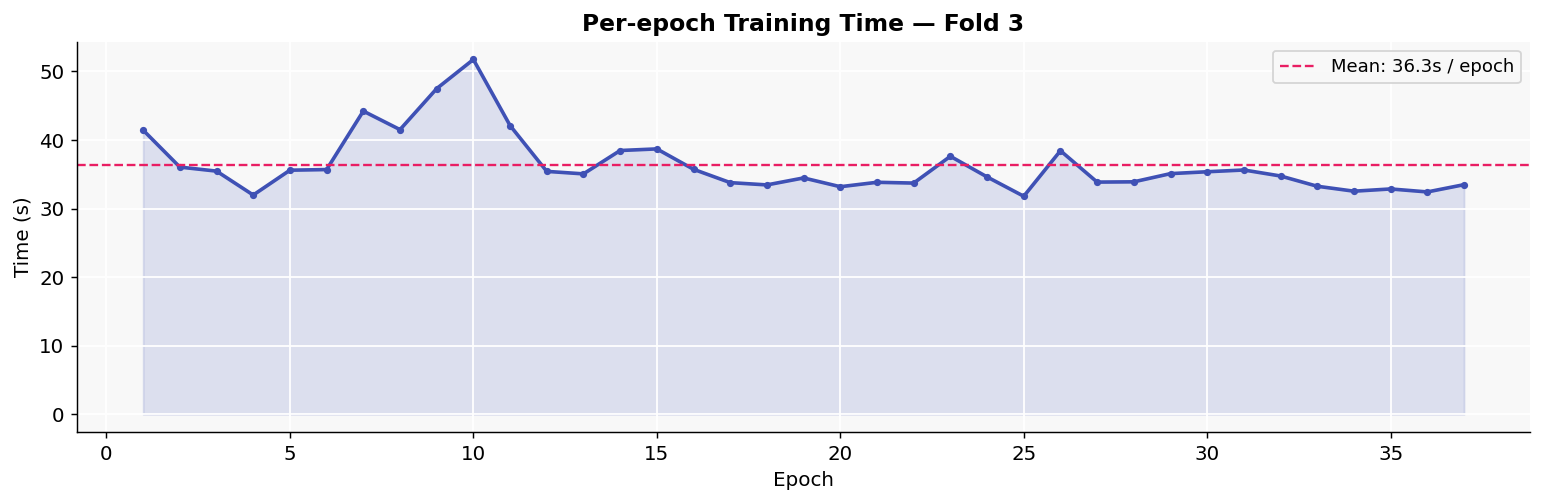


  FOLD 4/5  |  model: simple_cnn  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [32.9s  MPS mem 0.03GB] | TrLoss 0.1668 TrAcc 0.493 | VlLoss 0.1278 VlAcc 0.230 F1 0.187 AUC 0.298 BalAcc 0.500


  Ep 002 [33.2s  MPS mem 0.03GB] | TrLoss 0.1198 TrAcc 0.487 | VlLoss 0.0997 VlAcc 0.282 F1 0.261 AUC 0.239 BalAcc 0.527


  Ep 003 [33.0s  MPS mem 0.03GB] | TrLoss 0.1086 TrAcc 0.505 | VlLoss 0.0864 VlAcc 0.325 F1 0.312 AUC 0.170 BalAcc 0.561


  Ep 004 [33.9s  MPS mem 0.03GB] | TrLoss 0.0984 TrAcc 0.529 | VlLoss 0.1018 VlAcc 0.398 F1 0.396 AUC 0.163 BalAcc 0.609


  Ep 005 [33.1s  MPS mem 0.03GB] | TrLoss 0.0980 TrAcc 0.557 | VlLoss 0.0864 VlAcc 0.264 F1 0.235 AUC 0.175 BalAcc 0.522


... (22 outputs left out)

  Ep 028 [33.5s  MPS mem 0.03GB] | TrLoss 0.0746 TrAcc 0.683 | VlLoss 0.0721 VlAcc 0.712 F1 0.692 AUC 0.089 BalAcc 0.811


  Ep 029 [33.6s  MPS mem 0.03GB] | TrLoss 0.0770 TrAcc 0.674 | VlLoss 0.0734 VlAcc 0.709 F1 0.689 AUC 0.093 BalAcc 0.807


  Ep 030 [33.8s  MPS mem 0.03GB] | TrLoss 0.0757 TrAcc 0.683 | VlLoss 0.0694 VlAcc 0.664 F1 0.649 AUC 0.084 BalAcc 0.780
  ⏹ Early stopping at epoch 30



  ✅ Fold 4 Best → F1: 0.7068  BalAcc: 0.8196  AUC: 0.1307
              precision    recall  f1-score   support

    Abnormal       0.99      0.65      0.79       545
      Normal       0.46      0.99      0.63       163

    accuracy                           0.73       708
   macro avg       0.73      0.82      0.71       708
weighted avg       0.87      0.73      0.75       708



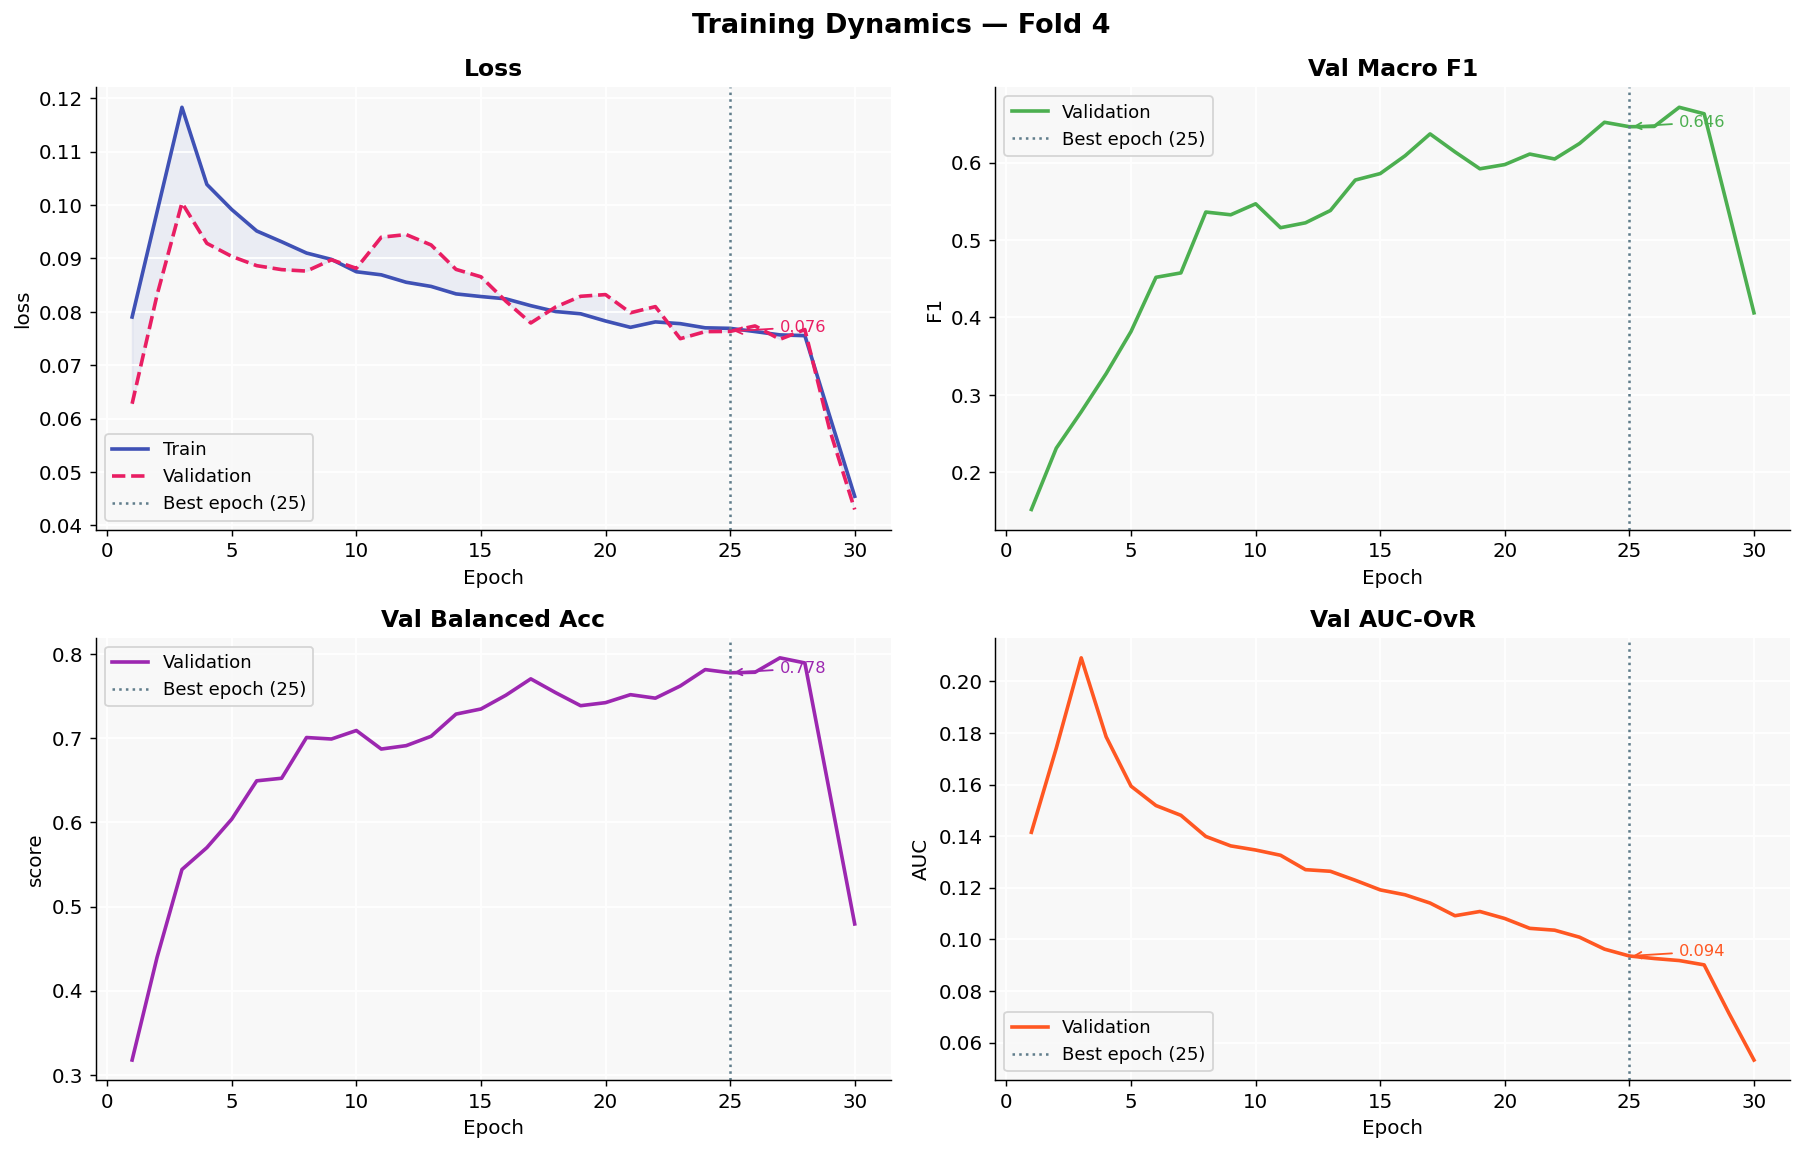

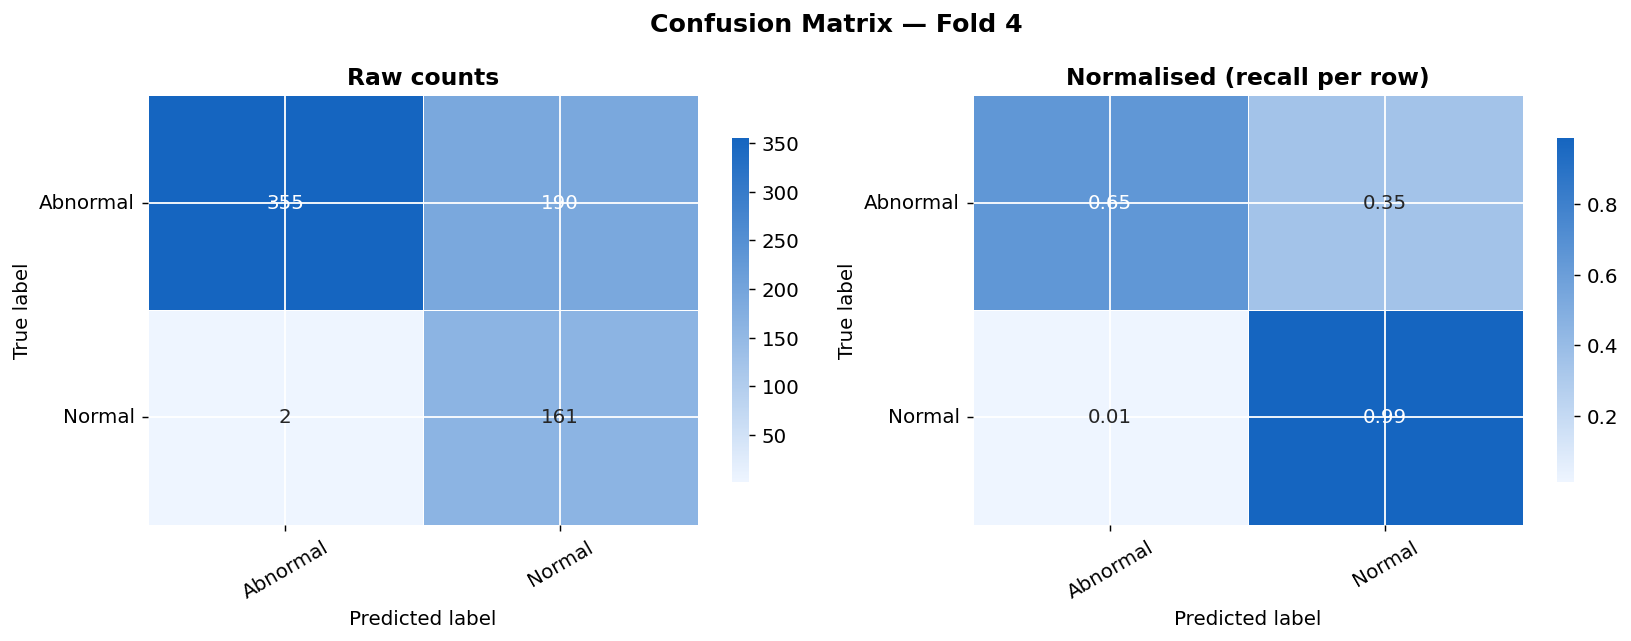

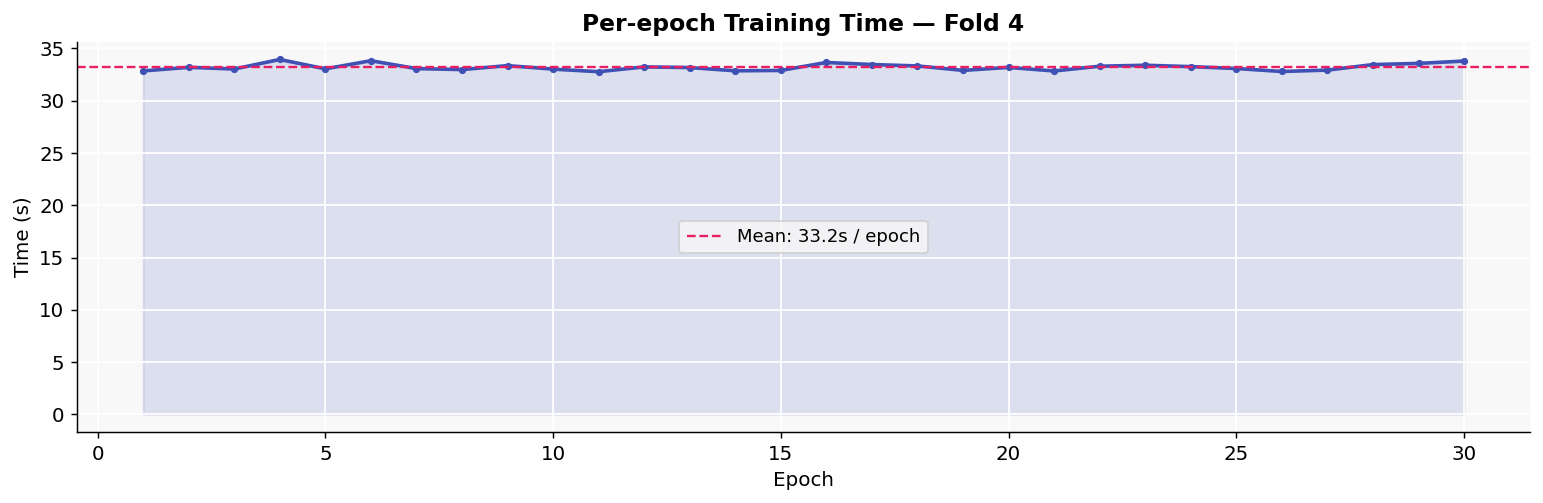


  FOLD 5/5  |  model: simple_cnn  |  device: mps  |  AMP: False
  Class weights → Abnormal (0): 0.650  Normal (1): 2.169


  Ep 001 [33.7s  MPS mem 0.04GB] | TrLoss 0.1550 TrAcc 0.502 | VlLoss 0.1161 VlAcc 0.230 F1 0.187 AUC 0.220 BalAcc 0.500


  Ep 002 [35.9s  MPS mem 0.04GB] | TrLoss 0.1180 TrAcc 0.502 | VlLoss 0.0856 VlAcc 0.305 F1 0.288 AUC 0.160 BalAcc 0.549


  Ep 003 [33.1s  MPS mem 0.04GB] | TrLoss 0.1061 TrAcc 0.507 | VlLoss 0.0870 VlAcc 0.376 F1 0.371 AUC 0.143 BalAcc 0.594


  Ep 004 [33.0s  MPS mem 0.04GB] | TrLoss 0.0981 TrAcc 0.542 | VlLoss 0.0790 VlAcc 0.387 F1 0.384 AUC 0.143 BalAcc 0.602


  Ep 005 [33.6s  MPS mem 0.04GB] | TrLoss 0.0945 TrAcc 0.556 | VlLoss 0.1107 VlAcc 0.323 F1 0.311 AUC 0.136 BalAcc 0.561


... (42 outputs left out)

  Ep 048 [34.1s  MPS mem 0.04GB] | TrLoss 0.0633 TrAcc 0.745 | VlLoss 0.0618 VlAcc 0.716 F1 0.696 AUC 0.080 BalAcc 0.816


  Ep 049 [33.1s  MPS mem 0.04GB] | TrLoss 0.0636 TrAcc 0.743 | VlLoss 0.0613 VlAcc 0.696 F1 0.678 AUC 0.075 BalAcc 0.803


  Ep 050 [33.7s  MPS mem 0.04GB] | TrLoss 0.0617 TrAcc 0.747 | VlLoss 0.0772 VlAcc 0.654 F1 0.640 AUC 0.077 BalAcc 0.775
  ⏹ Early stopping at epoch 50



  ✅ Fold 5 Best → F1: 0.7352  BalAcc: 0.8397  AUC: 0.0921
              precision    recall  f1-score   support

    Abnormal       0.99      0.69      0.82       545
      Normal       0.49      0.99      0.65       163

    accuracy                           0.76       708
   macro avg       0.74      0.84      0.74       708
weighted avg       0.88      0.76      0.78       708



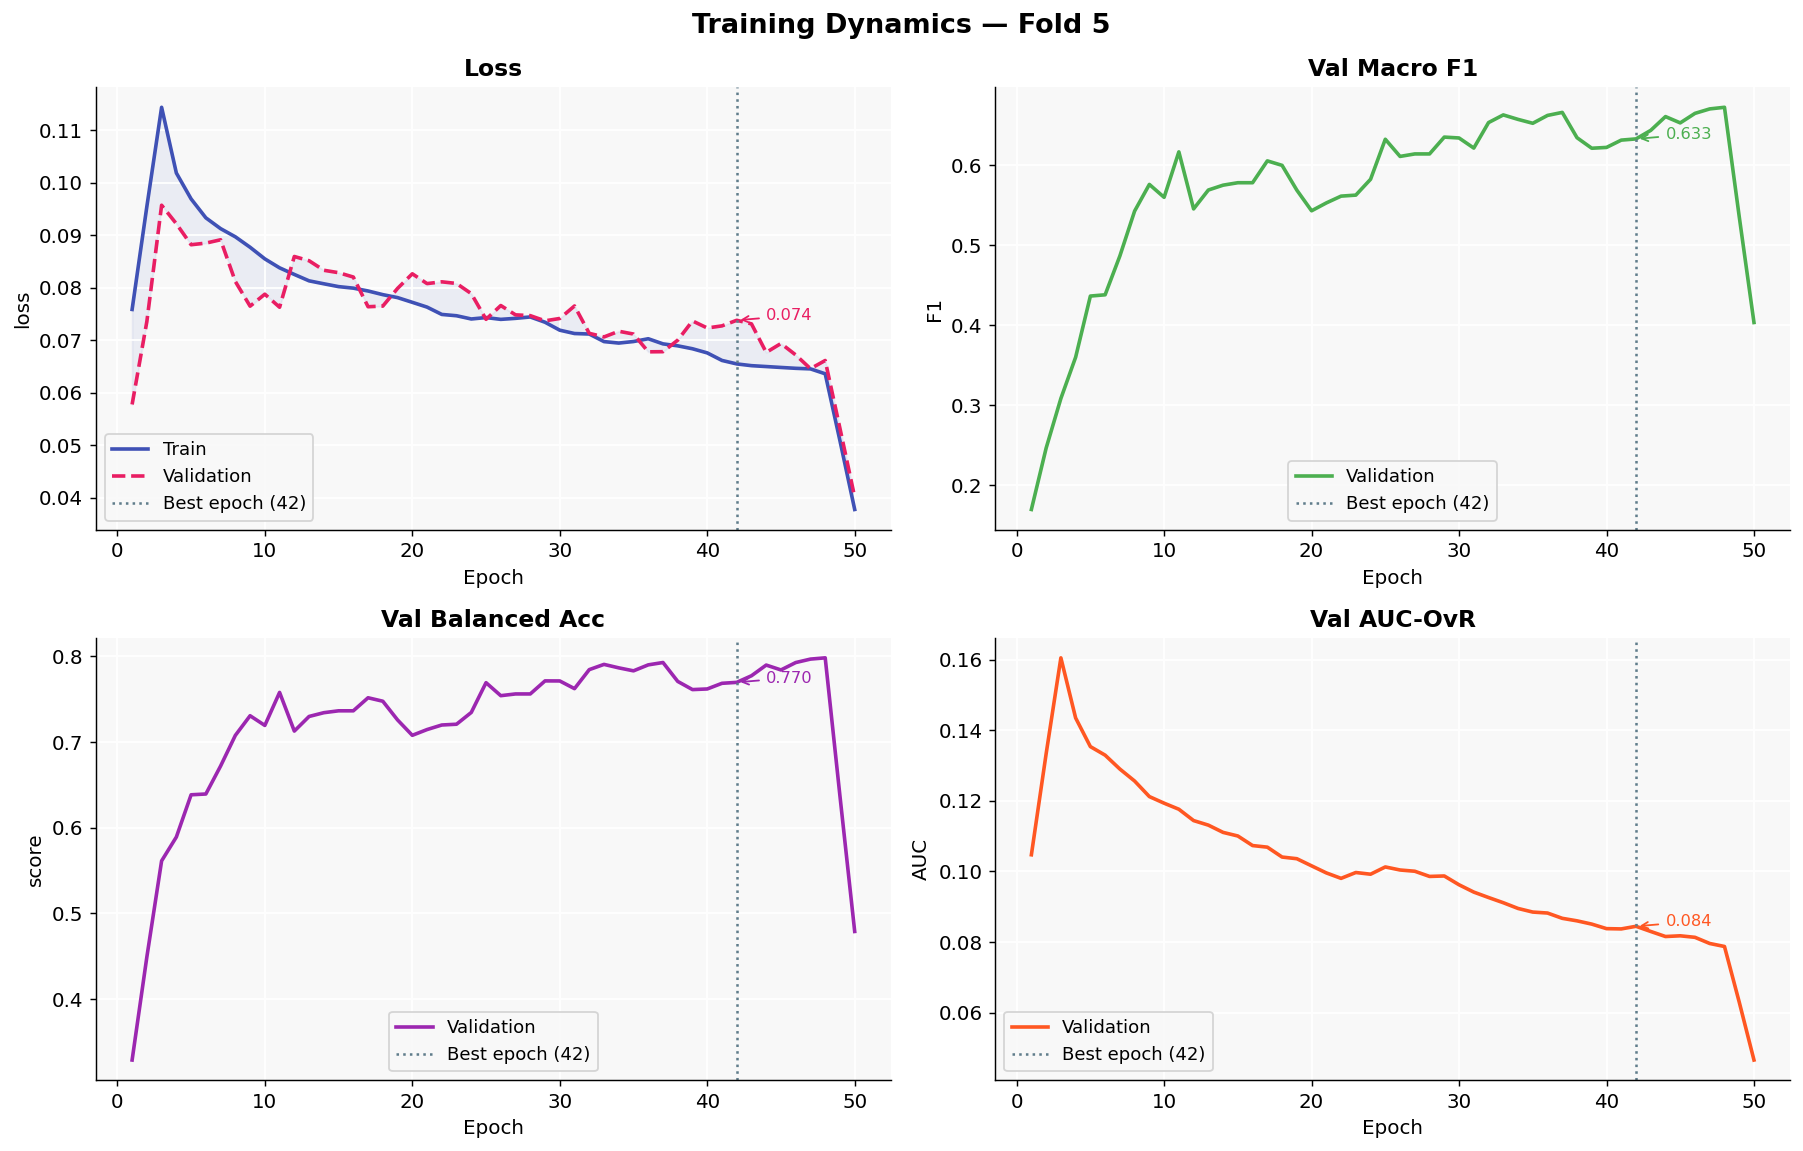

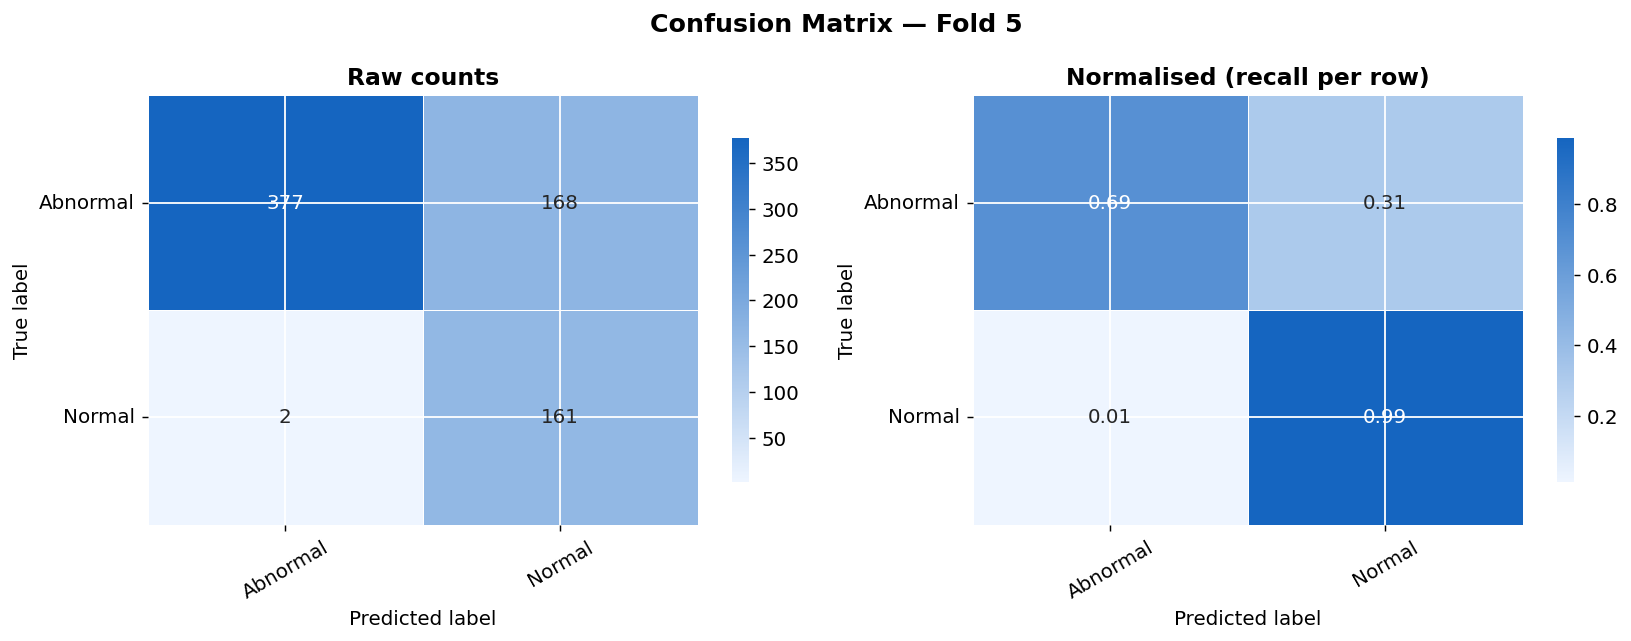

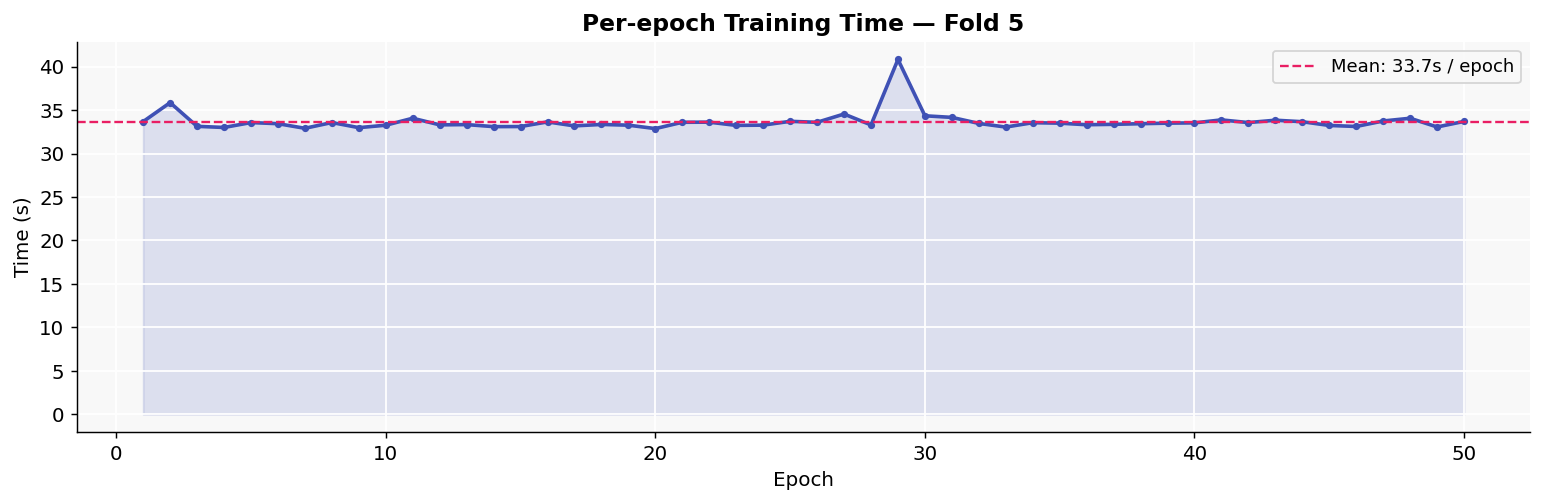


  [SIMPLE_CNN] CROSS-VALIDATION SUMMARY
 fold       f1  bal_acc      auc
    1 0.691068 0.786675 0.175073
    2 0.724838 0.832397 0.066742
    3 0.720339 0.806281 0.127641
    4 0.706799 0.819553 0.130692
    5 0.735244 0.839737 0.092103

  Mean F1     : 0.7157 ± 0.0171
  Mean BalAcc : 0.8169 ± 0.0212
  Mean AUC    : 0.1185 ± 0.0413
  Saved → ./outputs_new/cv_results_simple_cnn.csv


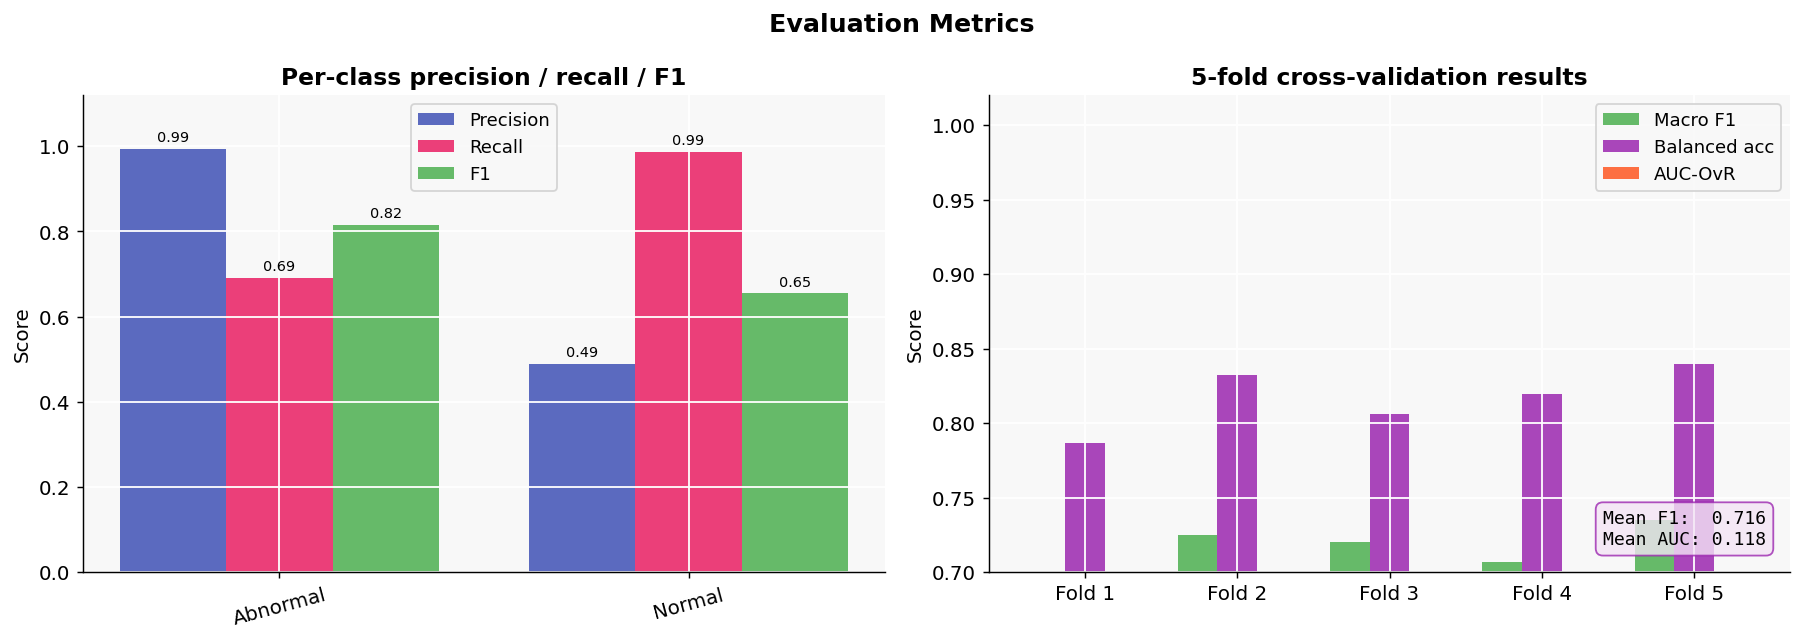

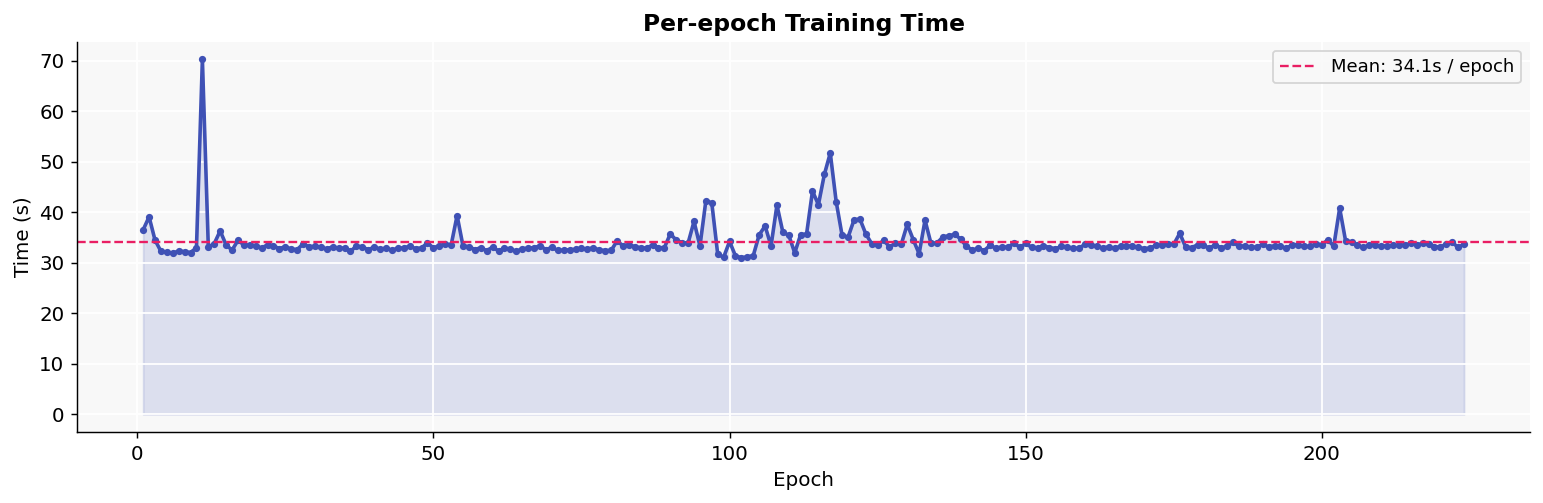

In [35]:
# ── Train baseline ────────────────────────────────────────────────────────────
print("\n" + "█"*60)
print("Simple CNN (baseline)")
print("█"*60)
cnn_results, _, _, _ = run_training(
    filepaths, labels_enc, n_classes, label_names,
    model_type="simple_cnn"
)

# Compare

In [36]:
# # ── Train proposed model ──────────────────────────────────────────────────────
# print("\n" + "█"*60)
# print("  MODEL 2 OF 2 — CNN + LSTM (proposed)")
# print("█"*60)
# results_df, best_preds, best_targets, best_fold = run_training(
#     filepaths, labels_enc, n_classes, label_names,
#     model_type="cnn_lstm"
# )


# ── Load CNN+LSTM results from already trained model ─────────────────────
results_df = pd.read_csv(os.path.join(cfg.OUTPUT_DIR, "cv_results_cnn_lstm.csv"))
print(results_df)

   fold        f1   bal_acc       auc
0     1  0.716998  0.828144  0.119188
1     2  0.730032  0.836067  0.120212
2     3  0.726135  0.833315  0.121765
3     4  0.739971  0.841256  0.102099
4     5  0.745415  0.850459  0.056948



  FINAL MODEL COMPARISON
Metric                 Simple CNN     CNN+LSTM          Δ
-------------------------------------------------------
Macro F1                   0.7157       0.7317 ▲  0.0161
Balanced Acc               0.8169       0.8378 ▲  0.0209
AUC-ROC                    0.1185       0.1040 ▼  0.0144


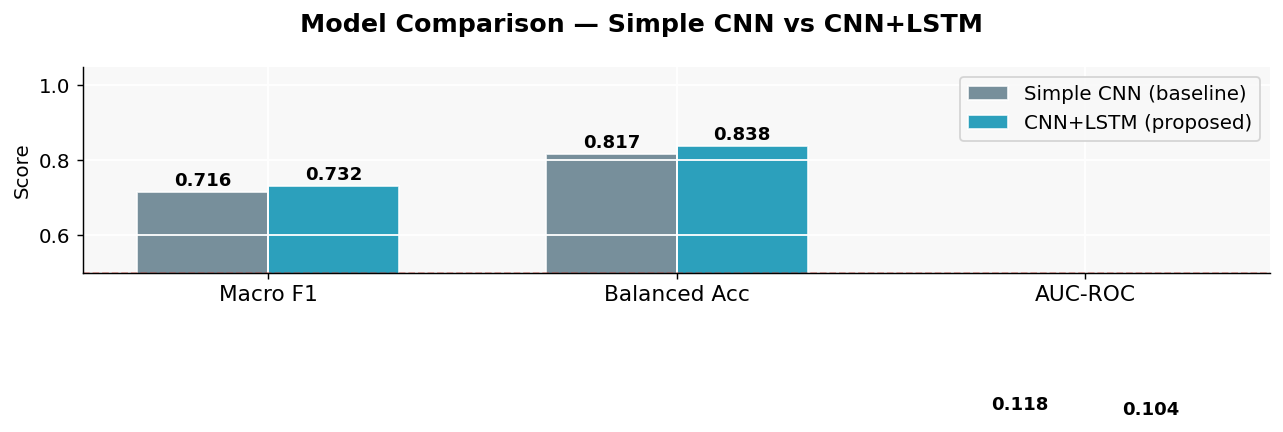


Comparison chart saved → ./outputs_new/comparison_cnn_vs_cnnlstm.png


In [37]:
# ── Comparison summary ────────────────────────────────────────────────────────
print("\n" + "="*60)
print("  FINAL MODEL COMPARISON")
print("="*60)
print(f"{'Metric':<20} {'Simple CNN':>12} {'CNN+LSTM':>12} {'Δ':>10}")
print("-"*55)
for col, label in [("f1", "Macro F1"), ("bal_acc", "Balanced Acc"), ("auc", "AUC-ROC")]:
    cnn_mean  = cnn_results[col].mean()
    lstm_mean = results_df[col].mean()
    delta     = lstm_mean - cnn_mean
    arrow     = "▲" if delta > 0 else "▼"
    print(f"{label:<20} {cnn_mean:>12.4f} {lstm_mean:>12.4f} {arrow}{abs(delta):>8.4f}")

# ── Comparison bar chart ──────────────────────────────────────────────────────
metrics      = ["Macro F1", "Balanced Acc", "AUC-ROC"]
cnn_vals     = [cnn_results["f1"].mean(),     cnn_results["bal_acc"].mean(),  cnn_results["auc"].mean()]
lstm_vals    = [results_df["f1"].mean(),      results_df["bal_acc"].mean(),   results_df["auc"].mean()]

x  = np.arange(len(metrics)); w = 0.32
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle("Model Comparison — Simple CNN vs CNN+LSTM",
             fontsize=14, fontweight="bold")

bars1 = ax.bar(x - w/2, cnn_vals,  w, label="Simple CNN (baseline)",
               color="#607D8B", alpha=0.85, edgecolor="white")
bars2 = ax.bar(x + w/2, lstm_vals, w, label="CNN+LSTM (proposed)",
               color="#0891B2", alpha=0.85, edgecolor="white")

for bar, v in list(zip(bars1, cnn_vals)) + list(zip(bars2, lstm_vals)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{v:.3f}", ha="center", va="bottom",
            fontsize=10, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Score")
ax.legend(fontsize=11)
ax.axhline(0.5, color="#F44336", linestyle="--", linewidth=1.0,
           alpha=0.4, label="Random chance")

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "comparison_cnn_vs_cnnlstm.png"),
            bbox_inches="tight")
plt.show()

print(f"\nComparison chart saved → {cfg.OUTPUT_DIR}/comparison_cnn_vs_cnnlstm.png")